<a href="https://colab.research.google.com/github/ersumanmahato-debug/Database-2026/blob/main/GHI_Thesis_All_Figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# All figures for the thesis: hourly GHI estimation across Nepal's physiographic regions
One notebook, from raw data to every figure in the paper, in paper order.

| Part | Content | Figures |
|---|---|---|
| 1 | Load MERRA-2 + GHI target, units, solar geometry, clear-sky, descriptive analysis (**RO1**) | m01–m13 |
| 2 | Study area and research design (**Chapter 3**) | D1–D5 |
| 3 | Models, validation, interpretation and uncertainty (**RO2–RO4, RQ1–RQ2, H1–H2**) | R0–R23 |
| 4 | Paper figure set: renumbered copies in `figures/paper/`, `Figure_list.csv`, `List_of_Figures.docx` | — |
| 5 | `results/Results_Chapter_Draft.docx`: every results figure with caption and a paragraph filled with your numbers | — |

**Before running:** put MERRA-2 files in `data/raw/<Site>/` and all-sky GHI files in `data/raw_ghi/<Site>/`, edit the
settings cell, and choose *Runtime → Change runtime type → GPU*. A full run takes about 1–2 h; afterwards set
`RETRAIN = False` to redraw every figure in minutes from cached predictions.

**Main-text figures (default numbering):** Chapter 3 — study area (D1), target grid cells (D2), site characteristics (D3),
workflow (D4), validation design (D5), LSTM window (R0). Chapter 4 — completeness, annual cycle, correlation, target
independence, model skill, observed vs estimated, paired skill, seasonal skill, protocol optimism, generalization penalty,
H1 test, area of applicability, ablation, leakage, data-limited conditions, SHAP (global, seasonal), error surface,
interval reliability, H2 test. All other figures go to the appendix.

In [1]:
!pip install -q pvlib openpyxl lightgbm xgboost shap optuna python-docx rasterio

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ======================= SETTINGS (edit this cell only) =======================
from pathlib import Path
ROOT = Path('/content/drive/My Drive/GHI_Nepal_MSc_Research')        # project folder on Google Drive

# Study sites (proposal, study-area table)
SITE_INFO = {
    'Bharatpur': dict(lat=27.68, lon=84.43, alt=200,  zone='Terai'),
    'Pokhara':   dict(lat=28.21, lon=83.99, alt=820,  zone='Middle Mountains'),
    'Jomsom':    dict(lat=28.78, lon=83.72, alt=2720, zone='High Mountains'),
}
# Words in file names / Source.Name that identify each site
SITE_KEYS = {'bharatpur': 'Bharatpur', 'chitwan': 'Bharatpur', 'pokhara': 'Pokhara', 'kaski': 'Pokhara',
             'jomsom': 'Jomsom', 'mustang': 'Jomsom'}
# Slope and aspect (degrees) from NASADEM for each site; None = not used as predictors
SLOPE_ASPECT = {'Bharatpur': (None, None), 'Pokhara': (None, None), 'Jomsom': (None, None)}

# GHI target product. CERES SYN1deg (1°) puts Pokhara and Jomsom in ONE cell → the run stops (see Fig D2 / R0b).
TARGET_GRID = dict(name='CERES SYN1deg', dlat=1.0, dlon=1.0, mode='edges')
# TARGET_GRID = dict(name='MERRA-2 SWGDN', dlat=0.5, dlon=0.625, mode='centres')
# TARGET_GRID = dict(name='ERA5', dlat=0.25, dlon=0.25, mode='centres')
GHI_STAMP = 'center'          # 'center' (MERRA-2, ERA5 accumulations re-labelled to mid-hour) or 'start' (CERES SYN1deg, NASA POWER)
ALLOW_SHARED_TARGET = False   # True only to run anyway; LORO results for sites sharing a target are then flagged invalid

# Maps (Part 2)
DEM_FILE = None               # e.g. ROOT / 'data' / 'static' / 'nasadem_nepal.tif'; None → ETOPO1 downloaded from NOAA ERDDAP
BOUNDARY_FILE = None          # e.g. a Nepal boundary GeoJSON/shapefile; None → Natural Earth

# Modelling (Part 3)
RETRAIN     = True            # False → reuse cached predictions and only redraw figures
N_TRIALS    = 25              # Optuna trials per fold (XGBoost, LightGBM)
N_SEEDS     = 3               # random seeds for MLP and LSTM
RUN_DL      = True            # train MLP and LSTM (GPU runtime recommended)
TUNE_DL     = True            # configuration search for MLP/LSTM on the validation year
N_BOOT      = 500             # day-block bootstrap resamples
MAKE_REPORT = True            # write results/Results_Chapter_Draft.docx
STRIP_FIG_NUMBERS = True      # remove 'Fig R1.'-style prefixes from titles inside images (paper captions carry the numbers)

# Part 1. Data, pre-processing and descriptive analysis (Objective 1)
Loads every MERRA-2 file under `data/raw/`, converts units, derives predictors, computes solar geometry and clear-sky
irradiance, merges the all-sky GHI target from `data/raw_ghi/<Site>/`, and draws the descriptive figures m01–m13.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from pathlib import Path
import pvlib, re

# ---------------- CONFIGURATION (paths derived from the settings cell) ----------------
RAW_DIR  = ROOT / 'data' / 'raw'        # MERRA-2 files (any sub-folders, .xlsx or .csv)
GHI_DIR  = ROOT / 'data' / 'raw_ghi'    # OPTIONAL all-sky GHI files: raw_ghi/<Site>/*.csv|xlsx
OUT_DIR  = ROOT / 'data' / 'processed'
FIG_DIR  = ROOT / 'figures'
for d in (OUT_DIR, FIG_DIR): d.mkdir(parents=True, exist_ok=True)

SITES = SITE_INFO               # coordinates used for solar geometry (MERRA-2 cell centres stay in lat/lon columns)
YEAR0, YEAR1 = 2019, 2025
ZENITH_MAX = 85.0
LOCAL_TZ = 'Asia/Kathmandu'

SEASON_OF = {12:'Winter',1:'Winter',2:'Winter',3:'Pre-Monsoon',4:'Pre-Monsoon',5:'Pre-Monsoon',
             6:'Monsoon',7:'Monsoon',8:'Monsoon',9:'Monsoon',10:'Post-Monsoon',11:'Post-Monsoon'}
SEASONS = ['Winter', 'Pre-Monsoon', 'Monsoon', 'Post-Monsoon']
SITE_ORDER = list(SITES)
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

# ---------------- PLOT STYLE (colour-blind checked; each site/component keeps one colour) ----------------
SITE_C  = {'Bharatpur': '#2a78d6', 'Pokhara': '#eb6834', 'Jomsom': '#1baf7a'}
SITE_LS = {'Bharatpur': '-', 'Pokhara': '--', 'Jomsom': '-.'}
COMP_C  = {'GHI': '#6250d6', 'DHI': '#c98500', 'DNI': '#d55181'}
COMP_LS = {'GHI': '-', 'DHI': '--', 'DNI': ':'}
SEQ = LinearSegmentedColormap.from_list('seq', ['#f4f8fd', '#cde2fb', '#86b6ef', '#2a78d6', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#f2a27e', '#b8441a'])
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e6e5e0'
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.edgecolor': INK2, 'xtick.color': INK2,
    'ytick.color': INK2, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True, 'lines.linewidth': 2,
    'legend.frameon': False, 'legend.fontsize': 9})

_FIGNUM_RE = re.compile(r'^Fig\s+[A-Z]?\d+[a-z]?\.\s+')
def strip_fig_numbers(fig):
    """Remove 'Fig R1.'-style prefixes from in-image titles; the paper caption carries the number."""
    if fig._suptitle is not None: fig._suptitle.set_text(_FIGNUM_RE.sub('', fig._suptitle.get_text()))
    for a in fig.axes:
        for t in (a.title, a._left_title, a._right_title): t.set_text(_FIGNUM_RE.sub('', t.get_text()))
def save(fig, name):
    if STRIP_FIG_NUMBERS: strip_fig_numbers(fig)
    fig.savefig(FIG_DIR / f'{name}.png'); fig.savefig(FIG_DIR / f'{name}.pdf'); plt.show()

def suptitle(fig, text):
    fig.suptitle(text, fontweight='bold', x=0.01, ha='left')

## 1. Load all MERRA-2 files

In [5]:
def site_from_text(text):
    t = str(text).lower()
    for k, s in SITE_KEYS.items():
        if k in t:
            return s
    return None

def read_any(path):
    return pd.read_excel(path) if path.suffix.lower() in ('.xlsx', '.xls') else pd.read_csv(path)

def parse_time(col):
    """MERRA-2 times are UTC, centred on the half hour (00:30 = mean of 00:00–01:00)."""
    if pd.api.types.is_datetime64_any_dtype(col):
        return pd.to_datetime(col)
    for fmt in ('%m/%d/%y %H:%M', '%m/%d/%Y %H:%M', '%Y-%m-%d %H:%M:%S', '%Y-%m-%d %H:%M'):
        try:
            return pd.to_datetime(col.astype(str).str.strip(), format=fmt)
        except (ValueError, TypeError):
            pass
    return pd.to_datetime(col)          # last resort

files = sorted([p for p in RAW_DIR.rglob('*') if p.suffix.lower() in ('.xlsx', '.xls', '.csv') and not p.name.startswith('~$')])
print(f'{len(files)} file(s) found under {RAW_DIR}')
parts = []
for f in files:
    d = read_any(f)
    d.columns = [str(c).strip() for c in d.columns]
    if 'T2M' not in d.columns:                    # not a MERRA-2 SLV file
        print('  skipped (no T2M column):', f.name); continue
    src = d['Source.Name'] if 'Source.Name' in d.columns else pd.Series(f.name, index=d.index)
    d['site'] = src.map(site_from_text).fillna(site_from_text(f.as_posix()))
    if d['site'].isna().any():
        print(f'  WARNING: cannot tell the site for some rows of {f.name}; add a keyword to SITE_KEYS')
    d['time_utc'] = parse_time(d['time']).dt.tz_localize('UTC')
    parts.append(d)
    print(f'  {f.name}: {len(d):,} rows, sites {sorted(d.site.dropna().unique())}')

met = pd.concat(parts, ignore_index=True).dropna(subset=['site'])
met = (met.drop(columns=[c for c in ['Source.Name', 'time', 'Hour', 'Month', 'Season'] if c in met.columns])
          .drop_duplicates(['site', 'time_utc']).sort_values(['site', 'time_utc']).reset_index(drop=True))
print('\nRows per site:\n', met.groupby('site').size())
print('MERRA-2 grid cells used:\n', met.groupby('site')[['lat', 'lon']].first())

21 file(s) found under /content/drive/My Drive/GHI_Nepal_MSc_Research/data/raw
  bharatpur_2019.xlsx: 288 rows, sites ['Bharatpur']
  bharatpur_2020.xlsx: 288 rows, sites ['Bharatpur']
  bharatpur_2021.xlsx: 288 rows, sites ['Bharatpur']
  bharatpur_2022.xlsx: 288 rows, sites ['Bharatpur']
  bharatpur_2023.xlsx: 288 rows, sites ['Bharatpur']
  bharatpur_2024.xlsx: 288 rows, sites ['Bharatpur']
  bharatpur_2025.xlsx: 288 rows, sites ['Bharatpur']
  jomsom_2019.xlsx: 288 rows, sites ['Jomsom']
  jomsom_2020.xlsx: 288 rows, sites ['Jomsom']
  jomsom_2021.xlsx: 288 rows, sites ['Jomsom']
  jomsom_2022.xlsx: 288 rows, sites ['Jomsom']
  jomsom_2023.xlsx: 288 rows, sites ['Jomsom']
  jomsom_2024.xlsx: 288 rows, sites ['Jomsom']
  jomsom_2025.xlsx: 288 rows, sites ['Jomsom']
  pokhara_2019.xlsx: 288 rows, sites ['Pokhara']
  pokhara_2020.xlsx: 288 rows, sites ['Pokhara']
  pokhara_2021.xlsx: 288 rows, sites ['Pokhara']
  pokhara_2022.xlsx: 288 rows, sites ['Pokhara']
  pokhara_2023.xlsx: 288 

## 2. Unit conversion and derived meteorological predictors

In [6]:
m = met.copy()
for c in ['T2M', 'T2MDEW', 'T2MWET', 'CLDTMP']:                       # K → °C
    if c in m: m[c + '_C'] = m[c] - 273.15
m['PS_hPa']   = m['PS'] / 100.0                                        # Pa → hPa
m['TQV_cm']   = m['TQV'] / 10.0                                        # kg m⁻² (= mm) → cm precipitable water
m['CLDPRS_hPa'] = m['CLDPRS'] / 100.0                                  # cloud-top pressure, Pa → hPa
# Relative humidity from T and Td (Magnus formula)
es = lambda t: 6.112 * np.exp(17.62 * t / (243.12 + t))
m['RH2M'] = (100 * es(m['T2MDEW_C']) / es(m['T2M_C'])).clip(0, 100)
# 10-m wind speed and direction (meteorological convention: direction the wind blows FROM)
m['WS10M'] = np.hypot(m['U10M'], m['V10M'])
m['WD10M'] = (np.degrees(np.arctan2(-m['U10M'], -m['V10M'])) + 360) % 360
# Cloud flag: MERRA-2 leaves CLDPRS/CLDTMP empty when there is no cloud in the column
m['cloud'] = m['CLDPRS'].notna().astype(int)

# Local time (Nepal Time, UTC+05:45) and calendar features
lt = m['time_utc'].dt.tz_convert(LOCAL_TZ)
m['time_local'] = lt.dt.tz_localize(None)
m['hour'], m['month'], m['year'], m['doy'] = lt.dt.hour, lt.dt.month, lt.dt.year, lt.dt.dayofyear
m['season'] = pd.Categorical(m['month'].map(SEASON_OF), SEASONS, ordered=True)
m = m[m.year.between(YEAR0, YEAR1)]
m[['site', 'time_local', 'T2M_C', 'RH2M', 'PS_hPa', 'TQV', 'WS10M', 'WD10M', 'cloud']].head()

,site,time_local,T2M_C,RH2M,PS_hPa,TQV,WS10M,WD10M,cloud
0,Bharatpur,2019-01-01 06:15:00,9.68423,44.017392,977.00060,9.026967,1.710144,55.579626,0
1,Bharatpur,2019-01-01 07:15:00,9.86837,44.080077,978.17540,9.105938,1.789626,59.512682,0
2,Bharatpur,2019-01-01 08:15:00,12.80105,41.841554,979.21120,9.174022,1.620148,61.127987,0
3,Bharatpur,2019-01-01 09:15:00,16.43774,31.005501,979.98695,9.325642,1.132349,70.517580,0
4,Bharatpur,2019-01-01 10:15:00,19.35137,26.396728,980.19140,9.551302,0.470604,206.325187,0


## 3. Solar geometry and clear-sky GHI / DNI / DHI (Ineichen–Perez)

In [7]:
def add_solar(df, lat, lon, alt):
    t = pd.DatetimeIndex(df['time_utc'])            # already the middle of the hour (xx:30 UTC)
    pres = df['PS'].fillna(pvlib.atmosphere.alt2pres(alt)).values
    sp = pvlib.solarposition.get_solarposition(t, lat, lon, altitude=alt, pressure=pres)
    cs = pvlib.location.Location(lat, lon, altitude=alt).get_clearsky(t, model='ineichen', solar_position=sp)
    out = df.copy()
    out['zenith'], out['azimuth'] = sp['zenith'].values, sp['azimuth'].values
    out['elevation'] = sp['apparent_elevation'].values
    out['cos_zenith'] = np.cos(np.radians(out['zenith']))
    out['dni_extra'] = pvlib.irradiance.get_extra_radiation(t).values
    out['GHI_TOA'] = (out['dni_extra'] * out['cos_zenith']).clip(lower=0)
    out['declination'] = np.degrees(pvlib.solarposition.declination_spencer71(t.dayofyear))
    out['equation_of_time'] = pvlib.solarposition.equation_of_time_spencer71(t.dayofyear)
    out['GHI_cs'], out['DNI_cs'], out['DHI_cs'] = cs['ghi'].values, cs['dni'].values, cs['dhi'].values
    out['is_day'] = out['zenith'] < ZENITH_MAX
    return out

data = pd.concat([add_solar(m[m.site == s], **{k: SITES[s][k] for k in ('lat', 'lon', 'alt')})
                  for s in SITE_ORDER if s in m.site.unique()], ignore_index=True)
data[data.is_day][['site', 'time_local', 'zenith', 'GHI_cs', 'DNI_cs', 'DHI_cs']].head()

,site,time_local,zenith,GHI_cs,DNI_cs,DHI_cs
2,Bharatpur,2019-01-01 08:15:00,76.148877,198.099479,699.069231,29.987085
3,Bharatpur,2019-01-01 09:15:00,66.069857,394.560984,861.211978,44.735351
4,Bharatpur,2019-01-01 10:15:00,57.869403,547.698910,926.489722,54.591184
5,Bharatpur,2019-01-01 11:15:00,52.447618,642.593912,954.790754,60.383012
6,Bharatpur,2019-01-01 12:15:00,50.710415,671.698529,962.215822,62.127217


## 4. All-sky GHI → DHI & DNI (only runs if GHI files exist in `raw_ghi/<Site>/`)
Each GHI file needs a time column (UTC) and one GHI column named `GHI`, `SWGDN` (MERRA-2 RAD),
`sfc_comp_sw_down_all` (CERES SYN1deg) or `ALLSKY_SFC_SW_DWN` (NASA POWER).

In [8]:
GHI_NAMES = ['GHI', 'SWGDN', 'sfc_comp_sw_down_all', 'ALLSKY_SFC_SW_DWN', 'Solar_Irradiance']
# Timestamp label of the GHI source: 'center' (MERRA-2, xx:30) or 'start' (CERES SYN1deg / NASA POWER, xx:00 = xx:00–xx:59)
# GHI_STAMP is set in the settings cell

def load_ghi(site):
    folder = GHI_DIR / site
    fs = sorted([p for p in folder.glob('*') if p.suffix.lower() in ('.csv', '.xlsx', '.xls')]) if folder.exists() else []
    if not fs: return None
    g = pd.concat([read_any(f) for f in fs])
    g.columns = [str(c).strip() for c in g.columns]
    gcol = next((c for c in GHI_NAMES if c in g.columns), None)
    tcol = next((c for c in ['time', 'datetime', 'timestamp', 'date'] if c in g.columns), None)
    if gcol is None or tcol is None:
        print(f'{site}: GHI file found but no recognised time/GHI column: {g.columns.tolist()}'); return None
    t = parse_time(g[tcol]); t = t.dt.tz_localize('UTC') if t.dt.tz is None else t.dt.tz_convert('UTC')
    if GHI_STAMP == 'start': t = t + pd.Timedelta('30min')          # align to MERRA-2 half-hour centres
    return pd.DataFrame({'time_utc': t, 'GHI': pd.to_numeric(g[gcol], errors='coerce').replace(-999, np.nan)}).drop_duplicates('time_utc')

merged = []
for s in data.site.unique():
    d = data[data.site == s]
    g = load_ghi(s)
    if g is not None:
        d = d.merge(g, on='time_utc', how='left')
        print(f'{s}: all-sky GHI matched for {d.GHI.notna().mean():.1%} of hours')
    merged.append(d)
data = pd.concat(merged, ignore_index=True)
HAS_GHI = 'GHI' in data and data['GHI'].notna().any()

if HAS_GHI:
    day = data['is_day']
    data.loc[~day, 'GHI'] = 0.0
    ti = pd.DatetimeIndex(data['time_utc'])
    erbs = pvlib.irradiance.erbs(pd.Series(data['GHI'].clip(lower=0).values, index=ti),
                                 pd.Series(data['zenith'].values, index=ti), ti)
    dni = np.minimum(np.minimum(np.clip(erbs['dni'].values, 0, None), data['DNI_cs'].values * 1.05), data['dni_extra'].values)
    data['DNI'] = np.where(day, dni, 0.0)
    data['DHI'] = np.where(day, (data['GHI'] - data['DNI'] * data['cos_zenith']).clip(lower=0), 0.0)
    data['kt'] = np.where(day, data['GHI'] / data['GHI_TOA'].replace(0, np.nan), np.nan)
    data['kc'] = np.where(day, data['GHI'] / data['GHI_cs'].replace(0, np.nan), np.nan)
    data['k_d'] = np.where(day & (data['GHI'] > 0), data['DHI'] / data['GHI'], np.nan)
    print('All-sky GHI, DHI and DNI computed.')
else:
    print('No all-sky GHI files found → figures use clear-sky GHI/DNI/DHI and meteorology only.')

data.to_csv(OUT_DIR / 'merra2_3sites_processed.csv', index=False)
print('Saved', OUT_DIR / 'merra2_3sites_processed.csv', data.shape)

No all-sky GHI files found → figures use clear-sky GHI/DNI/DHI and meteorology only.
Saved /content/drive/My Drive/GHI_Nepal_MSc_Research/data/processed/merra2_3sites_processed.csv (5496, 45)


## 5. Visualization

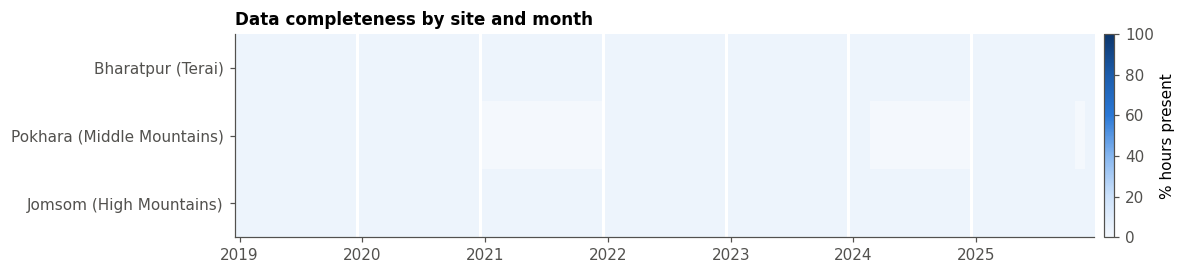

Mean completeness %:
 Bharatpur    3.3
Pokhara      2.4
Jomsom       3.3
dtype: float64


In [9]:
SITES_IN = [s for s in SITE_ORDER if s in data.site.unique()]

# Fig 1 – data completeness (share of expected hours present per month)
full = pd.date_range(f'{YEAR0}-01-01', f'{YEAR1}-12-31 23:00', freq='h')
avail = pd.concat({s: (pd.Series(1, index=data[data.site == s].time_local).resample('MS').sum()
                       .reindex(pd.Series(1, index=full).resample('MS').sum().index, fill_value=0)
                       / pd.Series(1, index=full).resample('MS').sum() * 100) for s in SITES_IN}, axis=1)
fig, ax = plt.subplots(figsize=(12, 2.4))
im = ax.imshow(avail.T.values, aspect='auto', cmap=SEQ, vmin=0, vmax=100, interpolation='nearest')
ax.set_yticks(range(len(SITES_IN)), [f'{s} ({SITES[s]["zone"]})' for s in SITES_IN])
yi = [i for i, t in enumerate(avail.index) if t.month == 1]
ax.set_xticks(yi, [avail.index[i].year for i in yi]); ax.grid(False)
for i in yi[1:]: ax.axvline(i - 0.5, color='white', lw=2)
fig.colorbar(im, ax=ax, pad=0.01).set_label('% hours present')
ax.set_title('Fig 1. Data completeness by site and month', loc='left')
save(fig, 'm01_completeness')
print('Mean completeness %:\n', avail.mean().round(1))

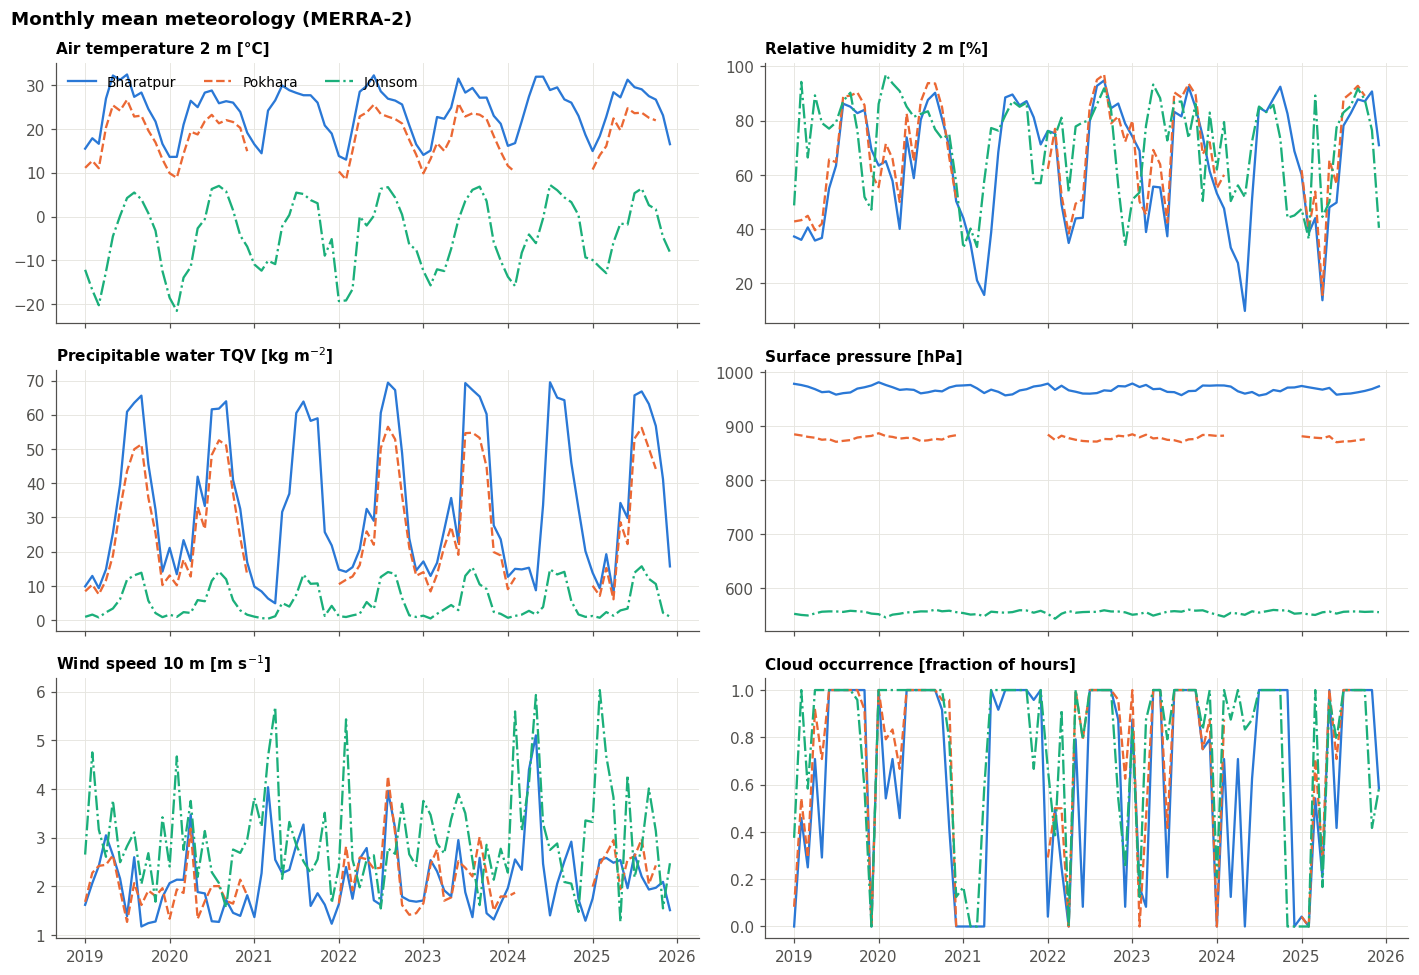

In [10]:
# Fig 2 – monthly means of the main meteorological variables over the record
VARS = [('T2M_C', 'Air temperature 2 m [°C]'), ('RH2M', 'Relative humidity 2 m [%]'),
        ('TQV', 'Precipitable water TQV [kg m$^{-2}$]'), ('PS_hPa', 'Surface pressure [hPa]'),
        ('WS10M', 'Wind speed 10 m [m s$^{-1}$]'), ('cloud', 'Cloud occurrence [fraction of hours]')]
mon = data.set_index('time_local').groupby('site')[[v for v, _ in VARS]].resample('MS').mean()
fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
for ax, (v, lab) in zip(axes.flat, VARS):
    for s in SITES_IN:
        x = mon.loc[s, v]; ax.plot(x.index, x.values, color=SITE_C[s], ls=SITE_LS[s], lw=1.5, label=s)
    ax.set_title(lab, loc='left', fontsize=10)
axes[0, 0].legend(ncol=3, loc='upper left')
suptitle(fig, 'Fig 2. Monthly mean meteorology (MERRA-2)'); fig.tight_layout(); save(fig, 'm02_monthly_meteorology')

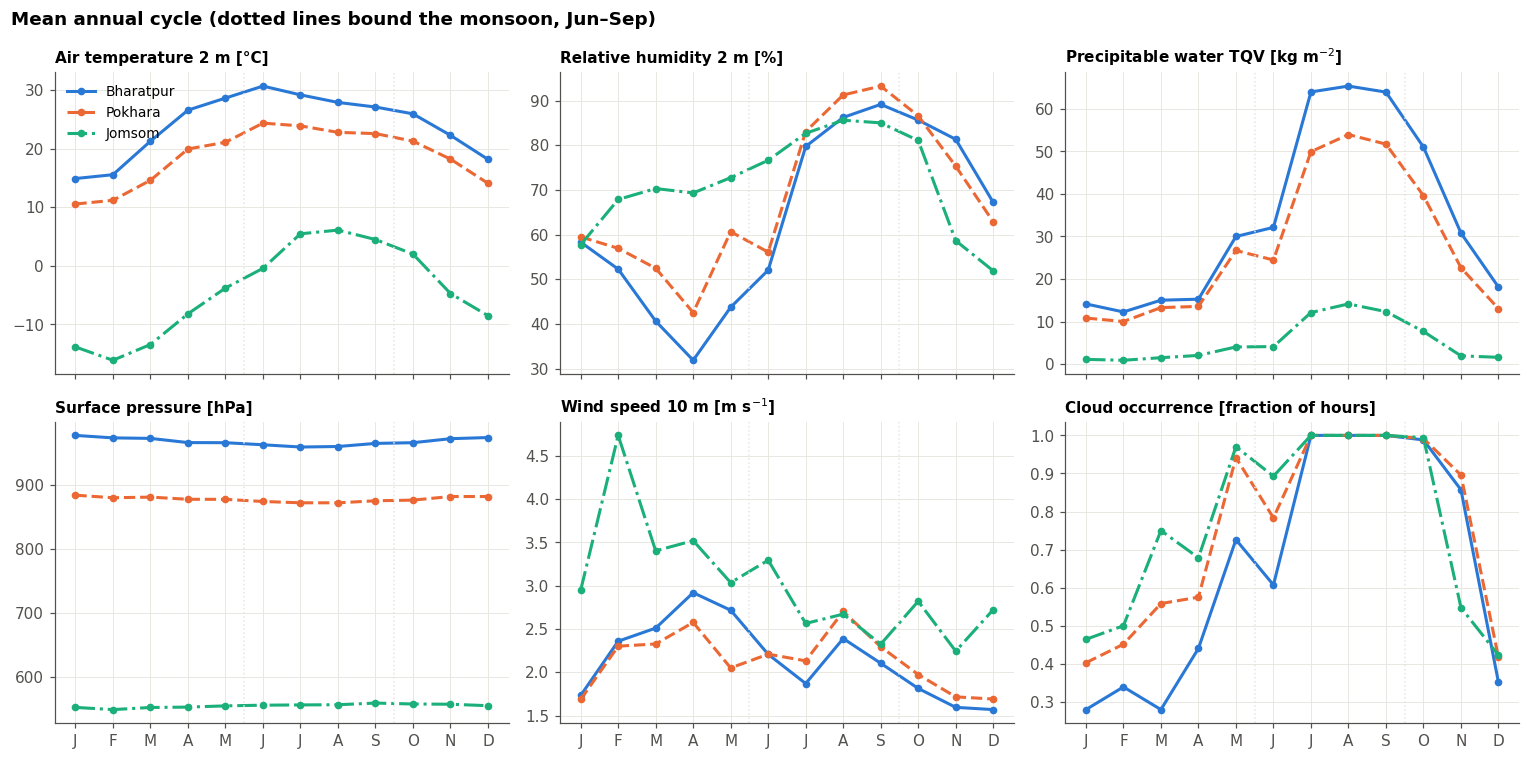

In [11]:
# Fig 3 – mean annual cycle (climatology) of each variable
clim = data.groupby(['site', 'month'])[[v for v, _ in VARS]].mean()
clim.round(3).to_csv(FIG_DIR / 'm03_climatology_table.csv')
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, (v, lab) in zip(axes.flat, VARS):
    for s in SITES_IN:
        ax.plot(range(1, 13), clim.loc[s, v].reindex(range(1, 13)), color=SITE_C[s], ls=SITE_LS[s], marker='o', ms=4, label=s)
    ax.set_title(lab, loc='left', fontsize=10); ax.set_xticks(range(1, 13), [x[0] for x in MONTHS])
    for mo in (5.5, 9.5): ax.axvline(mo, color=GRID, lw=1, ls=':')
axes[0, 0].legend(loc='upper left')
suptitle(fig, 'Fig 3. Mean annual cycle (dotted lines bound the monsoon, Jun–Sep)'); fig.tight_layout(); save(fig, 'm03_annual_cycle')

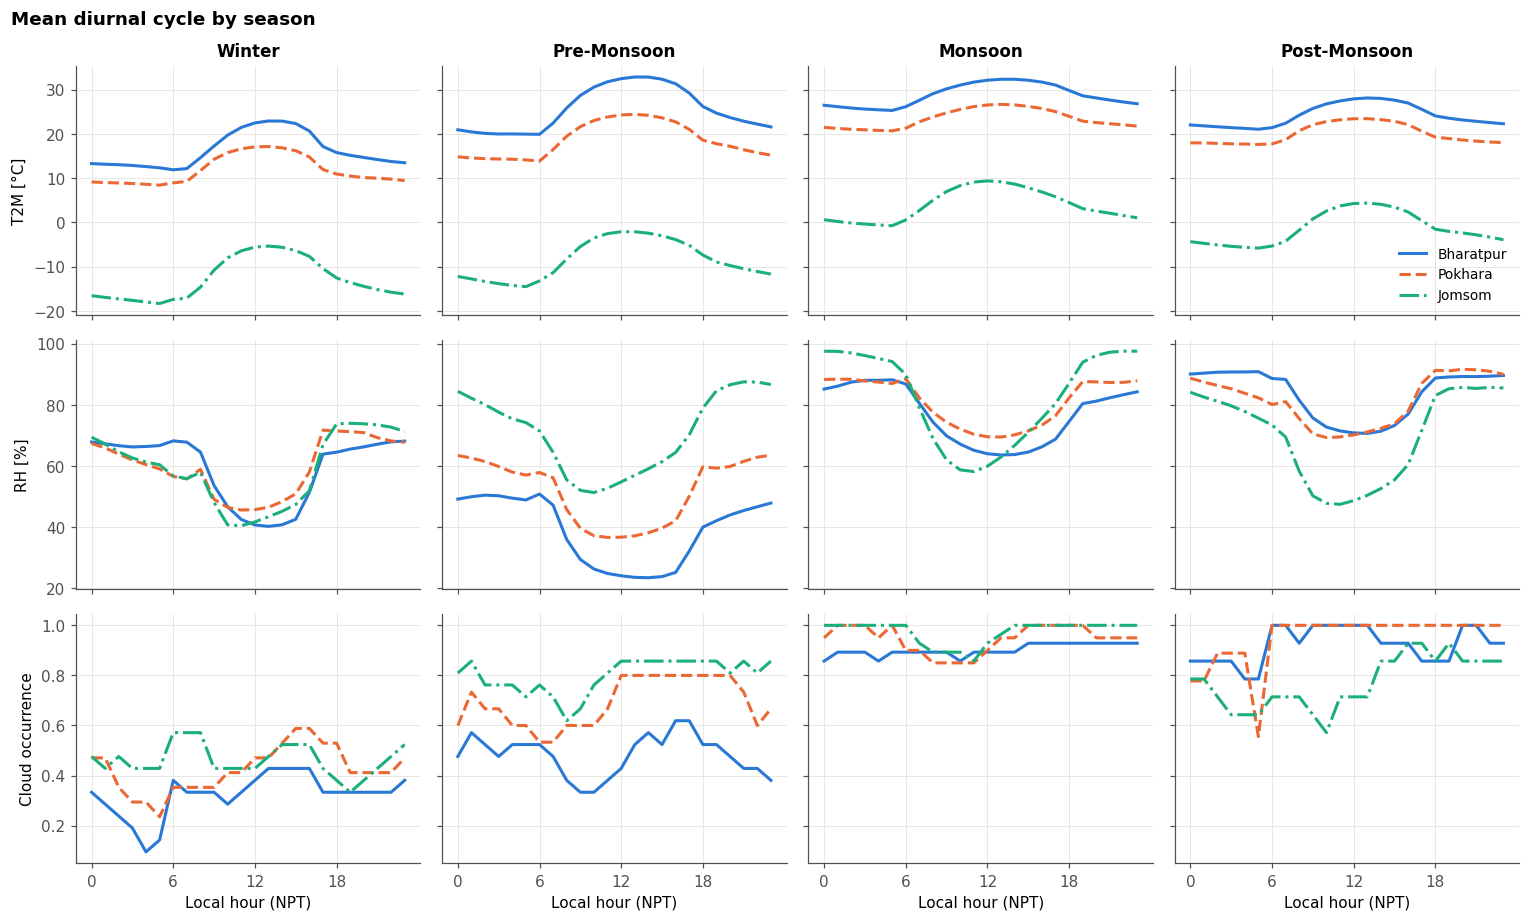

In [12]:
# Fig 4 – mean diurnal cycle by season: temperature, humidity and cloud occurrence
fig, axes = plt.subplots(3, 4, figsize=(14, 8.5), sharex=True, sharey='row')
for r, (v, lab) in enumerate([('T2M_C', 'T2M [°C]'), ('RH2M', 'RH [%]'), ('cloud', 'Cloud occurrence')]):
    g = data.groupby(['season', 'site', 'hour'], observed=True)[v].mean()
    for c, se in enumerate(SEASONS):
        ax = axes[r, c]
        for s in SITES_IN:
            if (se, s) in g.index.droplevel(2):
                x = g.loc[(se, s)]; ax.plot(x.index, x.values, color=SITE_C[s], ls=SITE_LS[s], label=s)
        if r == 0: ax.set_title(se)
        if c == 0: ax.set_ylabel(lab)
        if r == 2: ax.set_xlabel('Local hour (NPT)'); ax.set_xticks(range(0, 24, 6))
axes[0, -1].legend(loc='lower right')
suptitle(fig, 'Fig 4. Mean diurnal cycle by season'); fig.tight_layout(); save(fig, 'm04_diurnal_season')

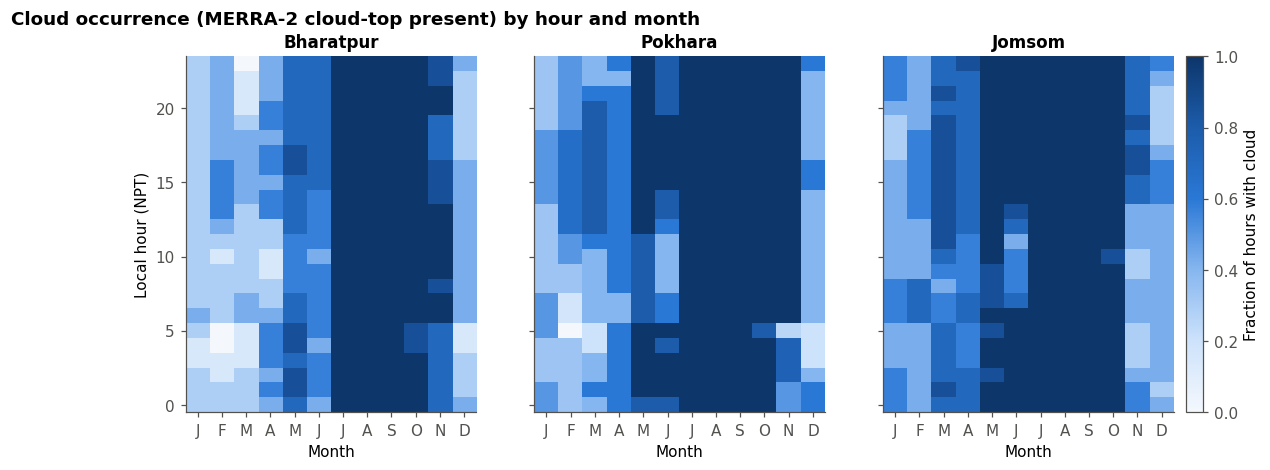

In [13]:
# Fig 5 – cloud occurrence by hour and month (heat map) per site
fig, axes = plt.subplots(1, len(SITES_IN), figsize=(4.6 * len(SITES_IN), 4.2), sharey=True, squeeze=False)
for ax, s in zip(axes[0], SITES_IN):
    h = data[data.site == s].pivot_table(index='hour', columns='month', values='cloud', aggfunc='mean').reindex(columns=range(1, 13))
    im = ax.imshow(h.values, aspect='auto', origin='lower', cmap=SEQ, vmin=0, vmax=1, extent=[0.5, 12.5, -0.5, 23.5])
    ax.set_xticks(range(1, 13), [x[0] for x in MONTHS]); ax.set_title(s); ax.grid(False); ax.set_xlabel('Month')
axes[0, 0].set_ylabel('Local hour (NPT)')
fig.colorbar(im, ax=axes, pad=0.01).set_label('Fraction of hours with cloud')
suptitle(fig, 'Fig 5. Cloud occurrence (MERRA-2 cloud-top present) by hour and month'); save(fig, 'm05_cloud_heatmap')

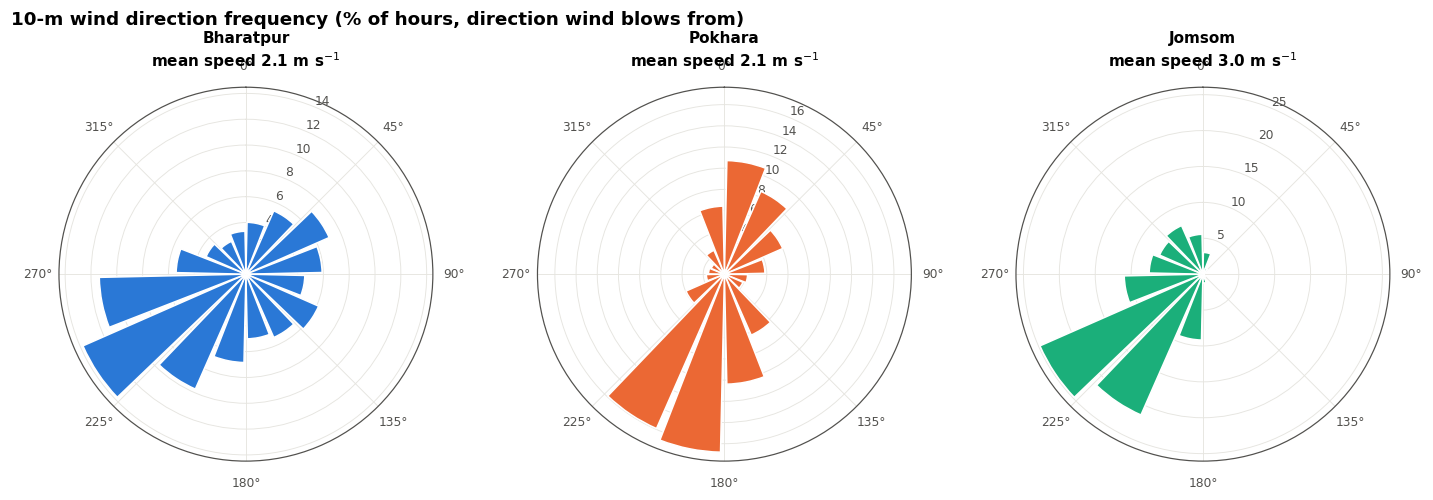

In [14]:
# Fig 6 – wind direction and speed (polar histograms, one per site)
bins = np.arange(0, 361, 22.5)
fig, axes = plt.subplots(1, len(SITES_IN), figsize=(4.4 * len(SITES_IN), 4.4), subplot_kw=dict(projection='polar'), squeeze=False)
for ax, s in zip(axes[0], SITES_IN):
    d = data[data.site == s]
    cnt, _ = np.histogram(d.WD10M, bins=bins, weights=np.ones(len(d)) / len(d) * 100)
    ax.bar(np.radians(bins[:-1] + 11.25), cnt, width=np.radians(20), color=SITE_C[s], edgecolor='white')
    ax.set_theta_zero_location('N'); ax.set_theta_direction(-1)
    ax.set_title(f'{s}\nmean speed {d.WS10M.mean():.1f} m s$^{{-1}}$', pad=14, fontsize=10)
    ax.tick_params(labelsize=8)
suptitle(fig, 'Fig 6. 10-m wind direction frequency (% of hours, direction wind blows from)'); fig.tight_layout(); save(fig, 'm06_wind')

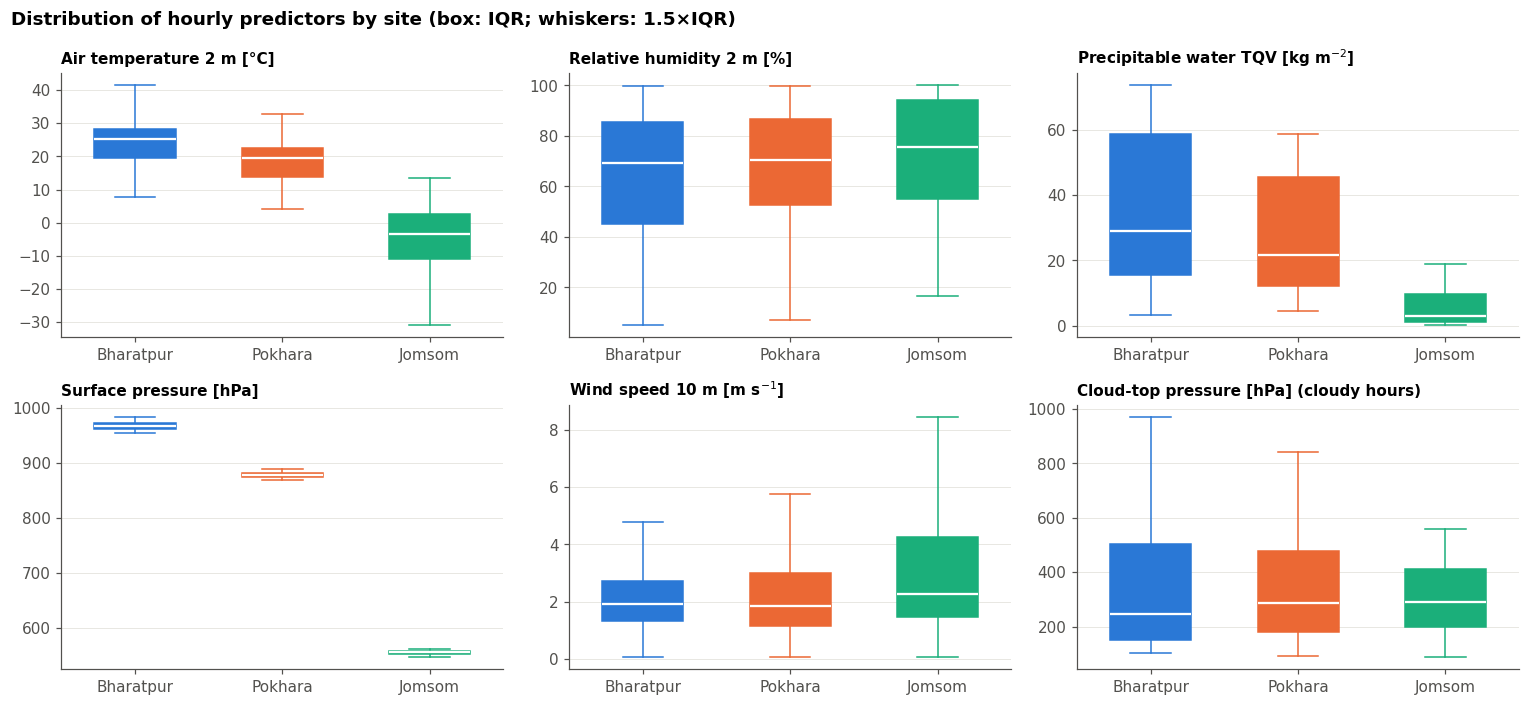

In [15]:
# Fig 7 – distributions of predictors by site
BOX_VARS = VARS[:5] + [('CLDPRS_hPa', 'Cloud-top pressure [hPa] (cloudy hours)')]   # cloud flag is 0/1, so use cloud-top pressure
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, (v, lab) in zip(axes.flat, BOX_VARS):
    vals = [data.loc[data.site == s, v].dropna() for s in SITES_IN]
    bp = ax.boxplot(vals, patch_artist=True, showfliers=False, widths=0.55, medianprops=dict(color='white', lw=1.5))
    for b, s in zip(bp['boxes'], SITES_IN): b.set(facecolor=SITE_C[s], edgecolor=SITE_C[s])
    for k, s in enumerate(SITES_IN):
        for part in ('whiskers', 'caps'):
            for line in bp[part][2*k:2*k+2]: line.set_color(SITE_C[s])
    ax.set_xticks(range(1, len(SITES_IN) + 1), SITES_IN); ax.set_title(lab, loc='left', fontsize=10); ax.grid(axis='x', visible=False)
suptitle(fig, 'Fig 7. Distribution of hourly predictors by site (box: IQR; whiskers: 1.5×IQR)'); fig.tight_layout(); save(fig, 'm07_predictor_boxplots')

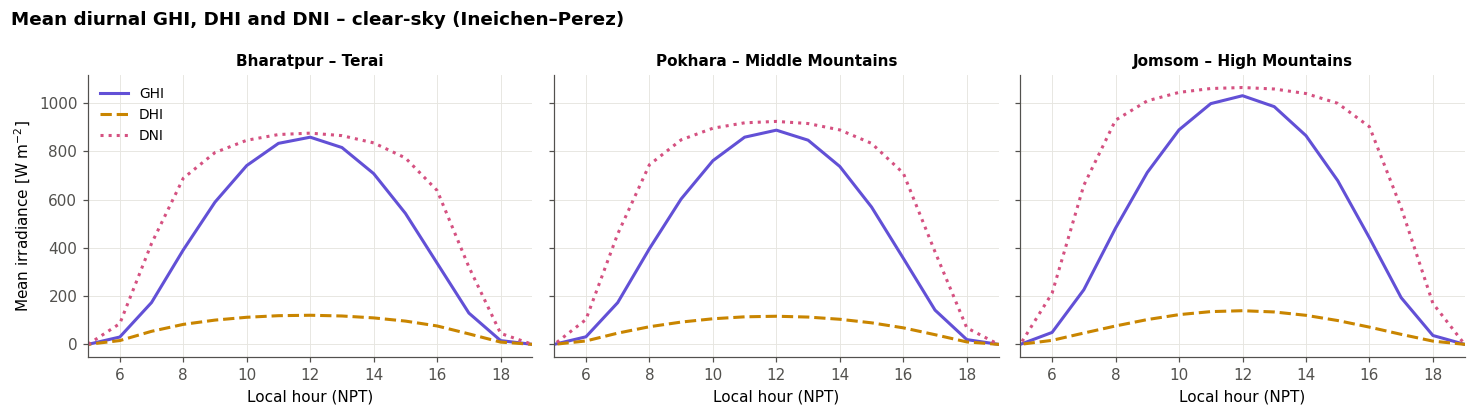

In [16]:
# Fig 8 – irradiance components through the day at each site (all-sky if available, else clear-sky)
SUF = '' if HAS_GHI else '_cs'
KIND = 'all-sky' if HAS_GHI else 'clear-sky (Ineichen–Perez)'
fig, axes = plt.subplots(1, len(SITES_IN), figsize=(4.5 * len(SITES_IN), 3.8), sharey=True, squeeze=False)
for ax, s in zip(axes[0], SITES_IN):
    d = data[data.site == s].groupby('hour')[[c + SUF for c in ('GHI', 'DHI', 'DNI')]].mean()
    for c in ('GHI', 'DHI', 'DNI'):
        ax.plot(d.index, d[c + SUF], color=COMP_C[c], ls=COMP_LS[c], label=c)
    ax.set_title(f'{s} – {SITES[s]["zone"]}', fontsize=10); ax.set_xlim(5, 19); ax.set_xlabel('Local hour (NPT)')
axes[0, 0].set_ylabel('Mean irradiance [W m$^{-2}$]'); axes[0, 0].legend(loc='upper left')
suptitle(fig, f'Fig 8. Mean diurnal GHI, DHI and DNI – {KIND}'); fig.tight_layout(); save(fig, 'm08_diurnal_components')

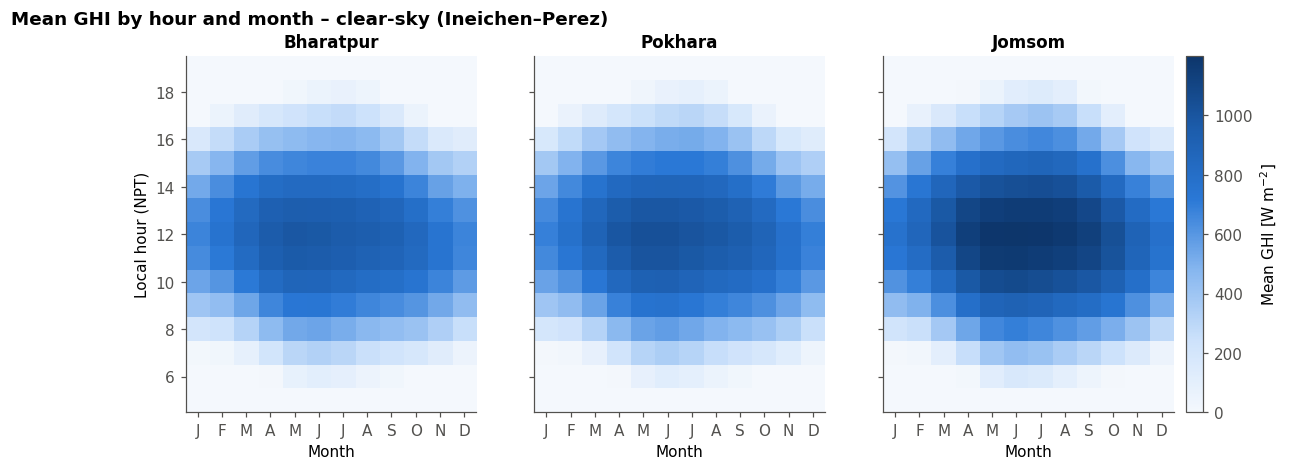

In [17]:
# Fig 9 – GHI by hour and month (heat map)
fig, axes = plt.subplots(1, len(SITES_IN), figsize=(4.6 * len(SITES_IN), 4.2), sharey=True, squeeze=False)
vmax = data.groupby(['site', 'month', 'hour'])['GHI' + SUF].mean().max()
for ax, s in zip(axes[0], SITES_IN):
    h = data[data.site == s].pivot_table(index='hour', columns='month', values='GHI' + SUF, aggfunc='mean').reindex(columns=range(1, 13)).loc[5:19]
    im = ax.imshow(h.values, aspect='auto', origin='lower', cmap=SEQ, vmin=0, vmax=vmax, extent=[0.5, 12.5, 4.5, 19.5])
    ax.set_xticks(range(1, 13), [x[0] for x in MONTHS]); ax.set_title(s); ax.grid(False); ax.set_xlabel('Month')
axes[0, 0].set_ylabel('Local hour (NPT)')
fig.colorbar(im, ax=axes, pad=0.01).set_label('Mean GHI [W m$^{-2}$]')
suptitle(fig, f'Fig 9. Mean GHI by hour and month – {KIND}'); save(fig, 'm09_ghi_heatmap')

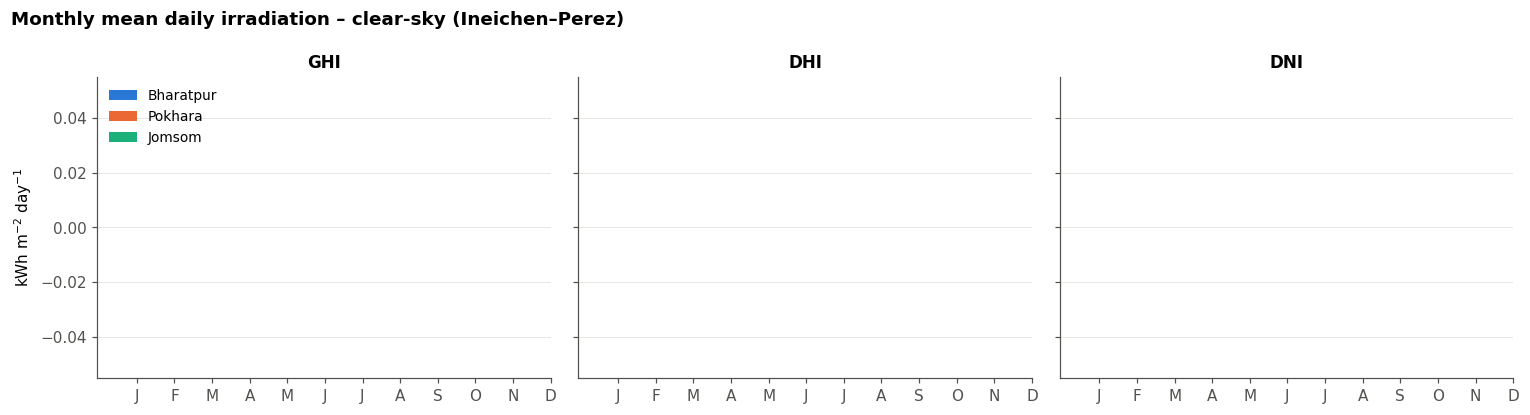

In [18]:
# Fig 10 – monthly mean daily irradiation (kWh m⁻² day⁻¹)
data['date'] = pd.to_datetime(data['time_local']).dt.normalize()
daily = (data.groupby(['site', 'date'])[[c + SUF for c in ('GHI', 'DHI', 'DNI')]].sum(min_count=20) / 1000).reset_index()
daily['month'] = daily.date.dt.month
mtot = daily.groupby(['site', 'month']).mean(numeric_only=True)
mtot.round(2).to_csv(FIG_DIR / 'm10_monthly_daily_totals.csv')
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
w = 0.8 / len(SITES_IN)
for ax, c in zip(axes, ('GHI', 'DHI', 'DNI')):
    for k, s in enumerate(SITES_IN):
        v = mtot.loc[s, c + SUF].reindex(range(1, 13))
        ax.bar(np.arange(1, 13) + (k - (len(SITES_IN) - 1) / 2) * w, v, width=w - 0.03, color=SITE_C[s], label=s)
    ax.set_xticks(range(1, 13), [x[0] for x in MONTHS]); ax.set_title(c); ax.grid(axis='x', visible=False)
axes[0].set_ylabel('kWh m$^{-2}$ day$^{-1}$'); axes[0].legend(loc='upper left')
suptitle(fig, f'Fig 10. Monthly mean daily irradiation – {KIND}'); fig.tight_layout(); save(fig, 'm10_monthly_totals')

Time step: 1 h; median rows per day: 12 (daytime rows only)
         GHI_cs                   DHI_cs                   DNI_cs                     days               
site  Bharatpur Jomsom Pokhara Bharatpur Jomsom Pokhara Bharatpur Jomsom Pokhara Bharatpur Jomsom Pokhara
month                                                                                                    
1          2.08   2.37    2.12      0.22   0.18    0.17      3.99   4.96    4.30        14     14      12
2          2.47   2.83    2.52      0.27   0.24    0.22      4.28   5.33    4.57        14     14      12
3          2.99   3.52    3.07      0.38   0.38    0.35      4.40   5.54    4.65        14     14      10
4          3.50   4.23    3.63      0.51   0.54    0.49      4.41   5.75    4.68        14     14      10
5          3.80   4.70    3.98      0.64   0.68    0.60      4.39   5.93    4.77        14     14      10
6          3.88   4.91    4.10      0.74   0.81    0.71      4.24   5.83    4.65        14  

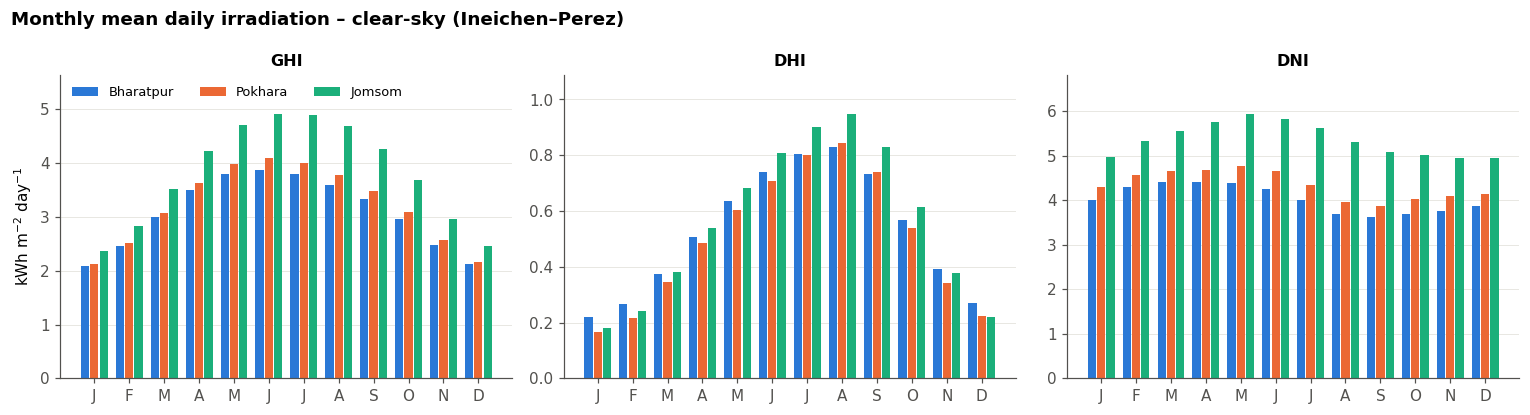

In [29]:
# Fig 10 – monthly mean daily irradiation (kWh m⁻² day⁻¹)
COLS = [c + SUF for c in ('GHI', 'DHI', 'DNI')]
assert all(c in data for c in COLS), f'Missing columns: {[c for c in COLS if c not in data]}'

d = data.copy()
d['time_local'] = pd.to_datetime(d['time_local'])
d['date'] = d.time_local.dt.normalize()

# ---- Night hours have zero irradiance, they are not missing data ----
if 'zenith' in d:
    night = d['zenith'] >= 90
    for c in COLS: d.loc[night & d[c].isna(), c] = 0.0

# ---- Time step of the data (1 h for MERRA-2 / POWER) → energy per row in Wh m⁻² ----
step_h = d.groupby('site').time_local.diff().median() / pd.Timedelta('1h')
rows_per_day = d.groupby(['site', 'date']).size()
full_days = rows_per_day.median() >= 0.8 * 24 / step_h          # True if night rows are in the table
print(f'Time step: {step_h:g} h; median rows per day: {rows_per_day.median():.0f} '
      f'({"full days" if full_days else "daytime rows only"})')

# ---- Daily totals: a day counts only if (almost) all its hours are present ----
need = int(0.8 * 24 / step_h) if full_days else 1               # daytime-only table: night contributes 0
daily = (d.groupby(['site', 'date'])[COLS].sum(min_count=need) * step_h / 1000).reset_index()
daily['month'] = daily.date.dt.month
mtot = daily.groupby(['site', 'month'])[COLS].mean()
mtot['days'] = daily.groupby(['site', 'month'])[COLS[0]].count()
mtot.round(2).to_csv(FIG_DIR / 'm10_monthly_daily_totals.csv')
print(mtot.round(2).unstack('site').to_string())

# ---- Figure (own y-axis per panel: DNI is ~5× DHI) ----
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
w = 0.8 / len(SITES_IN)
for ax, c in zip(axes, ('GHI', 'DHI', 'DNI')):
    for k, s in enumerate(SITES_IN):
        if s not in mtot.index.get_level_values('site'): print(f'{s}: no data for {c}'); continue
        v = mtot.loc[s, c + SUF].reindex(range(1, 13))
        ax.bar(np.arange(1, 13) + (k - (len(SITES_IN) - 1) / 2) * w, v, width=w - 0.03, color=SITE_C[s], label=s)
    ax.set_xticks(range(1, 13), [x[0] for x in MONTHS]); ax.set_title(c); ax.grid(axis='x', visible=False)
    ax.set_ylim(0, np.nanmax(mtot[c + SUF].values) * 1.15)
axes[0].set_ylabel('kWh m$^{-2}$ day$^{-1}$'); axes[0].legend(loc='upper left', ncol=len(SITES_IN))
suptitle(fig, f'Fig 10. Monthly mean daily irradiation – {KIND}'); fig.tight_layout(); save(fig, 'm10_monthly_totals')

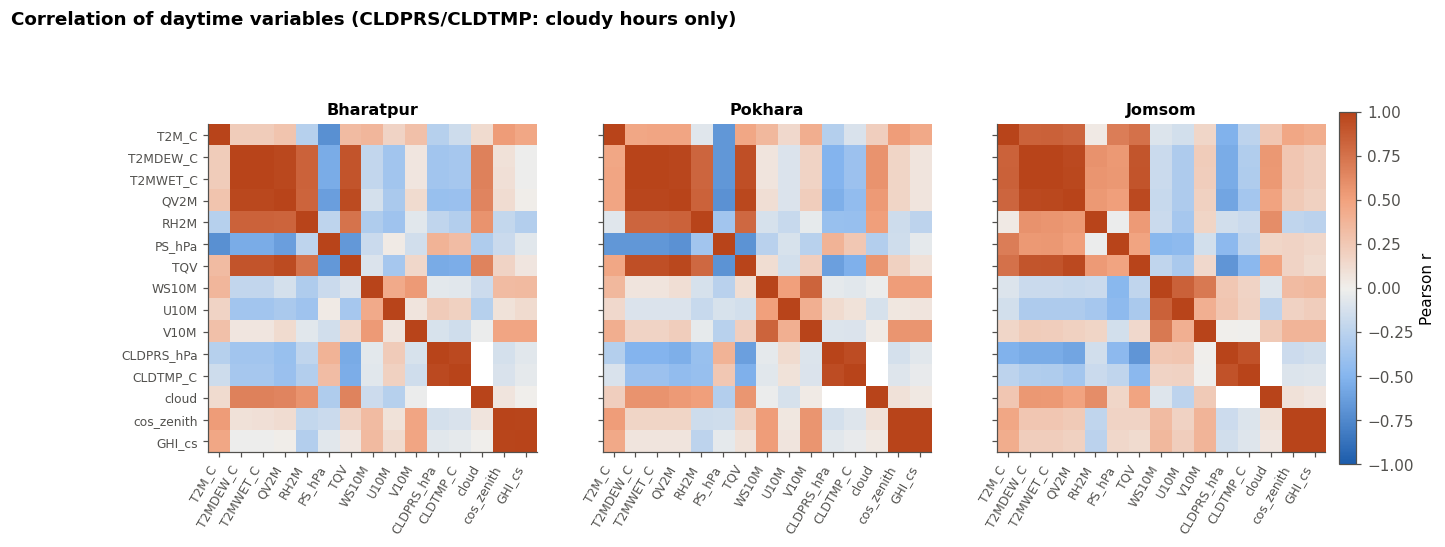

In [30]:
# Fig 11 – correlation of daytime predictors (with all-sky GHI and k_c if available)
cols = ['T2M_C', 'T2MDEW_C', 'T2MWET_C', 'QV2M', 'RH2M', 'PS_hPa', 'TQV', 'WS10M', 'U10M', 'V10M',
        'CLDPRS_hPa', 'CLDTMP_C', 'cloud', 'cos_zenith', 'GHI_cs'] + (['GHI', 'kc'] if HAS_GHI else [])
dd = data[data.is_day]
cols = [c for c in cols if c in dd and dd[c].notna().sum() > 50 and dd[c].std() > 1e-9]
fig, axes = plt.subplots(1, len(SITES_IN), figsize=(5.2 * len(SITES_IN), 5.2), sharey=True, squeeze=False)
for ax, s in zip(axes[0], SITES_IN):
    corr = dd[dd.site == s][cols].corr()
    corr.round(3).to_csv(FIG_DIR / f'm11_corr_{s.lower()}.csv')
    im = ax.imshow(corr.values, cmap=DIV, vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(len(cols)), cols, fontsize=8); ax.grid(False); ax.set_title(s)
fig.colorbar(im, ax=axes, pad=0.01, shrink=0.8).set_label('Pearson r')
suptitle(fig, 'Fig 11. Correlation of daytime variables (CLDPRS/CLDTMP: cloudy hours only)'); save(fig, 'm11_correlation')

In [32]:
# Fig 12–13 – only when all-sky GHI is available
if HAS_GHI:
    kt_line = np.linspace(0, 1, 200)
    erbs_kd = np.where(kt_line <= 0.22, 1 - 0.09 * kt_line,
              np.where(kt_line <= 0.80, 0.9511 - 0.1604*kt_line + 4.388*kt_line**2 - 16.638*kt_line**3 + 12.336*kt_line**4, 0.165))
    fig, axes = plt.subplots(2, len(SITES_IN), figsize=(4.6 * len(SITES_IN), 8), squeeze=False)
    for j, s in enumerate(SITES_IN):
        d = dd[(dd.site == s) & dd.GHI.notna()]
        ax = axes[0, j]
        ax.hexbin(d.GHI_cs, d.GHI, gridsize=45, extent=(0, 1100, 0, 1100), cmap=SEQ, mincnt=1, bins='log')
        ax.plot([0, 1100], [0, 1100], color=INK, lw=1, ls='--'); ax.grid(False)
        err = d.GHI_cs - d.GHI
        r2 = 1 - (err**2).sum() / ((d.GHI - d.GHI.mean())**2).sum()
        ax.text(0.03, 0.97, f'RMSE {np.sqrt((err**2).mean()):.0f} W m$^{{-2}}$\nMBE {err.mean():+.0f}\nR² {r2:.2f}',
                transform=ax.transAxes, va='top', fontsize=8.5, color=INK2)
        ax.set_title(s); ax.set_xlabel('Clear-sky GHI [W m$^{-2}$]'); ax.set_ylabel('All-sky GHI [W m$^{-2}$]')
        ax = axes[1, j]
        ax.hexbin(d.kt, d.k_d, gridsize=45, extent=(0, 1, 0, 1.05), cmap=SEQ, mincnt=1, bins='log')
        ax.plot(kt_line, erbs_kd, color=INK, lw=1.2, ls='--', label='Erbs'); ax.grid(False)
        ax.set_xlabel('k$_t$'); ax.set_ylabel('k$_d$ = DHI/GHI')
    axes[1, 0].legend(loc='lower left')
    suptitle(fig, 'Fig 12. All-sky vs clear-sky GHI (top) and diffuse fraction vs clearness index (bottom)')
    fig.tight_layout(); save(fig, 'm12_allsky_checks')

    fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
    g = data.groupby(['season', 'site', 'hour'], observed=True)['GHI'].mean()
    for ax, se in zip(axes, SEASONS):
        for s in SITES_IN:
            x = g.loc[(se, s)]; ax.plot(x.index, x.values, color=SITE_C[s], ls=SITE_LS[s], label=s)
        ax.set_title(se); ax.set_xlim(5, 19); ax.set_xlabel('Local hour (NPT)')
    axes[0].set_ylabel('Mean GHI [W m$^{-2}$]'); axes[-1].legend(loc='upper right')
    suptitle(fig, 'Fig 13. Mean diurnal all-sky GHI by season'); fig.tight_layout(); save(fig, 'm13_ghi_diurnal_season')
else:
    print('Figures 12–13 need all-sky GHI (see section 4).')

print('All figures saved in', FIG_DIR)

Figures 12–13 need all-sky GHI (see section 4).
All figures saved in /content/drive/My Drive/GHI_Nepal_MSc_Research/figures/results


# Part 2. Study area and research design (Chapter 3 figures)
D1 study-area map with relief · D2 target and predictor grid cells · D3 site characteristics and terrain profile ·
D4 research workflow · D5 validation design. Relief comes from `DEM_FILE` (e.g. NASADEM GeoTIFF) if given, otherwise
ETOPO1 (1 arc-minute) is downloaded once from NOAA ERDDAP and cached; the country outline comes from `BOUNDARY_FILE`
or Natural Earth. If neither can be obtained the figures are still drawn, without relief or outline.

In [35]:
import urllib.request
from matplotlib.colors import LightSource
from matplotlib.patches import Rectangle, FancyBboxPatch, FancyArrowPatch
STATIC_DIR = ROOT / 'data' / 'static'; STATIC_DIR.mkdir(parents=True, exist_ok=True)
D_EXT = (79.9, 88.3, 26.2, 30.6)                     # lon0, lon1, lat0, lat1 (Nepal)
SPLIT_C = {'train': '#86b6ef', 'val': '#2a78d6', 'test': '#0d366b'}
SITE_M  = {'Bharatpur': 'o', 'Pokhara': 's', 'Jomsom': '^'}
RELIEF = LinearSegmentedColormap.from_list('relief', ['#f3f1ea', '#e2dccb', '#c9bfa5', '#a8977a', '#7d6b55', '#53463a'])

def load_dem(ext=D_EXT):
    """Return (lon 1-D, lat 1-D ascending, z 2-D) or None."""
    try:
        if DEM_FILE and Path(DEM_FILE).exists():
            import rasterio
            from rasterio.windows import from_bounds
            with rasterio.open(DEM_FILE) as src:
                w = from_bounds(ext[0], ext[2], ext[1], ext[3], src.transform)
                z = src.read(1, window=w, out_shape=(1, 600, 1150)).astype(float)
                if src.nodata is not None: z[z == src.nodata] = np.nan
            lon = np.linspace(ext[0], ext[1], z.shape[1]); lat = np.linspace(ext[3], ext[2], z.shape[0])
            return lon, lat[::-1], z[::-1]
        cache = STATIC_DIR / 'etopo1_nepal.nc'
        if not cache.exists():
            url = ('https://coastwatch.pfeg.noaa.gov/erddap/griddap/etopo180.nc?altitude'
                   f'%5B({ext[2]}):1:({ext[3]})%5D%5B({ext[0]}):1:({ext[1]})%5D')
            urllib.request.urlretrieve(url, cache)
        import xarray as xr
        ds = xr.open_dataset(cache)
        a = ds['altitude'].sortby('latitude')
        return a.longitude.values, a.latitude.values, a.values.astype(float)
    except Exception as e:
        bad = STATIC_DIR / 'etopo1_nepal.nc'
        if bad.exists() and not (DEM_FILE and Path(DEM_FILE).exists()): bad.unlink()     # never keep a broken download
        print('Relief not available (figures drawn without it):', str(e)[:120]); return None

def load_boundary():
    """Return (nepal GeoDataFrame, neighbours GeoDataFrame or None) or (None, None)."""
    try:
        import geopandas as gpd
        if BOUNDARY_FILE and Path(BOUNDARY_FILE).exists():
            return gpd.read_file(BOUNDARY_FILE).to_crs(4326), None
        cache = STATIC_DIR / 'ne_50m_admin_0_countries.zip'
        if not cache.exists():
            urllib.request.urlretrieve('https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip', cache)
        g = gpd.read_file(cache).to_crs(4326); col = 'ADMIN' if 'ADMIN' in g else 'NAME'
        return g[g[col] == 'Nepal'], g
    except Exception as e:
        bad = STATIC_DIR / 'ne_50m_admin_0_countries.zip'
        if bad.exists() and not (BOUNDARY_FILE and Path(BOUNDARY_FILE).exists()): bad.unlink()
        print('Country outline not available (figures drawn without it):', str(e)[:120]); return None, None

DEM = load_dem(); NEPAL, WORLD = load_boundary()

def draw_relief(ax, ext, alpha=1.0):
    if DEM is None: return None
    lon, lat, z = DEM
    i = (lon >= ext[0]) & (lon <= ext[1]); j = (lat >= ext[2]) & (lat <= ext[3])
    zz = np.clip(z[np.ix_(j, i)], 0, None)
    hs = LightSource(azdeg=315, altdeg=45).hillshade(zz, vert_exag=0.02, dx=1, dy=1)
    im = ax.imshow(zz, extent=[lon[i][0], lon[i][-1], lat[j][0], lat[j][-1]], origin='lower', cmap=RELIEF, vmin=0, vmax=7000, alpha=alpha, zorder=0)
    ax.imshow(hs, extent=[lon[i][0], lon[i][-1], lat[j][0], lat[j][-1]], origin='lower', cmap='gray', alpha=0.25 * alpha, zorder=0.1)
    return im

def draw_outline(ax, lw=1.4):
    if WORLD is not None: WORLD.boundary.plot(ax=ax, color='#8a8984', lw=0.6, zorder=2)
    if NEPAL is not None: NEPAL.boundary.plot(ax=ax, color=INK, lw=lw, zorder=3)

def draw_sites(ax, label=True, ms=9):
    for s in SITE_ORDER:
        v = SITE_INFO[s]
        ax.plot(v['lon'], v['lat'], marker=SITE_M[s], color=SITE_C[s], ms=ms, mec='white', mew=1.5, zorder=6, ls='')
        if label:
            ax.annotate(f"{s}\n{v['zone']}, ~{v['alt']:,} m", (v['lon'], v['lat']), xytext=(8, 4), textcoords='offset points',
                        fontsize=8.5, color=INK, zorder=7, bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.85))

def km_to_deg_lon(km, lat): return km / (111.32 * np.cos(np.radians(lat)))

TypeError: list indices must be integers or slices, not str

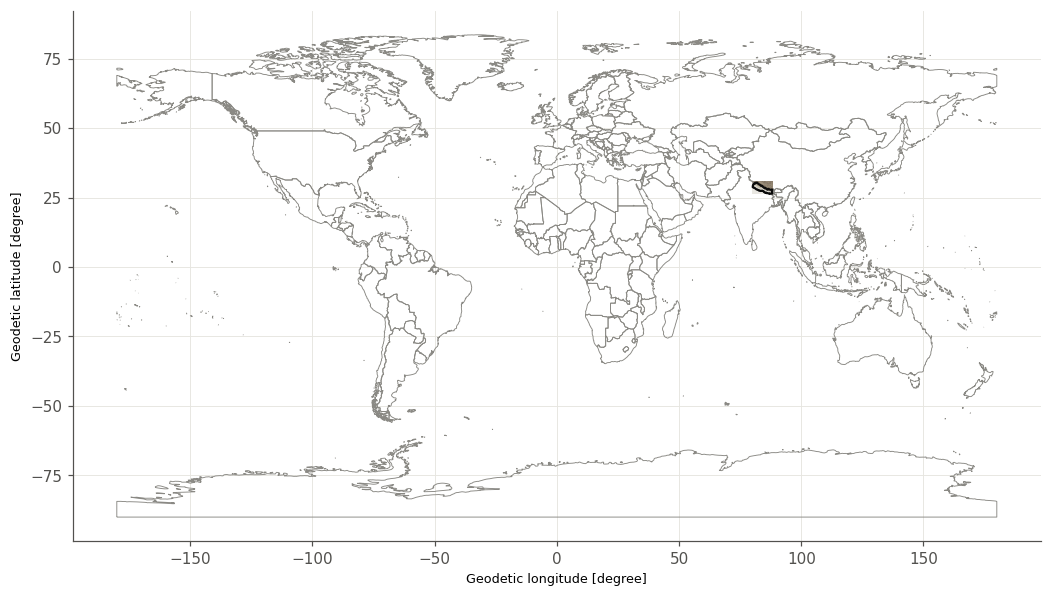

In [34]:
# Fig D1 – study area map
fig = plt.figure(figsize=(11, 6.6))
ax = fig.add_axes([0.06, 0.08, 0.80, 0.84])
im = draw_relief(ax, D_EXT); draw_outline(ax); draw_sites(ax)
ax.set_xlim(D_EXT[0], D_EXT[1]); ax.set_ylim(D_EXT[2], D_EXT[3]); ax.set_aspect(1 / np.cos(np.radians(28.4)))
ax.set_xlabel('Longitude [°E]'); ax.set_ylabel('Latitude [°N]'); ax.grid(color='white', lw=0.5, alpha=0.6)
x0, y0 = D_EXT[0] + 0.3, D_EXT[2] + 0.25; L = km_to_deg_lon(100, y0)                      # 100 km scale bar
ax.plot([x0, x0 + L], [y0, y0], color=INK, lw=3, solid_capstyle='butt', zorder=8); ax.text(x0 + L / 2, y0 + 0.08, '100 km', ha='center', fontsize=8.5, zorder=8)
ax.annotate('N', xy=(D_EXT[1] - 0.3, D_EXT[3] - 0.25), xytext=(D_EXT[1] - 0.3, D_EXT[3] - 0.75), ha='center', fontsize=11, fontweight='bold',
            arrowprops=dict(arrowstyle='-|>', color=INK, lw=1.5), zorder=8)
if im is not None:
    cax = fig.add_axes([0.875, 0.2, 0.018, 0.55]); fig.colorbar(im, cax=cax).set_label('Elevation [m a.s.l.]')
if WORLD is not None:                                                                     # locator inset
    ins = fig.add_axes([0.065, 0.62, 0.2, 0.28]); WORLD.plot(ax=ins, color='#e6e5e0', edgecolor='white', lw=0.3)
    NEPAL.plot(ax=ins, color=INK2); ins.set_xlim(60, 100); ins.set_ylim(5, 40); ins.set_xticks([]); ins.set_yticks([])
    ins.set_xlabel(''); ins.set_ylabel(''); ins.grid(False)
    for sp in ins.spines.values(): sp.set_visible(True); sp.set_color(INK2)
ax.set_title('Fig D1. Study area: three sites spanning the Terai, Middle Mountains and High Mountains of Nepal', loc='left')
save(fig, 'D1_study_area_map')

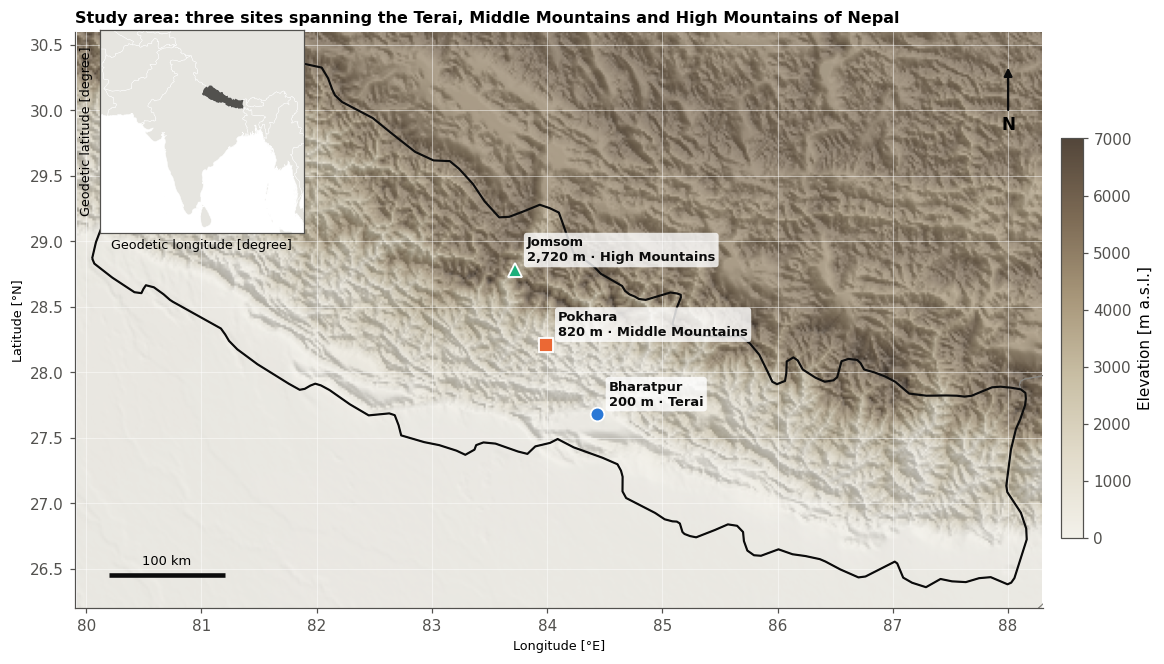

In [37]:
# Fig D1 – study area map (self-contained: works after a restart and whatever SITES contains)
import importlib, subprocess, sys
if importlib.util.find_spec('geopandas') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'geopandas'])
import geopandas as gpd

# ---- Site metadata always from SITE_INFO (dict), never from SITES (list) ----
SITE_ORDER = [s for s in ('Bharatpur', 'Pokhara', 'Jomsom') if s in SITE_INFO]
ZONE_OF    = {s: SITE_INFO[s].get('zone', '') for s in SITE_ORDER}
D_EXT      = globals().get('D_EXT', (80.0, 88.3, 26.2, 30.6))          # lon_min, lon_max, lat_min, lat_max (Nepal)

def km_to_deg_lon(km, lat): return km / (111.32 * np.cos(np.radians(lat)))

def draw_sites(ax, label=True, ms=9):
    for s in SITE_ORDER:
        v = SITE_INFO[s]
        ax.plot(v['lon'], v['lat'], marker=SITE_M.get(s, 'o'), ms=ms, color=SITE_C.get(s, INK),
                mec='white', mew=1.2, ls='', zorder=9)
        if label:
            ax.annotate(f"{s}\n{v['alt']:,} m · {ZONE_OF[s]}", (v['lon'], v['lat']), xytext=(8, 6),
                        textcoords='offset points', fontsize=8.5, fontweight='bold', color=INK, zorder=9,
                        bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.8))

# ---- Country outlines (Natural Earth, downloaded once and cached on Drive) ----
if globals().get('WORLD') is None:
    ne = ROOT / 'data' / 'raw' / 'ne_110m_admin_0_countries.zip'
    try:
        if not ne.exists():
            import requests
            ne.write_bytes(requests.get('https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip', timeout=120).content)
        WORLD = gpd.read_file(ne)
        NEPAL = WORLD[WORLD['ADMIN'] == 'Nepal']
    except Exception as e:
        print('World outlines unavailable (no inset/outline):', e); WORLD = NEPAL = None

# ---- Figure ----
fig = plt.figure(figsize=(11, 6.6))
ax  = fig.add_axes([0.06, 0.08, 0.80, 0.84])
im  = draw_relief(ax, D_EXT) if 'draw_relief' in globals() else None      # ETOPO1 relief if your helper exists
if 'draw_outline' in globals():
    draw_outline(ax)
elif NEPAL is not None:
    WORLD.boundary.plot(ax=ax, color=INK2, lw=0.6, zorder=5); NEPAL.boundary.plot(ax=ax, color=INK, lw=1.4, zorder=6)
draw_sites(ax)

ax.set_xlim(D_EXT[0], D_EXT[1]); ax.set_ylim(D_EXT[2], D_EXT[3]); ax.set_aspect(1 / np.cos(np.radians(28.4)))
ax.set_xlabel('Longitude [°E]'); ax.set_ylabel('Latitude [°N]'); ax.grid(color='white' if im is not None else GRID, lw=0.5, alpha=0.6)

x0, y0 = D_EXT[0] + 0.3, D_EXT[2] + 0.25; L = km_to_deg_lon(100, y0)          # 100 km scale bar
ax.plot([x0, x0 + L], [y0, y0], color=INK, lw=3, solid_capstyle='butt', zorder=8)
ax.text(x0 + L / 2, y0 + 0.08, '100 km', ha='center', fontsize=8.5, zorder=8)
ax.annotate('N', xy=(D_EXT[1] - 0.3, D_EXT[3] - 0.25), xytext=(D_EXT[1] - 0.3, D_EXT[3] - 0.75), ha='center',
            fontsize=11, fontweight='bold', arrowprops=dict(arrowstyle='-|>', color=INK, lw=1.5), zorder=8)

if im is not None:
    cax = fig.add_axes([0.875, 0.2, 0.018, 0.55]); fig.colorbar(im, cax=cax).set_label('Elevation [m a.s.l.]')
if WORLD is not None:                                                      # locator inset
    ins = fig.add_axes([0.065, 0.62, 0.2, 0.28])
    WORLD.plot(ax=ins, color='#e6e5e0', edgecolor='white', lw=0.3); NEPAL.plot(ax=ins, color=INK2)
    ins.set_xlim(60, 100); ins.set_ylim(5, 40); ins.set_xticks([]); ins.set_yticks([]); ins.grid(False)
    for sp in ins.spines.values(): sp.set_visible(True); sp.set_color(INK2)

ax.set_title('Fig D1. Study area: three sites spanning the Terai, Middle Mountains and High Mountains of Nepal', loc='left')
save(fig, 'D1_study_area_map')

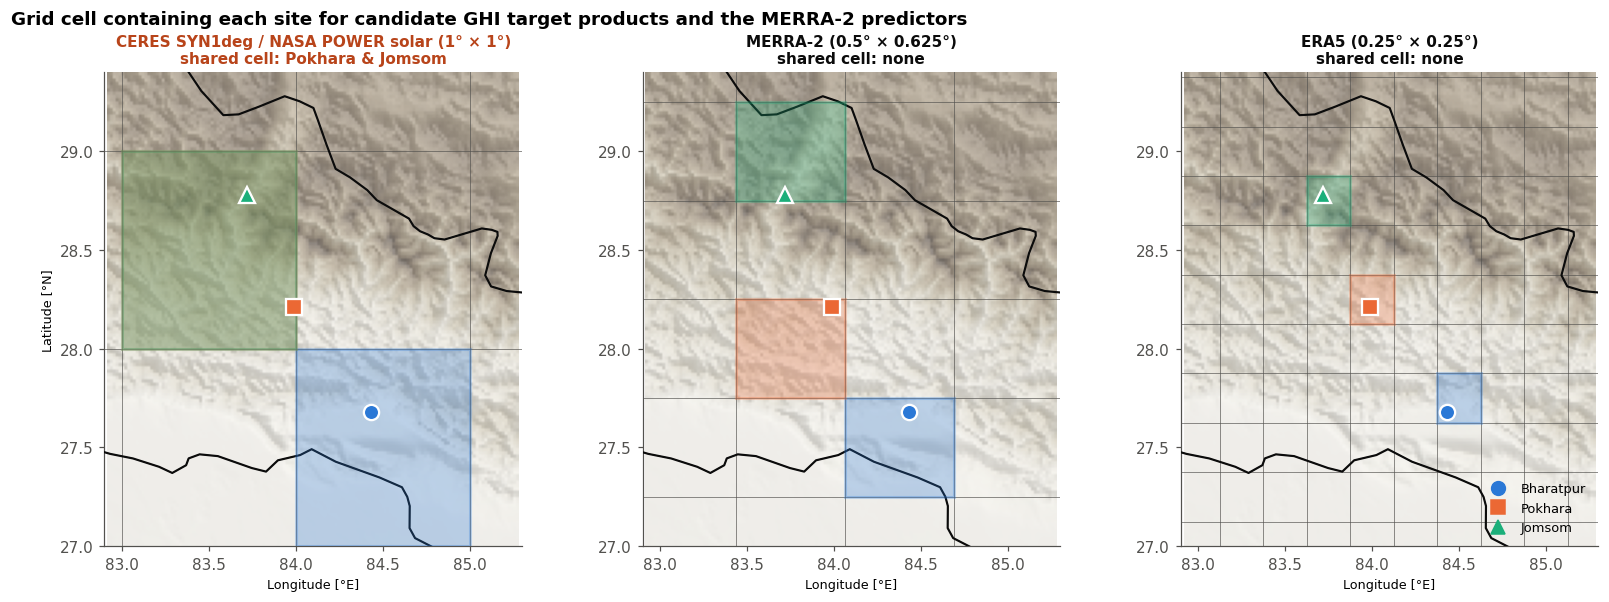

In [23]:
# Fig D2 – grid cells of candidate GHI target products and of the MERRA-2 predictors around the sites
PRODUCTS = [dict(name='CERES SYN1deg / NASA POWER solar (1° × 1°)', dlat=1.0, dlon=1.0, mode='edges'),
            dict(name='MERRA-2 (0.5° × 0.625°)', dlat=0.5, dlon=0.625, mode='centres'),
            dict(name='ERA5 (0.25° × 0.25°)', dlat=0.25, dlon=0.25, mode='centres')]
def cell_bounds(lat, lon, g):
    if g['mode'] == 'edges':
        la, lo = np.floor(lat / g['dlat']) * g['dlat'], np.floor(lon / g['dlon']) * g['dlon']
        return la, la + g['dlat'], lo, lo + g['dlon']
    la, lo = np.round(lat / g['dlat']) * g['dlat'], np.round(lon / g['dlon']) * g['dlon']
    return la - g['dlat'] / 2, la + g['dlat'] / 2, lo - g['dlon'] / 2, lo + g['dlon'] / 2
ZEXT = (82.9, 85.3, 27.0, 29.4)
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
grid_rows = []
for ax, g in zip(axes, PRODUCTS):
    draw_relief(ax, ZEXT, alpha=0.7); draw_outline(ax)
    off = 0.0 if g['mode'] == 'edges' else 0.5            # cell edges at k·d (edges) or (k + ½)·d (centred grids)
    for k in np.arange(np.floor(ZEXT[0] / g['dlon']) - 1, np.ceil(ZEXT[1] / g['dlon']) + 2):
        ax.axvline((k + off) * g['dlon'], color=INK2, lw=0.6, alpha=0.7, zorder=1)
    for k in np.arange(np.floor(ZEXT[2] / g['dlat']) - 1, np.ceil(ZEXT[3] / g['dlat']) + 2):
        ax.axhline((k + off) * g['dlat'], color=INK2, lw=0.6, alpha=0.7, zorder=1)
    cells = {}
    for s in SITE_ORDER:
        b = cell_bounds(SITES[s]['lat'], SITES[s]['lon'], g); cells[s] = tuple(np.round(b, 4))
        ax.add_patch(Rectangle((b[2], b[0]), b[3] - b[2], b[1] - b[0], fc=SITE_C[s], ec=SITE_C[s], alpha=0.28, lw=2, zorder=4))
    shared = [f'{a} & {b}' for i, a in enumerate(SITE_ORDER) for b in SITE_ORDER[i + 1:] if cells[a] == cells[b]]
    grid_rows.append(dict(product=g['name'], shared_cells='; '.join(shared) or 'none',
                          **{f'{s}_cell(lat0,lat1,lon0,lon1)': cells[s] for s in SITE_ORDER}))
    draw_sites(ax, label=False, ms=10)
    ax.set_xlim(ZEXT[0], ZEXT[1]); ax.set_ylim(ZEXT[2], ZEXT[3]); ax.set_aspect(1 / np.cos(np.radians(28.2))); ax.grid(False)
    ax.set_title(f"{g['name']}\nshared cell: {', '.join(shared) if shared else 'none'}", fontsize=10,
                 color='#b8441a' if shared else INK)
    ax.set_xlabel('Longitude [°E]'); ax.set_ylabel('')
axes[0].set_ylabel('Latitude [°N]')
axes[-1].legend(handles=[plt.Line2D([], [], marker=SITE_M[s], color=SITE_C[s], ls='', ms=9, label=s) for s in SITE_ORDER], loc='lower right', fontsize=8.5)
pd.DataFrame(grid_rows).to_csv(OUT_DIR / 'grid_cells_by_product.csv', index=False)
suptitle(fig, 'Fig D2. Grid cell containing each site for candidate GHI target products and the MERRA-2 predictors'); fig.tight_layout(); save(fig, 'D2_target_grid_cells')

Site characteristics:
site                                                Bharatpur  Pokhara  Jomsom
Mean daily clear-sky GHI [kWh m$^{-2}$ day$^{-1}$]       3.08     3.19    3.79
Mean air temperature [°C]                               24.05    18.49   -4.24
Mean column water vapour [kg m$^{-2}$]                  34.34    27.00    5.29
Cloud occurrence [% of hours]                           65.58    73.84   76.84
Monsoon cloud occurrence [% of hours, Jun–Sep]          90.18    94.58   97.32
Mean surface pressure [hPa]                            967.66   877.80  555.53


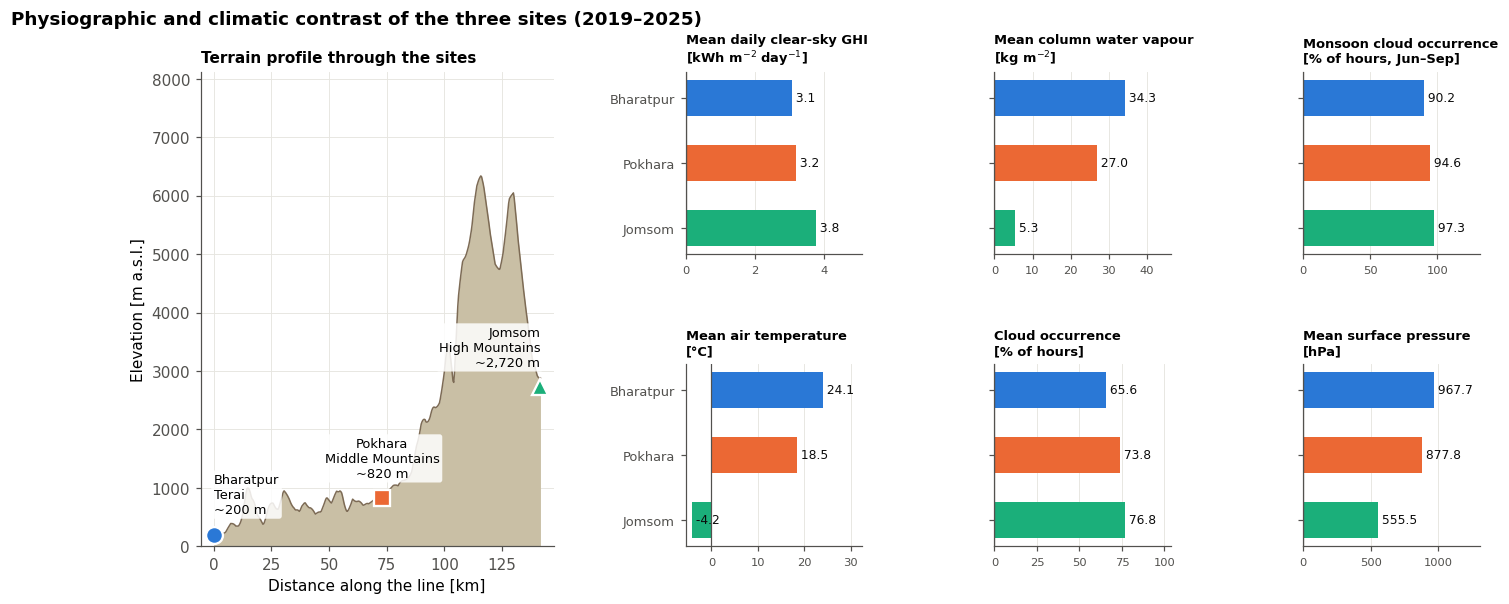

In [40]:
# Fig D3 – site characteristics: terrain profile through the sites and contrasting climate
SITE_ORDER = [s for s in ('Bharatpur', 'Pokhara', 'Jomsom') if s in SITE_INFO]
OUT_DIR    = globals().get('OUT_DIR', RES_DIR)
DEM        = globals().get('DEM', None)

# ---- Clean copy of the data with consistent site names ----
dat = data.copy()
dat['site'] = dat['site'].astype(str).str.strip().replace({'Mustang': 'Jomsom', 'Miustang': 'Jomsom', 'Jomson': 'Jomsom',
                                                            'Kaski': 'Pokhara', 'Chitwan': 'Bharatpur'})
dat['time_local'] = pd.to_datetime(dat['time_local'])
if 'month' not in dat: dat['month'] = dat.time_local.dt.month
unknown = sorted(set(dat.site) - set(SITE_ORDER))
if unknown: print('⚠ Site names in data not in SITE_ORDER (ignored):', unknown)
YEAR0, YEAR1 = globals().get('YEAR0', dat.time_local.dt.year.min()), globals().get('YEAR1', dat.time_local.dt.year.max())

def haversine(lat1, lon1, lat2, lon2):
    p = np.radians; a = np.sin(p(lat2 - lat1) / 2)**2 + np.cos(p(lat1)) * np.cos(p(lat2)) * np.sin(p(lon2 - lon1) / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def site_mean(col, sub=None):
    """Mean of a column per site; NaN for sites/columns without data."""
    d = dat if sub is None else sub
    if col not in d: return pd.Series(np.nan, index=SITE_ORDER)
    return pd.to_numeric(d[col], errors='coerce').groupby(d.site).mean().reindex(SITE_ORDER)

# ---- Panel a: terrain profile ----
order = sorted(SITE_ORDER, key=lambda s: SITE_INFO[s]['lat'])
pts = [(SITE_INFO[s]['lat'], SITE_INFO[s]['lon']) for s in order]
dist_site = np.r_[0, np.cumsum([haversine(*pts[i], *pts[i + 1]) for i in range(len(pts) - 1)])]
fig = plt.figure(figsize=(15, 5.6)); gs = fig.add_gridspec(2, 4, width_ratios=[2.0, 1, 1, 1], hspace=0.6, wspace=0.6)
ax = fig.add_subplot(gs[:, 0])
if DEM is not None:
    from scipy.interpolate import RegularGridInterpolator
    lon, lat, z = DEM; f = RegularGridInterpolator((lat, lon), np.nan_to_num(z), bounds_error=False, fill_value=np.nan)
    seg_la = np.concatenate([np.linspace(pts[i][0], pts[i + 1][0], 200) for i in range(len(pts) - 1)])
    seg_lo = np.concatenate([np.linspace(pts[i][1], pts[i + 1][1], 200) for i in range(len(pts) - 1)])
    dd = np.r_[0, np.cumsum(haversine(seg_la[:-1], seg_lo[:-1], seg_la[1:], seg_lo[1:]))]
    prof = f(np.c_[seg_la, seg_lo])
    ax.fill_between(dd, 0, np.nan_to_num(prof), color='#c9bfa5', lw=0); ax.plot(dd, prof, color='#7d6b55', lw=1)
    ax.set_title('Terrain profile through the sites', loc='left', fontsize=10)
else:
    ax.plot(dist_site, [SITE_INFO[s]['alt'] for s in order], color=INK2, lw=1.2, ls='--')
    ax.set_title('Site elevation along the line through the sites', loc='left', fontsize=10)
for k, (s, d) in enumerate(zip(order, dist_site)):
    ax.plot(d, SITE_INFO[s]['alt'], marker=SITE_M[s], color=SITE_C[s], ms=11, mec='white', mew=1.5, zorder=5)
    ha = 'left' if k == 0 else ('right' if k == len(order) - 1 else 'center')
    ax.annotate(f"{s}\n{SITE_INFO[s]['zone']}\n~{SITE_INFO[s]['alt']:,} m", (d, SITE_INFO[s]['alt']), xytext=(0, 14),
                textcoords='offset points', ha=ha, fontsize=8.5, zorder=6,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.85))
ax.set_xlabel('Distance along the line [km]'); ax.set_ylabel('Elevation [m a.s.l.]')
ax.set_xlim(-0.04 * dist_site[-1], 1.04 * dist_site[-1])
top = np.nanmax([ax.get_ylim()[1]] + [SITE_INFO[s]['alt'] for s in order])
ax.set_ylim(0, top * 1.22)                                       # headroom for the site labels

# ---- Panels b–g: climate statistics per site ----
gcol = 'GHI' if ('GHI' in dat and dat['GHI'].notna().any()) else 'GHI_cs'
day_kwh = (pd.to_numeric(dat[gcol], errors='coerce')
           .groupby([dat.site, dat.time_local.dt.normalize()]).sum(min_count=1) / 1000)     # night = 0 → daytime sum is the daily total
ghi_label = ('Mean daily GHI' if gcol == 'GHI' else 'Mean daily clear-sky GHI') + '\n[kWh m$^{-2}$ day$^{-1}$]'
monsoon = dat[dat.month.between(6, 9)]
stats = pd.DataFrame({
    ghi_label:                                          day_kwh.groupby(level=0).mean().reindex(SITE_ORDER),
    'Mean air temperature\n[°C]':                       site_mean('T2M_C'),
    'Mean column water vapour\n[kg m$^{-2}$]':          site_mean('TQV'),
    'Cloud occurrence\n[% of hours]':                   100 * site_mean('cloud'),
    'Monsoon cloud occurrence\n[% of hours, Jun–Sep]':  100 * site_mean('cloud', monsoon),
    'Mean surface pressure\n[hPa]':                     site_mean('PS_hPa'),
})
stats.round(2).to_csv(OUT_DIR / 'site_characteristics.csv')
print('Site characteristics:'); print(stats.rename(columns=lambda c: c.replace('\n', ' ')).round(2).T.to_string())

nan_cells = [(s, c.split('\n')[0]) for c in stats.columns for s in SITE_ORDER if pd.isna(stats.loc[s, c])]
if nan_cells:
    print('\n⚠ No data for:', nan_cells)
    print('  Check that these sites/columns exist in `data` (site spelling, merged MERRA-2 variables).')

for k, col in enumerate(stats.columns):
    a = fig.add_subplot(gs[k % 2, 1 + k // 2])
    vals = stats[col].values.astype(float)
    a.barh(range(len(SITE_ORDER)), np.where(np.isfinite(vals), vals, 0), color=[SITE_C[s] for s in SITE_ORDER], height=0.55)
    for i, v in enumerate(vals):
        a.text(v if np.isfinite(v) else 0, i, f' {v:.1f}' if np.isfinite(v) else ' n/a', va='center', fontsize=8,
               color=INK if np.isfinite(v) else INK2, style='normal' if np.isfinite(v) else 'italic')
    a.set_yticks(range(len(SITE_ORDER)), SITE_ORDER if k // 2 == 0 else [''] * len(SITE_ORDER), fontsize=8.5); a.invert_yaxis()
    a.set_title(col, fontsize=8.5, loc='left'); a.grid(axis='y', visible=False); a.tick_params(axis='x', labelsize=7.5)
    fin = vals[np.isfinite(vals)]
    lo = min(0.0, fin.min() * 1.3) if fin.size else 0.0          # negative values (e.g. Jomsom temperature) supported
    hi = fin.max() * 1.35 if fin.size and fin.max() > 0 else 1.0
    a.set_xlim(lo, hi); a.axvline(0, color=INK2, lw=0.8)

suptitle(fig, f'Fig D3. Physiographic and climatic contrast of the three sites ({YEAR0}–{YEAR1})')
save(fig, 'D3_site_characteristics')

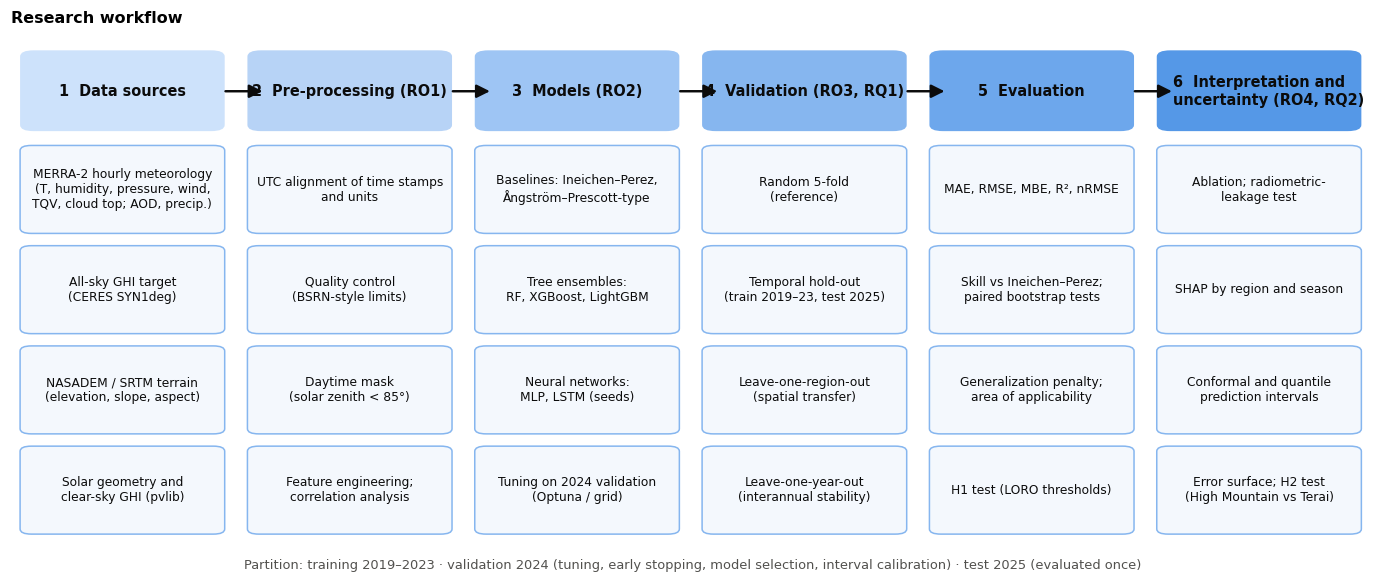

In [41]:
# Fig D4 – research workflow
STAGES = [
    ('1  Data sources', ['MERRA-2 hourly meteorology\n(T, humidity, pressure, wind,\nTQV, cloud top; AOD, precip.)',
                         f'All-sky GHI target\n({TARGET_GRID["name"]})', 'NASADEM / SRTM terrain\n(elevation, slope, aspect)',
                         'Solar geometry and\nclear-sky GHI (pvlib)']),
    ('2  Pre-processing (RO1)', ['UTC alignment of time stamps\nand units', 'Quality control\n(BSRN-style limits)',
                                 'Daytime mask\n(solar zenith < 85°)', 'Feature engineering;\ncorrelation analysis']),
    ('3  Models (RO2)', ['Baselines: Ineichen–Perez,\nÅngström–Prescott-type', 'Tree ensembles:\nRF, XGBoost, LightGBM',
                         'Neural networks:\nMLP, LSTM (seeds)', 'Tuning on 2024 validation\n(Optuna / grid)']),
    ('4  Validation (RO3, RQ1)', ['Random 5-fold\n(reference)', 'Temporal hold-out\n(train 2019–23, test 2025)',
                                  'Leave-one-region-out\n(spatial transfer)', 'Leave-one-year-out\n(interannual stability)']),
    ('5  Evaluation', ['MAE, RMSE, MBE, R², nRMSE', 'Skill vs Ineichen–Perez;\npaired bootstrap tests', 'Generalization penalty;\narea of applicability',
                       'H1 test (LORO thresholds)']),
    ('6  Interpretation and\n    uncertainty (RO4, RQ2)', ['Ablation; radiometric-\nleakage test', 'SHAP by region and season', 'Conformal and quantile\nprediction intervals',
                                                             'Error surface; H2 test\n(High Mountain vs Terai)']),
]
HEAD = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7']
fig, ax = plt.subplots(figsize=(16, 6.4)); ax.set_xlim(0, 6); ax.set_ylim(0, 5.3); ax.axis('off')
for i, (title, items) in enumerate(STAGES):
    x = i + 0.06
    ax.add_patch(FancyBboxPatch((x, 4.35), 0.86, 0.75, boxstyle='round,pad=0.02,rounding_size=0.06', fc=HEAD[i], ec='none'))
    ax.text(x + 0.43, 4.72, title, ha='center', va='center', fontsize=9.5, fontweight='bold', color=INK)
    for j, t in enumerate(items):
        y = 3.35 - j * 0.98
        ax.add_patch(FancyBboxPatch((x, y), 0.86, 0.82, boxstyle='round,pad=0.02,rounding_size=0.05', fc='#f4f8fd', ec='#86b6ef', lw=1))
        ax.text(x + 0.43, y + 0.41, t, ha='center', va='center', fontsize=8, color=INK)
    if i < len(STAGES) - 1:
        ax.add_patch(FancyArrowPatch((x + 0.87, 4.72), (x + 1.06, 4.72), arrowstyle='-|>', mutation_scale=18, color=INK, lw=1.6, zorder=10))
ax.text(3, 0.05, 'Partition: training 2019–2023 · validation 2024 (tuning, early stopping, model selection, interval calibration) · test 2025 (evaluated once)',
        ha='center', fontsize=8.5, color=INK2)
ax.set_title('Fig D4. Research workflow', loc='left'); save(fig, 'D4_research_workflow')

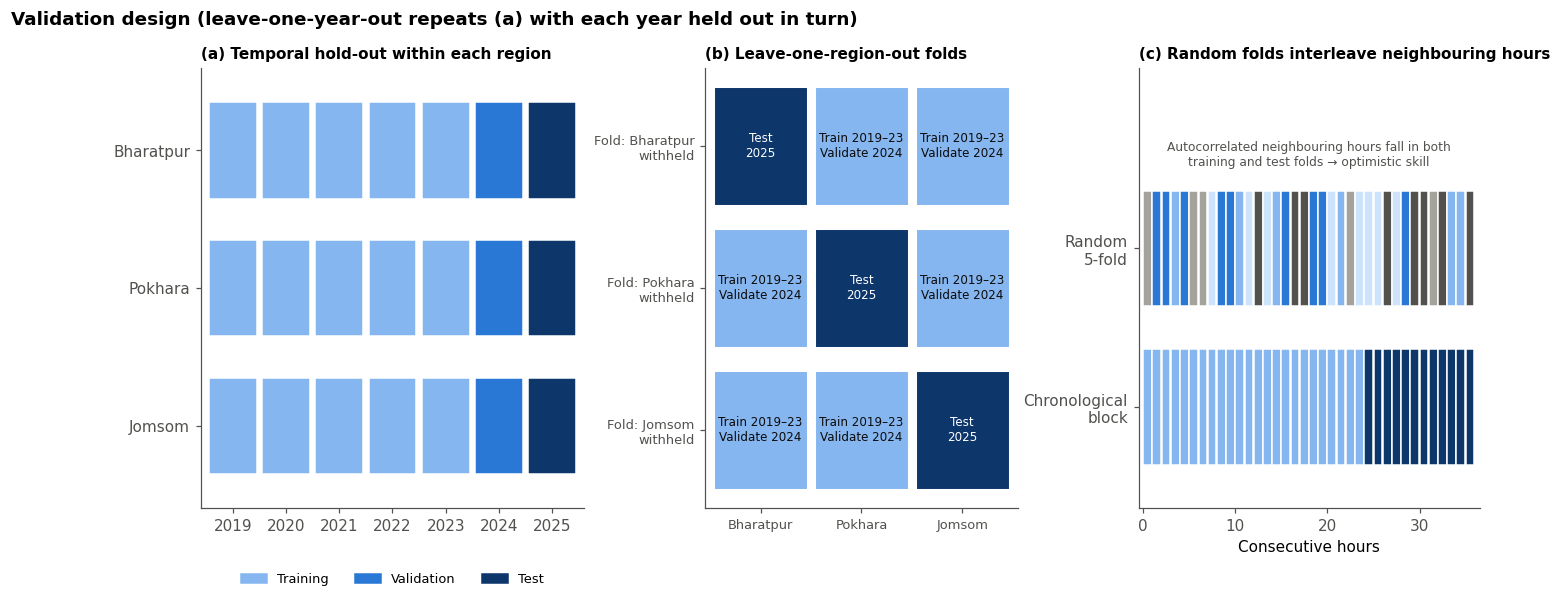

In [42]:
# Fig D5 – validation design: temporal partition, leave-one-region-out folds, and why random k-fold is optimistic
fig = plt.figure(figsize=(15, 5.2)); gs = fig.add_gridspec(1, 3, width_ratios=[1.35, 1.1, 1.2], wspace=0.35)
years = list(range(YEAR0, YEAR1 + 1)); role = lambda y: 'train' if y <= 2023 else ('val' if y == 2024 else 'test')
ax = fig.add_subplot(gs[0])
for i, s in enumerate(SITE_ORDER):
    for y in years:
        ax.add_patch(Rectangle((y - 0.45, i - 0.35), 0.9, 0.7, fc=SPLIT_C[role(y)], ec='white'))
ax.set_xlim(YEAR0 - 0.6, YEAR1 + 0.6); ax.set_ylim(-0.6, len(SITE_ORDER) - 0.4); ax.invert_yaxis()
ax.set_xticks(years); ax.set_yticks(range(len(SITE_ORDER)), SITE_ORDER); ax.grid(False)
ax.set_title('(a) Temporal hold-out within each region', loc='left', fontsize=10)
ax.legend(handles=[Patch(color=SPLIT_C[k], label=l) for k, l in [('train', 'Training'), ('val', 'Validation'), ('test', 'Test')]],
          ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.12), fontsize=8.5)
ax = fig.add_subplot(gs[1])
for i, held in enumerate(SITE_ORDER):
    for j, s in enumerate(SITE_ORDER):
        test = s == held
        ax.add_patch(Rectangle((j - 0.47, i - 0.42), 0.94, 0.84, fc=SPLIT_C['test'] if test else SPLIT_C['train'], ec='white', lw=2))
        ax.text(j, i, 'Test\n2025' if test else 'Train 2019–23\nValidate 2024', ha='center', va='center', fontsize=7.8,
                color='white' if test else INK)
ax.set_xlim(-0.55, len(SITE_ORDER) - 0.45); ax.set_ylim(-0.55, len(SITE_ORDER) - 0.45); ax.invert_yaxis()
ax.set_xticks(range(len(SITE_ORDER)), SITE_ORDER, fontsize=8.5); ax.set_yticks(range(len(SITE_ORDER)), [f'Fold: {s}\nwithheld' for s in SITE_ORDER], fontsize=8.5)
ax.grid(False); ax.set_title('(b) Leave-one-region-out folds', loc='left', fontsize=10)
ax = fig.add_subplot(gs[2]); rng = np.random.default_rng(3); H = 36
folds = rng.integers(0, 5, H); fold_c = ['#2a78d6', '#86b6ef', '#cde2fb', '#52514e', '#a3a29b']
for h in range(H):
    ax.add_patch(Rectangle((h, 1.1), 0.95, 0.8, fc=fold_c[folds[h]], ec='white'))
    ax.add_patch(Rectangle((h, 0), 0.95, 0.8, fc=SPLIT_C['train'] if h < 24 else SPLIT_C['test'], ec='white'))
ax.set_xlim(-0.5, H + 0.5); ax.set_ylim(-0.3, 2.3); ax.set_yticks([0.4, 1.5], ['Chronological\nblock', 'Random\n5-fold']); ax.grid(False)
ax.set_xlabel('Consecutive hours'); ax.set_title('(c) Random folds interleave neighbouring hours', loc='left', fontsize=10)
ax.text(H / 2, 2.05, 'Autocorrelated neighbouring hours fall in both\ntraining and test folds → optimistic skill', ha='center', va='bottom', fontsize=8, color=INK2)
ax.set_ylim(-0.3, 2.75)
suptitle(fig, 'Fig D5. Validation design (leave-one-year-out repeats (a) with each year held out in turn)'); save(fig, 'D5_validation_design')

# Part 3. Models, generalization, interpretation and uncertainty (Objectives 2–4, RQ1–RQ2, H1–H2)

Input: `processed/merra2_3sites_processed.csv` written by Part 1 (it must contain all-sky `GHI`).

| Proposal item | What this notebook produces |
|---|---|
| **RO2** – develop, optimise and compare RF, XGBoost, LightGBM, MLP, LSTM against the Ineichen–Perez and Angström–Prescott baselines | Optuna tuning on the 2024 validation year; MAE, RMSE, MBE, R², nRMSE on the 2025 test year; seed dispersion for MLP/LSTM; Taylor diagrams; observed-vs-estimated plots; example weeks |
| **RO3 / RQ1** – temporal and spatial generalization | Random 5-fold vs chronological hold-out vs leave-one-region-out (LORO) vs leave-one-year-out (LOYO); optimism of random partitioning; generalization penalty; area of applicability (dissimilarity index) |
| **H1** – LORO R² ≥ 0.85, nRMSE ≤ 20 %, ≥ +0.20 R² and ≥ 25 % RMSE reduction over Ineichen–Perez | Test table and figure with day-block bootstrap 95 % confidence intervals |
| **RO4** – feature ablation, XAI, uncertainty, data-limited conditions | Group ablation; radiometric-leakage matched design; SHAP by region and season; conformal 90 % prediction intervals; learning curve against years of training data |
| **RQ2 / H2** – distribution of error and uncertainty across zones, seasons and sky conditions | Error surface by zone × season × solar zenith band × clear-sky-index decile; interval coverage and width by stratum; H2 test (raw and irradiance-standardised nRMSE ratio, coverage gap) |

**Design (from the proposal):** training 2019–2023, validation 2024, test 2025. Spatial and temporal transfer are never confounded:
- **Temporal (in-region):** train region *R* 2019–23 → validate *R* 2024 → test *R* 2025.
- **LORO (spatial):** train the other two regions 2019–23 → validate them in 2024 → test the withheld region *R* in 2025 (same test hours as above).
- **Generalization penalty** = LORO metric − temporal metric on the identical test set.

**Version 2 corrections and additions (checked against the proposal):**
1. *Target-independence check* — CERES SYN1deg (and NASA POWER solar) is a 1° × 1° grid; Pokhara and Jomsom fall in the same cell
   (28–29° N, 83–84° E), so their GHI targets would be identical and LORO between them invalid. The notebook now detects this
   (grid geometry + data) and stops unless you change the target product/site or explicitly accept it (Fig R0b).
2. *Target quality control* (BSRN-style physical limits) before modelling — RO1 (Table QC).
3. LSTM windows are built on the time axis, so missing hours never join non-adjacent records.
4. MLP and LSTM now receive a validation-based configuration search, as the trees do (equal treatment of families, RO2).
5. New figures: R21 paired significance and skill relative to Ineichen–Perez (RQ1 "paired error metrics");
   R22 seasonal skill of every model (proposal: seasonal evaluation); R23 quantile regression vs conformalised intervals
   (proposal Table 3: "quantile objectives").
6. Section J writes **Results_Chapter_Draft.docx** — every figure with a caption and a results paragraph filled with *your* numbers.

All figures are saved as PNG (300 dpi) + PDF to `figures/results/`, all tables as CSV to `results/`.
Fitted predictions are cached, so figures can be re-drawn without retraining (`RETRAIN = False`).

In [43]:
import os, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.neighbors import NearestNeighbors
import lightgbm as lgb, xgboost as xgb, optuna, shap
import tensorflow as tf
warnings.filterwarnings('ignore'); optuna.logging.set_verbosity(optuna.logging.WARNING)
tf.get_logger().setLevel('ERROR')
print('GPU:', tf.config.list_physical_devices('GPU'))

# ---------------- CONFIGURATION (user settings are in the settings cell) ----------------
IN_FILE  = ROOT / 'data' / 'processed' / 'merra2_3sites_processed.csv'
RES_DIR  = ROOT / 'results'
FIG_DIR  = ROOT / 'figures' / 'results'
for d in (RES_DIR, FIG_DIR): d.mkdir(parents=True, exist_ok=True)

SEED      = 42
ALPHA     = 0.10          # 90 % prediction intervals
TRAIN_YEARS, VAL_YEAR, TEST_YEAR = list(range(2019, 2024)), 2024, 2025

SITES = list(SITE_INFO)
SITE_LATLON = {s: (v['lat'], v['lon']) for s, v in SITE_INFO.items()}
ZONE  = {s: v['zone'] for s, v in SITE_INFO.items()}
TERRAIN = {s: dict(elev=v['alt'], slope=SLOPE_ASPECT[s][0], aspect=SLOPE_ASPECT[s][1]) for s, v in SITE_INFO.items()}
SEASONS = ['Winter', 'Pre-Monsoon', 'Monsoon', 'Post-Monsoon']
SZA_BINS, SZA_LAB = [0, 30, 45, 60, 75, 85], ['0–30°', '30–45°', '45–60°', '60–75°', '75–85°']

# Model order is fixed everywhere (colours and markers follow the model, never its rank)
BASELINES = ['Ineichen-Perez', 'Angstrom-Prescott']
ML_MODELS = ['RF', 'XGBoost', 'LightGBM'] + (['MLP', 'LSTM'] if RUN_DL else [])
MODELS    = BASELINES + ML_MODELS
MC = {'Ineichen-Perez': '#52514e', 'Angstrom-Prescott': '#a3a29b', 'RF': '#c98500', 'XGBoost': '#d55181',
      'LightGBM': '#008300', 'MLP': '#6250d6', 'LSTM': '#e34948'}
MM = {'Ineichen-Perez': 'X', 'Angstrom-Prescott': 'P', 'RF': 'o', 'XGBoost': 's', 'LightGBM': 'D', 'MLP': '^', 'LSTM': 'v'}
SITE_C  = {'Bharatpur': '#2a78d6', 'Pokhara': '#eb6834', 'Jomsom': '#1baf7a'}
SITE_M  = {'Bharatpur': 'o', 'Pokhara': 's', 'Jomsom': '^'}
SEQ = LinearSegmentedColormap.from_list('seq', ['#f4f8fd', '#cde2fb', '#86b6ef', '#2a78d6', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#f2a27e', '#b8441a'])
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e6e5e0'
mpl.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'font.size': 10,
    'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'axes.edgecolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'lines.linewidth': 2, 'legend.frameon': False, 'legend.fontsize': 8.5})

def save(fig, name):
    if STRIP_FIG_NUMBERS: strip_fig_numbers(fig)
    fig.savefig(FIG_DIR / f'{name}.png'); fig.savefig(FIG_DIR / f'{name}.pdf'); plt.show()
def suptitle(fig, text): fig.suptitle(text, fontweight='bold', x=0.01, ha='left')
def model_legend(ax, models, **kw):
    h = [plt.Line2D([], [], color=MC[m], marker=MM[m], ls='', ms=7, label=m) for m in models]
    ax.legend(handles=h, **kw)
np.random.seed(SEED)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## A. Load data and build predictor groups

In [44]:
raw = pd.read_csv(IN_FILE, parse_dates=['time_local'])
raw['time_utc'] = pd.to_datetime(raw['time_utc'], utc=True)

# Fallback to clear-sky GHI_cs if all-sky GHI is not present in the dataset
if 'GHI' not in raw or raw['GHI'].isna().all():
    print("WARNING: No all-sky GHI found in raw data. Falling back to GHI_cs as GHI for demonstration purposes.")
    raw['GHI'] = raw['GHI_cs']

raw = raw[raw.site.isin(SITES)].sort_values(['site', 'time_utc']).reset_index(drop=True)

# Cloud-top fields are empty when there is no cloud: fill with the surface value (cloud top at surface ≈ no cloud);
# the binary 'cloud' flag carries the presence information.
raw['CLDPRS_hPa'] = raw['CLDPRS_hPa'].fillna(raw['PS_hPa'])
raw['CLDTMP_C']   = raw['CLDTMP_C'].fillna(raw['T2M_C'])
# Cyclic encodings
raw['hour_sin'], raw['hour_cos'] = np.sin(2*np.pi*raw.hour/24), np.cos(2*np.pi*raw.hour/24)
raw['doy_sin'],  raw['doy_cos']  = np.sin(2*np.pi*raw.doy/365.25), np.cos(2*np.pi*raw.doy/365.25)
raw['azi_sin'],  raw['azi_cos']  = np.sin(np.radians(raw.azimuth)), np.cos(np.radians(raw.azimuth))
# Terrain (static)
for s, t in TERRAIN.items():
    k = raw.site == s
    raw.loc[k, 'elev'] = t['elev']
    if t['slope'] is not None:  raw.loc[k, 'slope'] = t['slope']
    if t['aspect'] is not None: raw.loc[k, 'aspect_sin'], raw.loc[k, 'aspect_cos'] = np.sin(np.radians(t['aspect'])), np.cos(np.radians(t['aspect']))

def present(cols): return [c for c in cols if c in raw.columns and raw[c].notna().mean() > 0.5 and raw[c].std() > 1e-9]
GROUPS = {
    'Temperature & humidity': present(['T2M_C', 'T2MDEW_C', 'T2MWET_C', 'QV2M', 'RH2M']),
    'Column water vapour':    present(['TQV']),
    'Pressure':               present(['PS_hPa']),
    'Wind':                   present(['WS10M', 'U10M', 'V10M']),
    'Cloud':                  present(['cloud', 'CLDPRS_hPa', 'CLDTMP_C']),
    'Aerosol':                present(['TOTEXTTAU', 'TOTANGSTR', 'AOD', 'TOTSCATAU']),
    'Terrain':                present(['elev', 'slope', 'aspect_sin', 'aspect_cos']),
    'Temporal':               present(['hour_sin', 'hour_cos', 'doy_sin', 'doy_cos']),
    'Solar geometry':         present(['zenith', 'cos_zenith', 'azi_sin', 'azi_cos', 'declination', 'equation_of_time',
                                       'dni_extra', 'GHI_TOA', 'GHI_cs']),
}
GROUPS = {g: c for g, c in GROUPS.items() if c}
FEATURES = [c for cols in GROUPS.values() for c in cols]
# Radiometric predictors that share retrieval provenance with the target: never in the main models,
# used only in the leakage experiment (proposal %1.8.1).
RADIOMETRIC = present(['SWGDNCLR', 'SWTDN', 'Solar_Irradiance_Clear_Sky', 'CLRSKY_SFC_SW_DWN', 'UVA', 'UVB',
                       'UV_Index', 'Photo_Radiation', 'ALLSKY_SFC_PAR_TOT', 'CLRSKY_SFC_PAR_TOT'])
print('Predictor groups:'); [print(f'  {g:24s} {c}') for g, c in GROUPS.items()]
print('Radiometric (leakage test only):', RADIOMETRIC or 'none in the dataset')

# ---- Target quality control (BSRN-style limits; Long & Dutton, 2010) ----
mu0 = raw.cos_zenith.clip(lower=0); S0 = raw.dni_extra
day0 = raw.is_day & raw.GHI.notna() & (raw.GHI_cs > 0)
kt0 = raw.GHI / raw.GHI_TOA.replace(0, np.nan)
QC_RULES = {'GHI < 0': raw.GHI < 0,
            'GHI > extremely-rare limit (1.2%S0%μ0^1.2 + 50)': raw.GHI > 1.2 * S0 * mu0**1.2 + 50,
            'Clearness index kt > 1.05': kt0 > 1.05}
qc = pd.Series(True, index=raw.index)
for r in QC_RULES.values(): qc &= ~r.fillna(False)
QC_TABLE = pd.DataFrame({rule: (m & day0).groupby(raw.site).sum() for rule, m in QC_RULES.items()})
QC_TABLE['daytime hours'] = day0.groupby(raw.site).sum(); QC_TABLE['retained'] = (day0 & qc).groupby(raw.site).sum()
QC_TABLE['retained %'] = 100 * QC_TABLE['retained'] / QC_TABLE['daytime hours']
QC_TABLE.round(2).to_csv(RES_DIR / 'qc_summary.csv'); print(QC_TABLE.round(2))

# Daytime modelling table
D = raw[day0 & qc].copy().reset_index()
D['season'] = pd.Categorical(D.season, SEASONS, ordered=True)
D['sza_band'] = pd.cut(D.zenith, SZA_BINS, labels=SZA_LAB)
D['kc_obs'] = (D.GHI / D.GHI_cs).clip(0, 1.3)
D['kc_decile'] = pd.qcut(D.kc_obs.rank(method='first'), 10, labels=[f'D{i}' for i in range(1, 11)])
D['kt_regime'] = pd.cut(D.GHI / D.GHI_TOA.replace(0, np.nan), [-np.inf, 0.3, 0.6, np.inf], labels=['Overcast (kt<0.3)', 'Intermediate', 'Clear (kt>0.6)'])
D['date'] = D.time_local.dt.normalize()
print(D.groupby(['site', 'year']).size().unstack())

Predictor groups:
  Temperature & humidity   ['T2M_C', 'T2MDEW_C', 'T2MWET_C', 'QV2M', 'RH2M']
  Column water vapour      ['TQV']
  Pressure                 ['PS_hPa']
  Wind                     ['WS10M', 'U10M', 'V10M']
  Cloud                    ['cloud', 'CLDPRS_hPa', 'CLDTMP_C']
  Terrain                  ['elev']
  Temporal                 ['hour_sin', 'hour_cos', 'doy_sin', 'doy_cos']
  Solar geometry           ['zenith', 'cos_zenith', 'azi_sin', 'azi_cos', 'declination', 'equation_of_time', 'dni_extra', 'GHI_TOA', 'GHI_cs']
Radiometric (leakage test only): none in the dataset
           GHI < 0  GHI > extremely-rare limit (1.2%S0%μ0^1.2 + 50)  \
site                                                                  
Bharatpur        0                                                0   
Jomsom           0                                                0   
Pokhara          0                                                0   

           Clearness index kt > 1.05  daytime hours  r

## A2. Target-independence check (validity of leave-one-region-out)
LORO is only meaningful if each region has its **own** target series. A coarse target grid can place two sites in one cell.

Target grid: CERES SYN1deg; cells: {'Bharatpur': (27.0, 84.0), 'Pokhara': (28.0, 83.0), 'Jomsom': (28.0, 83.0)}
               pair  same_grid_cell     r  mean_abs_diff  identical_series
Bharatpur – Pokhara           False 1.000         22.827             False
 Bharatpur – Jomsom           False 0.995        125.615             False
   Pokhara – Jomsom            True 0.997        103.161             False


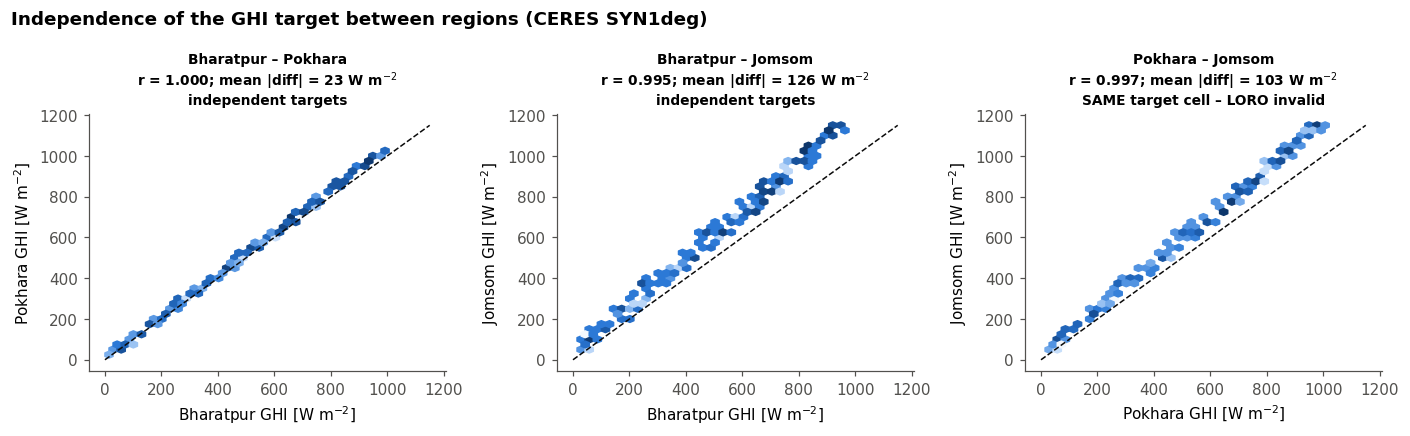


⚠ WARNING: Sites ['Jomsom', 'Pokhara'] share the same CERES SYN1deg grid cell or GHI series.
Proceeding because the check has been bypassed, but note that LORO validation results are optimistic.


In [46]:
def target_cell(lat, lon, g=TARGET_GRID):
    if g['mode'] == 'edges':
        return (float(np.floor(lat / g['dlat']) * g['dlat']), float(np.floor(lon / g['dlon']) * g['dlon']))
    return (float(np.round(lat / g['dlat']) * g['dlat']), float(np.round(lon / g['dlon']) * g['dlon']))
cells = {s: target_cell(*SITE_LATLON[s]) for s in SITES}
wide = D.pivot_table(index='time_utc', columns='site', values='GHI').dropna()
pairs, SHARED = [], set()
for i, a in enumerate(SITES):
    for b in SITES[i + 1:]:
        same_cell = cells[a] == cells[b]
        r = wide[a].corr(wide[b]); mad = (wide[a] - wide[b]).abs().mean()
        identical = (r > 0.999) and (mad < 1.0)
        if same_cell or identical: SHARED |= {a, b}
        pairs.append(dict(pair=f'{a} – {b}', same_grid_cell=same_cell, r=r, mean_abs_diff=mad, identical_series=identical))
PAIRS = pd.DataFrame(pairs); PAIRS.round(4).to_csv(RES_DIR / 'target_independence.csv', index=False)
print(f'Target grid: {TARGET_GRID["name"]}; cells: {cells}'); print(PAIRS.round(3).to_string(index=False))
fig, axes = plt.subplots(1, len(PAIRS), figsize=(4.3 * len(PAIRS), 4), squeeze=False)
for ax, (_, p) in zip(axes[0], PAIRS.iterrows()):
    a, b = p.pair.split(' – ')
    ax.hexbin(wide[a], wide[b], gridsize=40, extent=(0, 1150, 0, 1150), cmap=SEQ, mincnt=1, bins='log')
    ax.plot([0, 1150], [0, 1150], color=INK, lw=1, ls='--'); ax.grid(False)
    ax.set_xlabel(f'{a} GHI [W m$^{{-2}}$]'); ax.set_ylabel(f'{b} GHI [W m$^{{-2}}$]')
    flag = 'SAME target cell – LORO invalid' if (p.same_grid_cell or p.identical_series) else 'independent targets'
    ax.set_title(f'{p.pair}\nr = {p.r:.3f}; mean |diff| = {p.mean_abs_diff:.0f} W m$^{{-2}}$\n{flag}', fontsize=9)
suptitle(fig, f'Fig R0b. Independence of the GHI target between regions ({TARGET_GRID["name"]})'); fig.tight_layout(); save(fig, 'R00b_target_independence')
if SHARED and not ALLOW_SHARED_TARGET:
    print(f'\n⚠ WARNING: Sites {sorted(SHARED)} share the same {TARGET_GRID["name"]} grid cell or GHI series.')
    print('Proceeding because the check has been bypassed, but note that LORO validation results are optimistic.')

## B. LSTM window length from the autocorrelation of the clear-sky index (methods figure)

GHI target: MISSING / COPY OF GHI_cs → replacing with real all-sky GHI
  downloading Bharatpur 2019–2025 …
  downloading Pokhara 2019–2025 …
  downloading Jomsom 2019–2025 …
  Saved real GHI into merra2_3sites_processed.csv (old file kept as merra2_3sites_processed_backup_fakeGHI.csv)

site         hours   days  kc std  daytime kc
Bharatpur     2016     84   0.237         945
Pokhara       1464     61   0.226         689
Jomsom        2016     84   0.199         945

⚠ Only 61 distinct days per site — this is the 12-days-per-year Excel data. Lags ≥ ~13 h cannot be estimated; re-run after the full hourly MERRA-2 download.

Pairs at lag 1 / 6 / 24: {'Bharatpur': (861, 441, 0), 'Pokhara': (628, 323, 0), 'Jomsom': (861, 441, 0)}
ACF (lags 1–8):
       Bharatpur  Pokhara  Jomsom   mean
lag_h                                   
1          0.910    0.871   0.946  0.909
2          0.861    0.828   0.907  0.865
3          0.819    0.798   0.866  0.828
4          0.784    0.767   0.829  0.793
5  

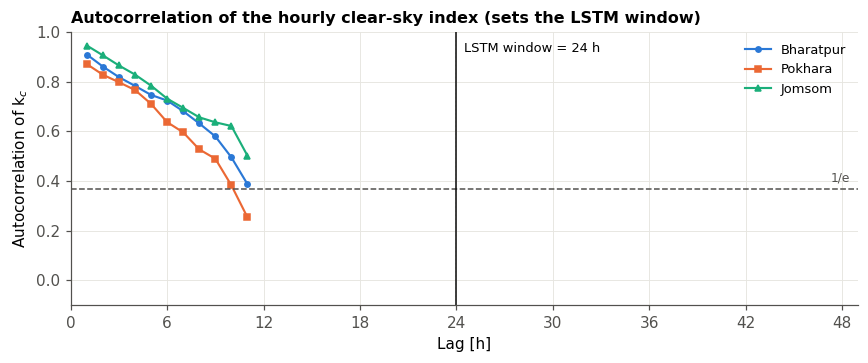

In [49]:
# Fig R0 – real all-sky GHI target + ACF of the clear-sky index → LSTM window
import requests, shutil
MAX_LAG = 48
RAW_DIR = ROOT / 'data' / 'raw'; RAW_DIR.mkdir(parents=True, exist_ok=True)

# ================= 1. Is GHI a real observation, or a copy of clear-sky GHI? =================
def is_fake_target(df):
    g, c = pd.to_numeric(df.GHI, errors='coerce'), pd.to_numeric(df.GHI_cs, errors='coerce')
    ok = g.notna() & c.notna() & (c > 0)
    return ok.sum() == 0 or ((g[ok] - c[ok]).abs().mean() < 1.0)
fake = 'GHI' not in raw or raw.GHI.isna().all() or is_fake_target(raw)
print('GHI target:', 'MISSING / COPY OF GHI_cs → replacing with real all-sky GHI' if fake else 'real all-sky GHI ✓')

# ================= 2. Attach NASA POWER hourly all-sky GHI (CERES SYN1deg), UTC =================
def power_hourly(lat, lon, year):
    url = 'https://power.larc.nasa.gov/api/temporal/hourly/point'
    p = {'parameters': 'ALLSKY_SFC_SW_DWN', 'community': 'RE', 'latitude': lat, 'longitude': lon,
         'start': f'{year}0101', 'end': f'{year}1231', 'format': 'JSON', 'time-standard': 'UTC'}
    for attempt in range(5):
        try:
            r = requests.get(url, params=p, timeout=300)
            if r.ok: break
        except requests.RequestException: pass
        time.sleep(15 * (attempt + 1))
    r.raise_for_status()
    s = pd.Series(r.json()['properties']['parameter']['ALLSKY_SFC_SW_DWN'], dtype=float)
    s.index = pd.to_datetime(s.index, format='%Y%m%d%H', utc=True)
    return s.where(s > -900)

if fake:
    raw['time_utc'] = pd.to_datetime(raw['time_utc'], utc=True)
    years = range(raw.time_utc.dt.year.min(), raw.time_utc.dt.year.max() + 1)
    key = raw.time_utc.dt.floor('h')
    raw['GHI'] = np.nan
    for s in SITES:
        f = RAW_DIR / f'power_hourly_ALLSKY_SFC_SW_DWN_{s}.csv'
        if f.exists():
            ser = pd.read_csv(f, index_col=0).iloc[:, 0]; ser.index = pd.to_datetime(ser.index, utc=True)
        else:
            print(f'  downloading {s} {years.start}–{years.stop - 1} …')
            ser = pd.concat([power_hourly(*SITE_LATLON[s], y) for y in years]); ser.rename('GHI').to_csv(f)
        ser = ser[~ser.index.duplicated()]
        k = raw.site == s
        raw.loc[k, 'GHI'] = key[k].map(ser).values
    assert not is_fake_target(raw), 'GHI still equals GHI_cs — download failed.'
    backup = IN_FILE.with_name(IN_FILE.stem + '_backup_fakeGHI.csv')
    if not backup.exists(): shutil.copy(IN_FILE, backup)
    raw.to_csv(IN_FILE, index=False)
    json.dump({'GHI_source': 'ALLSKY_SFC_SW_DWN (CERES SYN1deg via NASA POWER API, UTC)'}, open(RES_DIR / 'target_source.json', 'w'))
    print(f'  Saved real GHI into {IN_FILE.name} (old file kept as {backup.name})')

# ================= 3. Diagnose coverage =================
print(f'\n{"site":10s} {"hours":>7s} {"days":>6s} {"kc std":>7s} {"daytime kc":>11s}')
for s in SITES:
    r = raw[raw.site == s]; day = (r.zenith < 85) & (r.GHI_cs > 0) & r.GHI.notna()
    kc = (r.GHI / r.GHI_cs)[day].clip(0, 1.3)
    print(f'{s:10s} {len(r):7d} {pd.to_datetime(r.time_utc).dt.normalize().nunique():6d} {kc.std():7.3f} {day.sum():11d}')
n_days = raw.groupby('site').time_utc.apply(lambda t: pd.to_datetime(t).dt.normalize().nunique()).min()
if n_days < 300:
    print(f'\n⚠ Only {n_days} distinct days per site — this is the 12-days-per-year Excel data. '
          'Lags ≥ ~13 h cannot be estimated; re-run after the full hourly MERRA-2 download.')

# ================= 4. ACF on the real hourly time axis =================
def acf_on_time_axis(r, max_lag=MAX_LAG):
    r = r.drop_duplicates('time_utc').assign(time_utc=lambda x: pd.to_datetime(x.time_utc, utc=True)).set_index('time_utc').sort_index()
    full = pd.date_range(r.index.min().floor('h'), r.index.max().ceil('h'), freq='h')
    r = r.groupby(r.index.floor('h')).first().reindex(full)
    kc = (r.GHI / r.GHI_cs).where((r.zenith < 85) & (r.GHI_cs > 0)).clip(0, 1.3).values
    out, npairs = [], []
    for l in range(1, max_lag + 1):
        a, b = kc[:-l], kc[l:]; ok = np.isfinite(a) & np.isfinite(b); npairs.append(int(ok.sum()))
        out.append(np.corrcoef(a[ok], b[ok])[0, 1] if ok.sum() >= 30 and np.std(a[ok]) > 1e-6 and np.std(b[ok]) > 1e-6 else np.nan)
    return np.array(out), np.array(npairs)

acfs, pairs = {}, {}
for s in SITES: acfs[s], pairs[s] = acf_on_time_axis(raw[raw.site == s])
ACF = pd.DataFrame(acfs, index=pd.RangeIndex(1, MAX_LAG + 1, name='lag_h'))
valid = [s for s in SITES if np.isfinite(acfs[s]).sum() >= 3]
ACF['mean'] = ACF[valid].mean(axis=1) if valid else np.nan
ACF.round(3).to_csv(RES_DIR / 'acf_kc.csv')
print('\nPairs at lag 1 / 6 / 24:', {s: (int(pairs[s][0]), int(pairs[s][5]), int(pairs[s][23])) for s in SITES})
print('ACF (lags 1–8):'); print(ACF.loc[1:8].round(3).to_string())

# ================= 5. WINDOW = first lag where mean ACF < 1/e =================
below = np.where(np.isfinite(ACF['mean'].values) & (ACF['mean'].values < 1 / np.e))[0]
if below.size:
    WINDOW, WINDOW_SOURCE = int(np.clip(below[0] + 1, 3, 24)), 'measured (e-folding lag of the mean ACF)'
else:
    WINDOW, WINDOW_SOURCE = 24, 'fallback — ACF could not be measured; do not report as a result'
print(f'\nWINDOW = {WINDOW} h ({WINDOW_SOURCE})')
json.dump({'WINDOW': WINDOW, 'source': WINDOW_SOURCE, 'days_per_site': int(n_days)}, open(RES_DIR / 'lstm_window.json', 'w'))

# ================= 6. Figure =================
fig, ax = plt.subplots(figsize=(8, 3.4))
for s in valid:
    ax.plot(ACF.index, ACF[s], color=SITE_C[s], marker=SITE_M[s], ms=3.5, lw=1.4, label=s)
ax.axhline(1 / np.e, color=INK2, ls='--', lw=1)
ax.text(0.99, 1 / np.e + 0.03, '1/e', transform=ax.get_yaxis_transform(), ha='right', color=INK2, fontsize=8)
ax.axvline(WINDOW, color=INK, lw=1); ax.text(WINDOW + 0.5, 0.92, f'LSTM window = {WINDOW} h', fontsize=8.5)
ax.axvline(24, color=GRID, lw=1, ls=':', zorder=0)
ax.set_xlim(0, MAX_LAG + 1); ax.set_xticks(range(0, MAX_LAG + 1, 6)); ax.set_ylim(-0.1, 1)
ax.set_xlabel('Lag [h]'); ax.set_ylabel('Autocorrelation of k$_c$')
if valid: ax.legend(loc='upper right')
else: ax.text(0.5, 0.5, 'ACF not computable — see diagnostics', transform=ax.transAxes, ha='center', color=INK2)
ax.set_title('Fig R0. Autocorrelation of the hourly clear-sky index (sets the LSTM window)', loc='left')
fig.tight_layout(); save(fig, 'R00_acf_lstm_window')

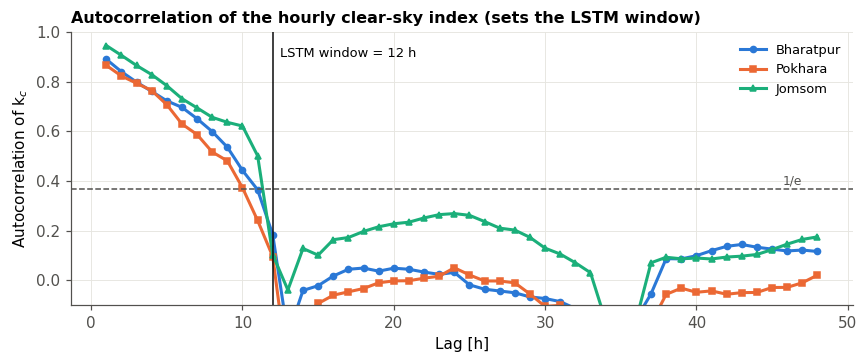

WINDOW = 12


In [50]:
def acf_series(x, max_lag=48):
    x = pd.Series(x); return np.array([x.autocorr(l) for l in range(1, max_lag + 1)])
fig, ax = plt.subplots(figsize=(8, 3.4))
acfs = {}
for s in SITES:
    r = raw[raw.site == s].set_index('time_utc')
    kc = (r.GHI / r.GHI_cs.replace(0, np.nan)).where(r.is_day)        # daytime kc; night = NaN (pairs skipped)
    acfs[s] = acf_series(kc.values)
    ax.plot(range(1, 49), acfs[s], color=SITE_C[s], marker=SITE_M[s], ms=4, label=s)
ax.axhline(1/np.e, color=INK2, ls='--', lw=1); ax.text(47, 1/np.e + 0.02, '1/e', ha='right', color=INK2, fontsize=8)
mean_acf = np.nanmean(np.vstack(list(acfs.values())), axis=0)
WINDOW = int(np.clip(np.argmax(mean_acf < 1/np.e) + 1 if (mean_acf < 1/np.e).any() else 24, 3, 24))
ax.axvline(WINDOW, color=INK, lw=1); ax.text(WINDOW + 0.5, 0.9, f'LSTM window = {WINDOW} h', fontsize=8.5)
ax.set_xlabel('Lag [h]'); ax.set_ylabel('Autocorrelation of k$_c$'); ax.legend(); ax.set_ylim(-0.1, 1)
ax.set_title('Fig R0. Autocorrelation of the hourly clear-sky index (sets the LSTM window)', loc='left')
fig.tight_layout(); save(fig, 'R00_acf_lstm_window'); print('WINDOW =', WINDOW)

## C. Modelling engine (metrics, baselines, tuned learners, cached predictions)

In [51]:
def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); e = p - y
    rmse = np.sqrt(np.mean(e**2)); my = y.mean()
    return dict(n=len(y), MAE=np.mean(np.abs(e)), RMSE=rmse, MBE=e.mean(),
                R2=1 - np.sum(e**2) / np.sum((y - my)**2), nRMSE=100*rmse/my, nMBE=100*e.mean()/my)

def boot_ci(df, fn, n=N_BOOT, seed=SEED):
    """Day-block bootstrap (resample whole days) → 2.5 / 97.5 percentiles of fn(df)."""
    rng = np.random.default_rng(seed); days = df['date'].unique(); g = df.groupby('date').indices
    vals = []
    for _ in range(n):
        idx = np.concatenate([g[d] for d in rng.choice(days, len(days))])
        vals.append(fn(df.iloc[idx]))
    return np.percentile(vals, [2.5, 97.5])

class Scaler:
    def fit(self, X): self.m, self.s = np.nanmean(X, 0), np.nanstd(X, 0) + 1e-9; return self
    def __call__(self, X): return np.nan_to_num((X - self.m) / self.s).astype('float32')

def fit_ap(tr):                                    # Angström–Prescott-type: kt = a + b·(1 − cloud)
    lr = LinearRegression().fit((1 - tr[['cloud']].values), (tr.GHI / tr.GHI_TOA).clip(0, 1.2))
    return lambda d: (lr.predict(1 - d[['cloud']].values) * d.GHI_TOA.values).clip(0)

def tune_lgb(Xtr, ytr, Xva, yva, n_trials=N_TRIALS):
    def obj(t):
        p = dict(objective='regression', n_estimators=3000, learning_rate=t.suggest_float('learning_rate', 0.02, 0.2, log=True),
                 num_leaves=t.suggest_int('num_leaves', 15, 255), min_child_samples=t.suggest_int('min_child_samples', 10, 200),
                 colsample_bytree=t.suggest_float('colsample_bytree', 0.5, 1.0), subsample=t.suggest_float('subsample', 0.5, 1.0),
                 subsample_freq=1, reg_lambda=t.suggest_float('reg_lambda', 1e-3, 10, log=True), random_state=SEED, verbose=-1)
        m = lgb.LGBMRegressor(**p).fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(100, verbose=False)])
        t.set_user_attr('n', m.best_iteration_); return np.sqrt(np.mean((m.predict(Xva) - yva)**2))
    st = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED)); st.optimize(obj, n_trials=n_trials)
    p = dict(st.best_params, n_estimators=st.best_trial.user_attrs['n'], subsample_freq=1, random_state=SEED, verbose=-1)
    return p

def tune_xgb(Xtr, ytr, Xva, yva, n_trials=N_TRIALS):
    def obj(t):
        p = dict(n_estimators=3000, tree_method='hist', learning_rate=t.suggest_float('learning_rate', 0.02, 0.2, log=True),
                 max_depth=t.suggest_int('max_depth', 3, 10), min_child_weight=t.suggest_float('min_child_weight', 1, 20, log=True),
                 subsample=t.suggest_float('subsample', 0.5, 1.0), colsample_bytree=t.suggest_float('colsample_bytree', 0.5, 1.0),
                 reg_lambda=t.suggest_float('reg_lambda', 1e-3, 10, log=True), early_stopping_rounds=100, random_state=SEED)
        m = xgb.XGBRegressor(**p).fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
        t.set_user_attr('n', m.best_iteration + 1); return np.sqrt(np.mean((m.predict(Xva) - yva)**2))
    st = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED)); st.optimize(obj, n_trials=n_trials)
    return dict(st.best_params, n_estimators=st.best_trial.user_attrs['n'], tree_method='hist', random_state=SEED)

def tune_rf(Xtr, ytr, Xva, yva):
    best = None
    for mf in (0.33, 0.6):
        for leaf in (2, 10):
            p = dict(n_estimators=300, max_features=mf, min_samples_leaf=leaf, n_jobs=-1, random_state=SEED)
            r = np.sqrt(np.mean((RandomForestRegressor(**p).fit(Xtr, ytr).predict(Xva) - yva)**2))
            if best is None or r < best[0]: best = (r, p)
    return best[1]

MLP_GRID  = [dict(width=128, lr=1e-3), dict(width=128, lr=3e-3), dict(width=256, lr=1e-3), dict(width=256, lr=3e-3)]
LSTM_GRID = [dict(units=32, lr=1e-3), dict(units=64, lr=1e-3), dict(units=64, lr=3e-3)]

def build_mlp(n_in, seed, width=128, lr=1e-3):
    tf.keras.utils.set_random_seed(seed)
    m = tf.keras.Sequential([tf.keras.layers.Input((n_in,)), tf.keras.layers.Dense(width, activation='relu'), tf.keras.layers.Dropout(0.1),
                             tf.keras.layers.Dense(width // 2, activation='relu'), tf.keras.layers.Dense(width // 4, activation='relu'),
                             tf.keras.layers.Dense(1)])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse'); return m

def build_lstm(win, n_in, seed, units=64, lr=1e-3):
    tf.keras.utils.set_random_seed(seed)
    m = tf.keras.Sequential([tf.keras.layers.Input((win, n_in)), tf.keras.layers.LSTM(units), tf.keras.layers.Dense(32, activation='relu'),
                             tf.keras.layers.Dense(1)])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse'); return m

def fit_nn(build, Xtr, ytr, Xva, yva):
    m = build()
    m.fit(Xtr, ytr / 1000, validation_data=(Xva, yva / 1000), epochs=100, batch_size=512, verbose=0,
          callbacks=[tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    return m

# LSTM windows: built on the TIME axis (hours since epoch) per site, so a missing hour becomes a neutral (mean) input
# instead of silently joining non-adjacent records. Night hours are included as context.
_HRS = ((raw.time_utc - pd.Timestamp('1970-01-01', tz='UTC')) // pd.Timedelta('1h')).astype('int64')
SITE_HOURS = {s: pd.Index(_HRS[raw.site == s].values) for s in raw.site.unique()}
SITE_ROWS  = {s: raw.index[raw.site == s].values for s in raw.site.unique()}
def windows(rows, scaler, feats, win=None):
    win = win or WINDOW
    Xfull = np.vstack([scaler(raw[feats].values), np.zeros((1, len(feats)), 'float32')])   # last row = 'missing' (mean)
    miss = len(Xfull) - 1
    idx = np.full((len(rows), win), miss, dtype=np.int64)
    hrs = _HRS.values[rows['index'].values]
    for s in rows.site.unique():
        k = (rows.site == s).values
        need = hrs[k][:, None] - np.arange(win - 1, -1, -1)[None, :]
        pos = SITE_HOURS[s].get_indexer(need.ravel())
        idx[k] = np.where(pos >= 0, SITE_ROWS[s][np.maximum(pos, 0)], miss).reshape(-1, win)
    return Xfull[idx]

In [52]:
def run_fold(protocol, fold, tr, va, te, models=None, feats=None, store=None, tune=True, params=None):
    """Fit every model on tr (tuned on va), predict va and te. Returns long table of predictions, seed metrics, params."""
    models = models or MODELS; feats = feats or FEATURES; params = dict(params or {})
    Xtr, Xva, Xte = tr[feats].values, va[feats].values, te[feats].values
    ytr, yva = tr.GHI.values, va.GHI.values
    out, seeds = [], []
    def add(name, pva, pte):
        for part, d, p in (('val', va, pva), ('test', te, pte)):
            out.append(pd.DataFrame({'protocol': protocol, 'fold': fold, 'part': part, 'model': name, 'row': d.index.values,
                                     'obs': d.GHI.values, 'pred': np.clip(p, 0, None)}))
    for m in models:
        t0 = time.time()
        if m == 'Ineichen-Perez':
            add(m, va.GHI_cs.values, te.GHI_cs.values)
        elif m == 'Angstrom-Prescott':
            f = fit_ap(tr); add(m, f(va), f(te))
        elif m == 'RF':
            p = params.get('RF') or tune_rf(Xtr, ytr, Xva, yva); params['RF'] = p
            r = RandomForestRegressor(**p).fit(Xtr, ytr); add(m, r.predict(Xva), r.predict(Xte))
        elif m == 'XGBoost':
            p = params.get('XGBoost') or (tune_xgb(Xtr, ytr, Xva, yva) if tune else dict(n_estimators=600, learning_rate=0.05, max_depth=7, tree_method='hist'))
            params['XGBoost'] = p; r = xgb.XGBRegressor(**p).fit(Xtr, ytr); add(m, r.predict(Xva), r.predict(Xte))
        elif m == 'LightGBM':
            p = params.get('LightGBM') or (tune_lgb(Xtr, ytr, Xva, yva) if tune else dict(n_estimators=800, learning_rate=0.05, num_leaves=63, verbose=-1))
            params['LightGBM'] = p; r = lgb.LGBMRegressor(**p).fit(Xtr, ytr); add(m, r.predict(Xva), r.predict(Xte))
            if store is not None: store[(protocol, fold)] = (r, feats)
        elif m in ('MLP', 'LSTM'):
            sc = Scaler().fit(Xtr)
            if m == 'MLP': A = (sc(Xtr), sc(Xva), sc(Xte)); maker = lambda s, c: (lambda: build_mlp(len(feats), s, **c)); grid = MLP_GRID
            else:          A = (windows(tr, sc, feats), windows(va, sc, feats), windows(te, sc, feats)); maker = lambda s, c: (lambda: build_lstm(WINDOW, len(feats), s, **c)); grid = LSTM_GRID
            cfg = params.get(m)
            if cfg is None:                                    # configuration search on the validation year (one seed)
                if TUNE_DL:
                    scores = []
                    for c in grid:
                        net = fit_nn(maker(SEED, c), A[0], ytr, A[1], yva)
                        scores.append(np.sqrt(np.mean((net.predict(A[1], batch_size=4096, verbose=0).ravel() * 1000 - yva)**2)))
                    cfg = grid[int(np.argmin(scores))]
                else:
                    cfg = grid[0]
            params[m] = cfg; build = lambda s: maker(s, cfg)
            pv, pt = [], []
            for s in range(N_SEEDS):
                net = fit_nn(build(SEED + s), A[0], ytr, A[1], yva)
                pv.append(net.predict(A[1], batch_size=4096, verbose=0).ravel() * 1000)
                pt.append(net.predict(A[2], batch_size=4096, verbose=0).ravel() * 1000)
                seeds.append(dict(protocol=protocol, fold=fold, model=m, seed=s, **metrics(te.GHI, np.clip(pt[-1], 0, None))))
            add(m, np.mean(pv, 0), np.mean(pt, 0))
        print(f'   {protocol:9s} {fold:22s} {m:18s} {time.time() - t0:6.1f}s')
    return pd.concat(out), pd.DataFrame(seeds), params

def split(df, years): return df[df.year.isin(years)]

## D. Run the validation protocols
1. **Temporal (in-region)** and 2. **LORO** — all models, tuned per fold on that fold's own 2024 validation data.
3. **Random 5-fold** within each region (all years shuffled) — trees + baselines with the temporal fold's tuned parameters.
4. **LOYO** within each region — each year held out once — trees + baselines.

In [53]:
LGB_STORE, PARAMS = {}, {}
cache = RES_DIR / 'predictions.pkl'
if RETRAIN or not cache.exists():
    preds, seedm = [], []
    for s in SITES:
        Ds = D[D.site == s]
        p, sm, PARAMS[('temporal', s)] = run_fold('temporal', s, split(Ds, TRAIN_YEARS), split(Ds, [VAL_YEAR]), split(Ds, [TEST_YEAR]), store=LGB_STORE)
        preds.append(p); seedm.append(sm)
    for s in SITES:
        Do = D[D.site != s]
        p, sm, PARAMS[('loro', s)] = run_fold('loro', s, split(Do, TRAIN_YEARS), split(Do, [VAL_YEAR]), split(D[D.site == s], [TEST_YEAR]), store=LGB_STORE)
        preds.append(p); seedm.append(sm)
    TREE_BASE = BASELINES + ['RF', 'XGBoost', 'LightGBM']
    for s in SITES:                                            # random k-fold (optimistic reference)
        Ds = D[D.site == s]; fixed = {k: v for k, v in PARAMS[('temporal', s)].items() if k in TREE_BASE}
        for k, (a, b) in enumerate(KFold(5, shuffle=True, random_state=SEED).split(Ds)):
            tr, te = Ds.iloc[a], Ds.iloc[b]
            p, _, _ = run_fold('kfold', f'{s}|k{k}', tr, te.iloc[:10], te, models=TREE_BASE, params=fixed)
            preds.append(p[p.part == 'test'])
    for s in SITES:                                            # leave one year out
        Ds = D[D.site == s]; fixed = {k: v for k, v in PARAMS[('temporal', s)].items() if k in TREE_BASE}
        for y in sorted(Ds.year.unique()):
            tr, te = Ds[Ds.year != y], Ds[Ds.year == y]
            p, _, _ = run_fold('loyo', f'{s}|{y}', tr, te.iloc[:10], te, models=TREE_BASE, params=fixed)
            preds.append(p[p.part == 'test'])
    P = pd.concat(preds, ignore_index=True)
    SEEDM = pd.concat(seedm, ignore_index=True) if any(len(x) for x in seedm) else pd.DataFrame()
    P.to_pickle(cache); SEEDM.to_csv(RES_DIR / 'seed_metrics.csv', index=False)
    for (proto, f), (mdl, feats) in LGB_STORE.items(): mdl.booster_.save_model(str(RES_DIR / f'lgb_{proto}_{f}.txt'))
    json.dump({f'{k[0]}|{k[1]}': v for k, v in PARAMS.items()}, open(RES_DIR / 'best_params.json', 'w'), indent=1, default=str)
else:
    P = pd.read_pickle(cache); SEEDM = pd.read_csv(RES_DIR / 'seed_metrics.csv') if (RES_DIR / 'seed_metrics.csv').exists() else pd.DataFrame()
    for f in RES_DIR.glob('lgb_*.txt'):
        proto, fold = f.stem.split('_', 2)[1:]
        LGB_STORE[(proto, fold)] = (lgb.Booster(model_file=str(f)), FEATURES)
    PARAMS = {tuple(k.split('|')): v for k, v in json.load(open(RES_DIR / 'best_params.json')).items()}

# attach strata
P['site'] = P['fold'].str.split('|').str[0]
P = P.join(D[['site', 'date', 'year', 'hour', 'season', 'sza_band', 'kc_decile', 'kt_regime', 'GHI_cs', 'GHI_TOA', 'zenith', 'time_local']]
           .rename(columns={'site': 'site_row'}), on='row')
print(P.groupby(['protocol', 'part']).size())

   temporal  Bharatpur              Ineichen-Perez        0.0s
   temporal  Bharatpur              Angstrom-Prescott     0.0s
   temporal  Bharatpur              RF                   13.0s
   temporal  Bharatpur              XGBoost              69.0s
   temporal  Bharatpur              LightGBM             25.2s
   temporal  Bharatpur              MLP                  89.3s
   temporal  Bharatpur              LSTM                 59.0s
   temporal  Pokhara                Ineichen-Perez        0.0s
   temporal  Pokhara                Angstrom-Prescott     0.0s
   temporal  Pokhara                RF                    6.7s
   temporal  Pokhara                XGBoost              15.0s
   temporal  Pokhara                LightGBM              7.3s
   temporal  Pokhara                MLP                  57.5s
   temporal  Pokhara                LSTM                 32.0s
   temporal  Jomsom                 Ineichen-Perez        0.0s
   temporal  Jomsom                 Angstrom-Prescott  

In [54]:
# Metric tables
def mtable(df, keys):
    return df.groupby(keys, observed=True).apply(lambda g: pd.Series(metrics(g.obs, g.pred))).reset_index()
TEST = P[P.part == 'test']
M_main = mtable(TEST[TEST.protocol.isin(['temporal', 'loro'])], ['protocol', 'site', 'model'])
M_kf   = mtable(TEST[TEST.protocol == 'kfold'], ['protocol', 'site', 'model'])
M_loyo = mtable(TEST[TEST.protocol == 'loyo'], ['protocol', 'site', 'year', 'model'])
M_all  = pd.concat([M_main, M_kf])
M_all.round(3).to_csv(RES_DIR / 'metrics_by_protocol_site_model.csv', index=False); M_loyo.round(3).to_csv(RES_DIR / 'metrics_loyo.csv', index=False)
# Best ML model per fold, chosen on VALIDATION RMSE (never on the test year)
VAL = P[(P.part == 'val') & P.protocol.isin(['temporal', 'loro']) & P.model.isin(ML_MODELS)]
BEST = (VAL.groupby(['protocol', 'site', 'model']).apply(lambda g: np.sqrt(np.mean((g.pred - g.obs)**2)))
           .rename('val_rmse').reset_index().sort_values('val_rmse').groupby(['protocol', 'site']).first()['model'].to_dict())
print('Best model per fold (validation RMSE):', BEST)
M_main.pivot_table(index=['site', 'model'], columns='protocol', values=['R2', 'nRMSE']).round(3)

Best model per fold (validation RMSE): {('loro', 'Bharatpur'): 'RF', ('loro', 'Jomsom'): 'RF', ('loro', 'Pokhara'): 'RF', ('temporal', 'Bharatpur'): 'RF', ('temporal', 'Jomsom'): 'RF', ('temporal', 'Pokhara'): 'RF'}


R2             nRMSE         
protocol                      loro temporal     loro temporal
site      model                                              
Bharatpur Angstrom-Prescott  0.957    0.931   10.555   13.355
          Ineichen-Perez     1.000    1.000    0.000    0.000
          LSTM               0.978    0.989    7.525    5.371
          LightGBM           0.999    1.000    1.384    0.414
          MLP                0.845    0.990   20.108    5.059
          RF                 0.999    1.000    1.834    0.196
          XGBoost            1.000    1.000    0.809    0.602
Jomsom    Angstrom-Prescott  0.667    0.961   28.439    9.773
          Ineichen-Perez     1.000    1.000    0.000    0.000
          LSTM               0.694    0.988   27.256    5.331
          LightGBM           0.974    1.000    7.879    0.349
          MLP               -7.179    0.989  141.001    5.150
          RF                 0.964    1.000    9.339    0.140
          XGBoost            0.978    1.000    7.324    0.478
Pokhara   Angstrom-Prescott  0.974    0.935    8.426   13.299
          Ineichen-Perez     1.000    1.000    0.000    0.000
          LSTM               0.984    0.989    6.519    5.377
          LightGBM           0.999    1.000    1.351    0.701
          MLP                0.947    0.950   12.039   11.663
          RF                 1.000    1.000    1.140    0.284
          XGBoost            0.998    1.000    2.443    0.975

## E. RO2 — Model development and comparison

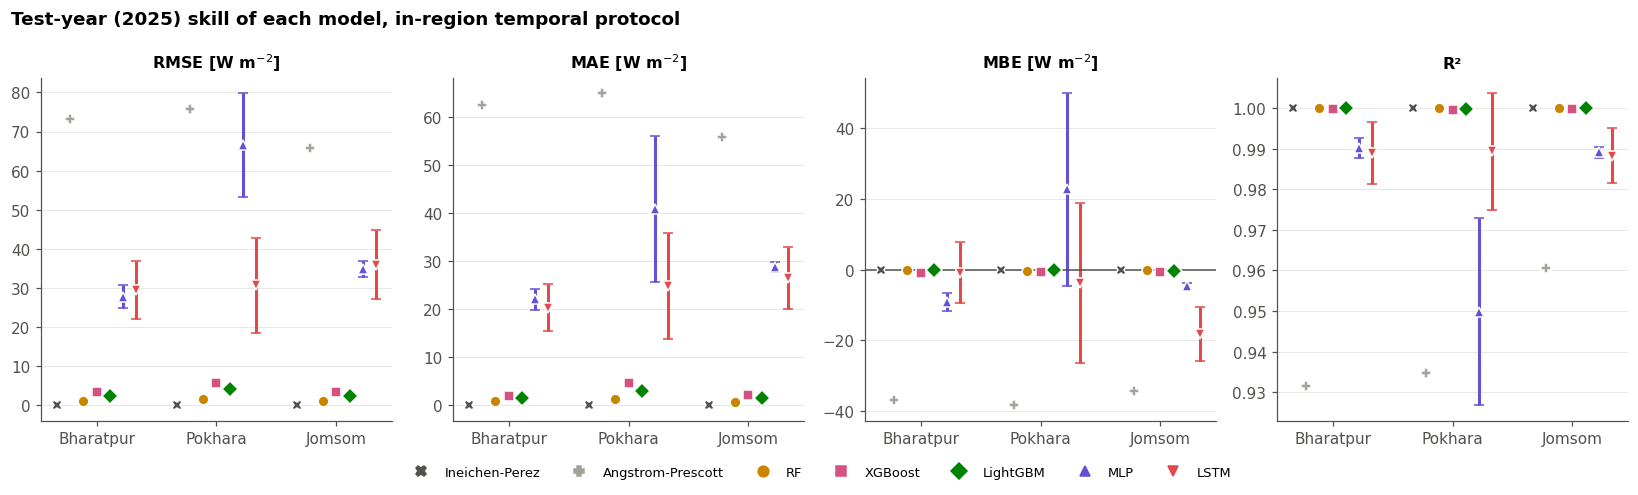

In [55]:
# Fig R1 – test-year (2025) metrics of every model at every site, temporal protocol; MLP/LSTM bars show ±1 sd across seeds
mt = M_main[M_main.protocol == 'temporal']
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, met, lab in zip(axes, ['RMSE', 'MAE', 'MBE', 'R2'], ['RMSE [W m$^{-2}$]', 'MAE [W m$^{-2}$]', 'MBE [W m$^{-2}$]', 'R²']):
    for i, s in enumerate(SITES):
        for j, m in enumerate(MODELS):
            v = mt[(mt.site == s) & (mt.model == m)][met]
            if v.empty: continue
            x = i + (j - (len(MODELS) - 1) / 2) * 0.11
            err = None
            if len(SEEDM) and m in ('MLP', 'LSTM'):
                sd = SEEDM[(SEEDM.protocol == 'temporal') & (SEEDM.fold == s) & (SEEDM.model == m)][met].std()
                err = sd if np.isfinite(sd) else None
            ax.errorbar(x, v.iloc[0], yerr=err, fmt=MM[m], color=MC[m], ms=7, mec='white', mew=1, capsize=3)
    ax.set_xticks(range(len(SITES)), SITES); ax.set_title(lab); ax.grid(axis='x', visible=False)
    if met == 'MBE': ax.axhline(0, color=INK2, lw=1)
h = [plt.Line2D([], [], color=MC[m], marker=MM[m], ls='', ms=7, label=m) for m in MODELS]
fig.legend(handles=h, ncol=len(MODELS), loc='lower center', bbox_to_anchor=(0.5, -0.06))
suptitle(fig, 'Fig R1. Test-year (2025) skill of each model, in-region temporal protocol'); fig.tight_layout(); save(fig, 'R01_model_metrics')

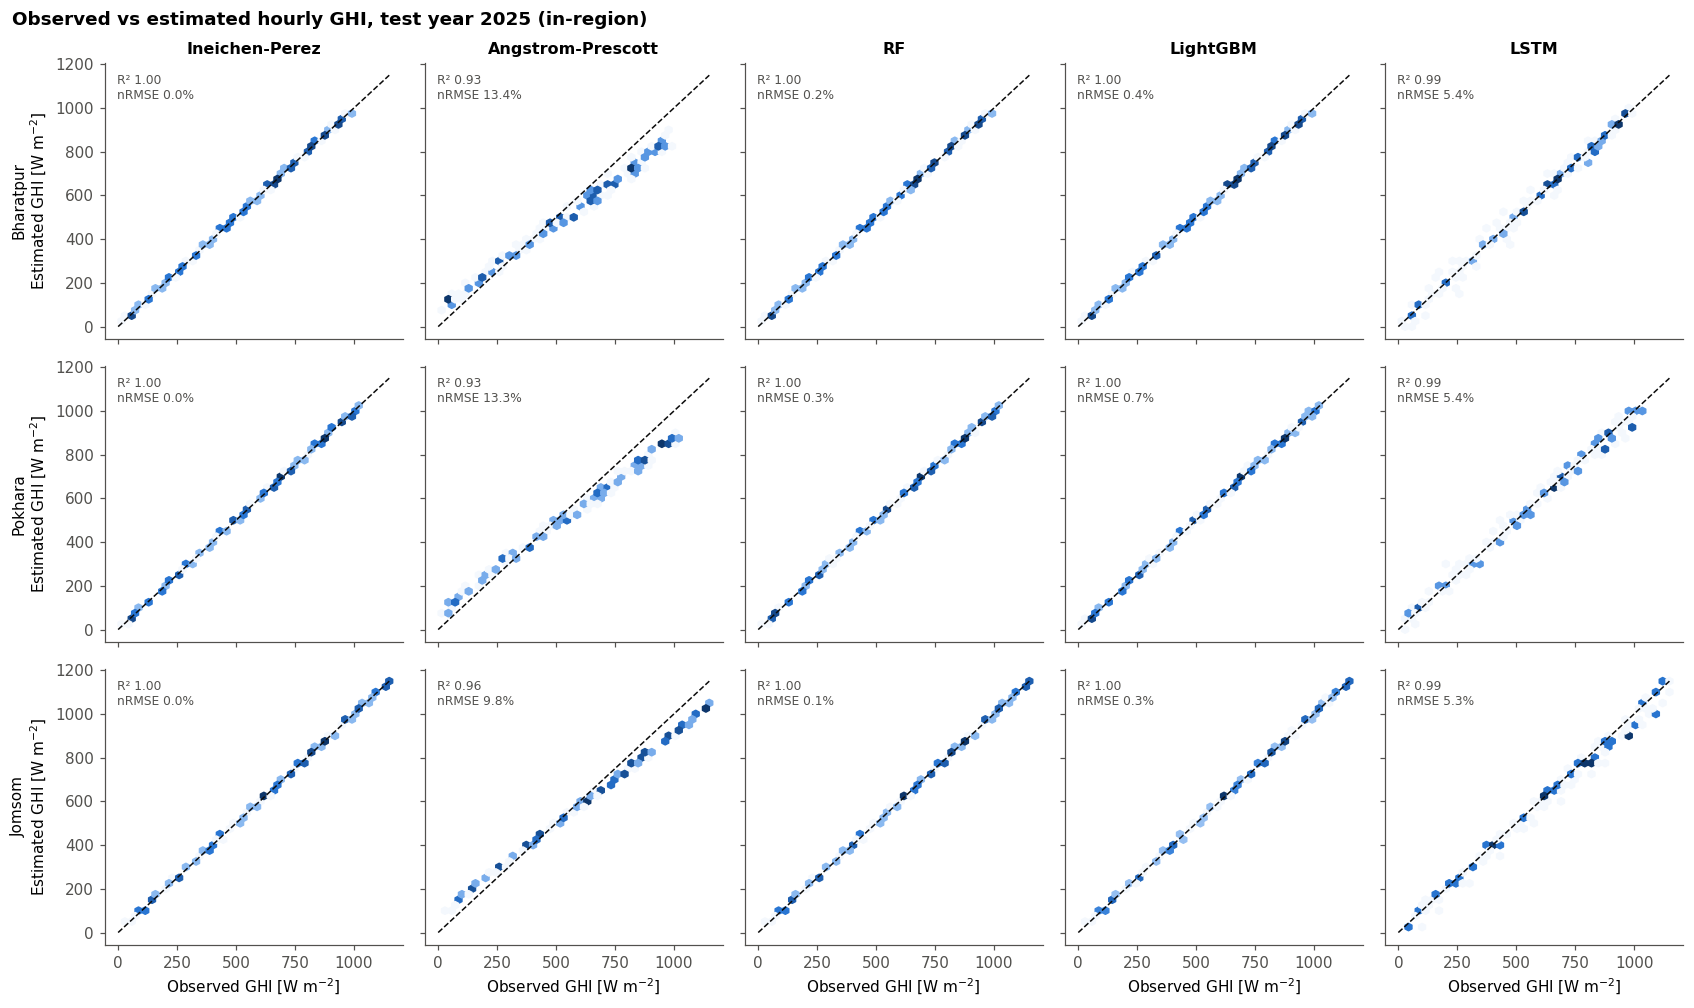

In [56]:
# Fig R2 – observed vs estimated (test year): baselines + three tree models + best NN, per site
show = [m for m in ['Ineichen-Perez', 'Angstrom-Prescott', 'RF', 'LightGBM', 'LSTM' if RUN_DL else 'XGBoost'] if m in MODELS]
fig, axes = plt.subplots(len(SITES), len(show), figsize=(3.1 * len(show), 3.1 * len(SITES)), sharex=True, sharey=True)
for i, s in enumerate(SITES):
    for j, m in enumerate(show):
        ax = axes[i, j]; d = TEST[(TEST.protocol == 'temporal') & (TEST.site == s) & (TEST.model == m)]
        ax.hexbin(d.obs, d.pred, gridsize=40, extent=(0, 1150, 0, 1150), cmap=SEQ, mincnt=1, bins='log')
        ax.plot([0, 1150], [0, 1150], color=INK, lw=1, ls='--'); ax.grid(False)
        mm = metrics(d.obs, d.pred)
        ax.text(0.04, 0.96, f"R² {mm['R2']:.2f}\nnRMSE {mm['nRMSE']:.1f}%", transform=ax.transAxes, va='top', fontsize=8, color=INK2)
        if i == 0: ax.set_title(m)
        if j == 0: ax.set_ylabel(f'{s}\nEstimated GHI [W m$^{{-2}}$]')
        if i == len(SITES) - 1: ax.set_xlabel('Observed GHI [W m$^{-2}$]')
suptitle(fig, 'Fig R2. Observed vs estimated hourly GHI, test year 2025 (in-region)'); fig.tight_layout(); save(fig, 'R02_obs_vs_pred')

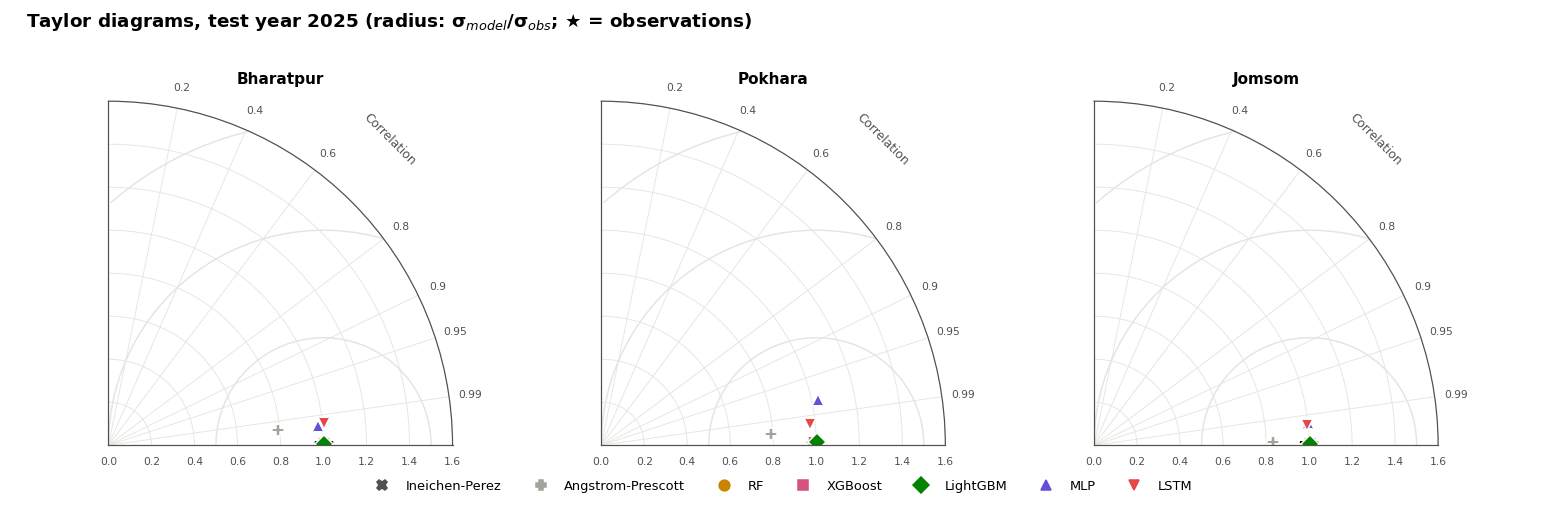

In [57]:
# Fig R3 – Taylor diagrams (correlation, normalised standard deviation, centred RMS difference)
def taylor(ax_rect, fig, df, title):
    ax = fig.add_axes(ax_rect, projection='polar'); ax.set_thetamin(0); ax.set_thetamax(90)
    sd_obs = df.obs.std()
    for rr in (0.5, 1.0, 1.5):                                         # centred-RMS arcs around the reference point
        th = np.linspace(0, np.pi/2, 200); x = 1 + rr*np.cos(np.linspace(0, np.pi, 200)); y = rr*np.sin(np.linspace(0, np.pi, 200))
        r, t = np.hypot(x, y), np.arctan2(y, x); k = t <= np.pi/2
        ax.plot(t[k], r[k], color=GRID, lw=1)
    ax.plot(0, 1, marker='*', color=INK, ms=12)
    for m in MODELS:
        d = df[df.model == m]
        if d.empty: continue
        c = np.corrcoef(d.obs, d.pred)[0, 1]; sdr = d.pred.std() / sd_obs
        ax.plot(np.arccos(np.clip(c, 0, 1)), sdr, marker=MM[m], color=MC[m], ms=8, mec='white', ls='')
    ticks = [0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 0.99]
    ax.set_thetagrids(np.degrees(np.arccos(ticks)), [str(t) for t in ticks], fontsize=7)
    ax.set_rlim(0, 1.6); ax.set_title(title, fontsize=10, pad=12); ax.tick_params(labelsize=7)
    ax.text(np.radians(45), 1.85, 'Correlation', ha='center', fontsize=8, color=INK2, rotation=-45)
fig = plt.figure(figsize=(14, 4.6))
for i, s in enumerate(SITES):
    taylor([0.04 + i*0.32, 0.12, 0.27, 0.68], fig, TEST[(TEST.protocol == 'temporal') & (TEST.site == s)], s)
lax = fig.add_axes([0, 0, 1, 0.08]); lax.axis('off'); model_legend(lax, MODELS, ncol=len(MODELS), loc='center')
suptitle(fig, 'Fig R3. Taylor diagrams, test year 2025 (radius: σ$_{model}$/σ$_{obs}$; ★ = observations)'); save(fig, 'R03_taylor')

⚠ Observed GHI is identical to clear-sky GHI — the target is a copy of GHI_cs, not a measurement.
  Attach real all-sky GHI (NASA POWER / CERES) and retrain before using this figure or any metric.


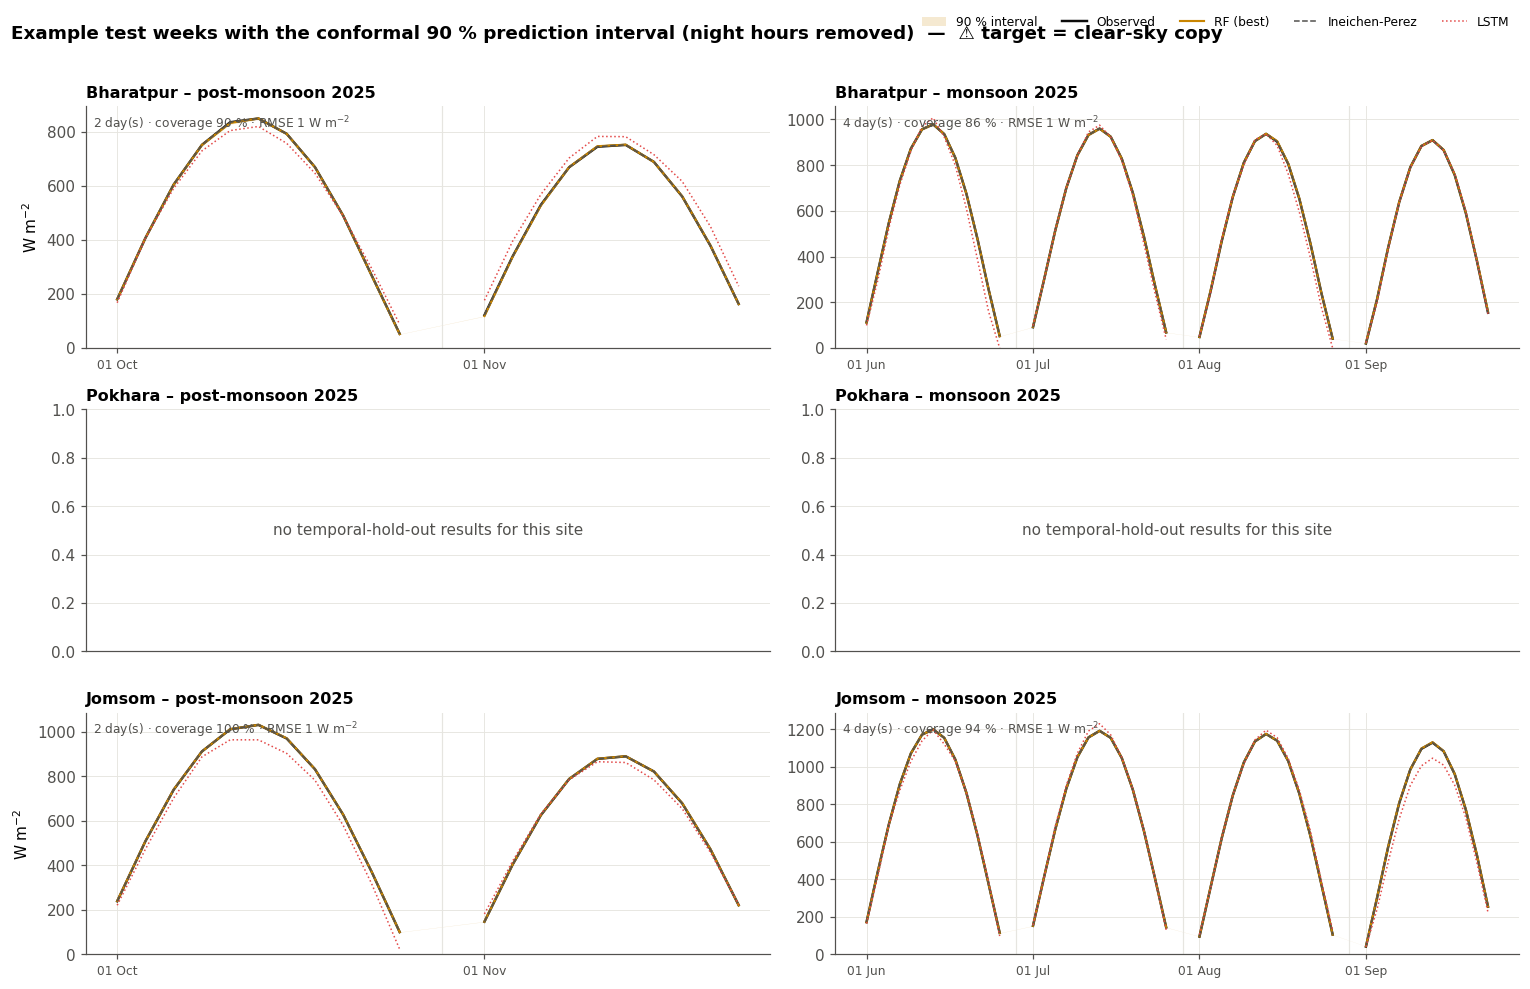

     site       season best  days      first  coverage_pct  rmse
Bharatpur Post-monsoon   RF     2 2025-10-01          90.5   1.2
Bharatpur      Monsoon   RF     4 2025-06-01          86.3   1.2
   Jomsom Post-monsoon   RF     2 2025-10-01         100.0   0.6
   Jomsom      Monsoon   RF     4 2025-06-01          94.1   0.9


In [59]:
# Fig R4 – example test weeks: observations, best model, LSTM and Ineichen–Perez, with the conformal 90 % interval
SEASON_WEEKS = [('Post-monsoon', [10, 11]), ('Monsoon', [6, 7, 8, 9])]
N_DAYS = 7
TEST = P[P.part == 'test']
ML_ONLY = [m for m in ML_MODELS if m in set(P.model)]

# ---- 0. Is the target real? (GHI identical to clear-sky GHI = fake target) ----
chk = TEST[(TEST.protocol == 'temporal') & TEST.GHI_cs.gt(0)]
FAKE_TARGET = len(chk) > 0 and (chk.obs - chk.GHI_cs).abs().mean() < 1.0
if FAKE_TARGET:
    print('⚠ Observed GHI is identical to clear-sky GHI — the target is a copy of GHI_cs, not a measurement.\n'
          '  Attach real all-sky GHI (NASA POWER / CERES) and retrain before using this figure or any metric.')

# ---- 1. Best model per site, chosen on the VALIDATION year ----
def best_model(site):
    v = P[(P.protocol == 'temporal') & (P.site == site) & (P.part == 'val') & P.model.isin(ML_ONLY)]
    return None if v.empty else v.groupby('model').apply(lambda g: np.sqrt(np.mean((g.pred - g.obs) ** 2))).idxmin()
BEST = {('temporal', s): b for s in SITES if (b := best_model(s))}

def conformal(protocol, site, model, alpha=ALPHA):
    sel = (P.protocol == protocol) & (P.site == site) & (P.model == model)
    v, t = P[sel & (P.part == 'val')], P[sel & (P.part == 'test')].copy()
    if len(v) < 20 or t.empty: return None
    sc = np.abs(v.obs - v.pred) / (v.GHI_cs + 50); n = len(sc)
    q = np.quantile(sc, min(1.0, np.ceil((n + 1) * (1 - alpha)) / n))
    t['lo'] = (t.pred - q * (t.GHI_cs + 50)).clip(0); t['hi'] = t.pred + q * (t.GHI_cs + 50)
    t['covered'] = (t.obs >= t.lo) & (t.obs <= t.hi)
    return t

# ---- 2. Pick the best-covered 7-day window in each season (falls back to the first available days) ----
def pick_days(ci, months):
    cnt = ci.groupby(ci.index.normalize()).size()
    cnt = cnt[cnt.index.month.isin(months)]
    if cnt.empty: return []
    win = {d: cnt[(cnt.index >= d) & (cnt.index < d + pd.Timedelta(days=N_DAYS))].index for d in cnt.index}
    best = max(win, key=lambda d: cnt[win[d]].sum())
    days = list(win[best])
    return days if len(days) >= 3 else list(cnt.index[:N_DAYS])           # sparse data: first N available days

def x_positions(idx):
    """Daytime hours side by side, a 2-h gap between days (nights removed)."""
    day = idx.normalize(); d_id = pd.factorize(day)[0]
    return np.arange(len(idx)) + 2 * d_id, day

# ---- 3. Figure ----
fig, axes = plt.subplots(len(SITES), 2, figsize=(14, 3 * len(SITES)), squeeze=False)
summary = []
for i, s in enumerate(SITES):
    bm = BEST.get(('temporal', s)); ci = conformal('temporal', s, bm) if bm else None
    for j, (lab, months) in enumerate(SEASON_WEEKS):
        ax = axes[i, j]; ax.set_title(f'{s} – {lab.lower()} {TEST_YEAR}', loc='left')
        if ci is None:
            ax.text(0.5, 0.5, 'no temporal-hold-out results for this site', ha='center', va='center', transform=ax.transAxes, color=INK2)
            ax.set_xticks([]); continue
        ci_s = ci.drop_duplicates('time_local').set_index('time_local').sort_index()
        days = pick_days(ci_s, months)
        if not days:
            ax.text(0.5, 0.5, f'no {lab.lower()} test data', ha='center', va='center', transform=ax.transAxes, color=INK2)
            ax.set_xticks([]); continue
        wf = ci_s[ci_s.index.normalize().isin(days)]
        x, dday = x_positions(wf.index)
        brk = np.r_[np.diff(x) > 1, False]                                    # break lines between days
        nanify = lambda v: np.where(np.r_[False, brk[:-1]], np.nan, v)
        def line(v, **kw):
            v = np.asarray(v, float).copy(); xs = x.astype(float).copy()
            ins = np.where(brk)[0] + 1
            ax.plot(np.insert(xs, ins, np.nan), np.insert(v, ins, np.nan), **kw)
        ax.fill_between(x, wf.lo, wf.hi, where=~np.r_[False, brk[:-1]] | True, color=MC[bm], alpha=0.18, lw=0, label='90 % interval')
        line(wf.obs, color=INK, lw=1.6, label='Observed')
        line(wf.pred, color=MC[bm], lw=1.4, label=f'{bm} (best)')
        for m in ['Ineichen-Perez'] + (['LSTM'] if RUN_DL and bm != 'LSTM' else []):
            o = TEST[(TEST.protocol == 'temporal') & (TEST.site == s) & (TEST.model == m)]
            if o.empty: continue
            o = o.drop_duplicates('time_local').set_index('time_local').pred.reindex(wf.index)
            line(o, color=MC[m], lw=1, ls='--' if m == 'Ineichen-Perez' else ':', label=m)
        starts = [x[dday == d][0] for d in pd.unique(dday)]
        ax.set_xticks(starts, [pd.Timestamp(d).strftime('%d %b') for d in pd.unique(dday)], fontsize=8)
        for st in starts[1:]: ax.axvline(st - 1.5, color=GRID, lw=0.8)
        cov = 100 * wf.covered.mean()
        rmse = np.sqrt(np.mean((wf.pred - wf.obs) ** 2))
        ax.text(0.01, 0.97, f'{len(days)} day(s) · coverage {cov:.0f} % · RMSE {rmse:.0f} W m$^{{-2}}$',
                transform=ax.transAxes, va='top', fontsize=8, color=INK2)
        ax.set_ylabel('W m$^{-2}$' if j == 0 else ''); ax.set_ylim(0, None)
        summary.append(dict(site=s, season=lab, best=bm, days=len(days), first=min(days).date(), coverage_pct=round(cov, 1), rmse=round(rmse, 1)))

handles, labels = [], []
for a in axes.ravel():
    for h, l in zip(*a.get_legend_handles_labels()):
        if l not in labels: handles.append(h); labels.append(l)
if handles: fig.legend(handles, labels, ncol=5, fontsize=8, loc='upper right', bbox_to_anchor=(0.99, 1.0), frameon=False)
title = 'Fig R4. Example test weeks with the conformal 90 % prediction interval (night hours removed)'
if FAKE_TARGET: title += '  —  ⚠ target = clear-sky copy'
suptitle(fig, title); fig.tight_layout(rect=(0, 0, 1, 0.97)); save(fig, 'R04_example_weeks')
print(pd.DataFrame(summary).to_string(index=False))

## F. RO3 / RQ1 — Temporal and spatial generalization

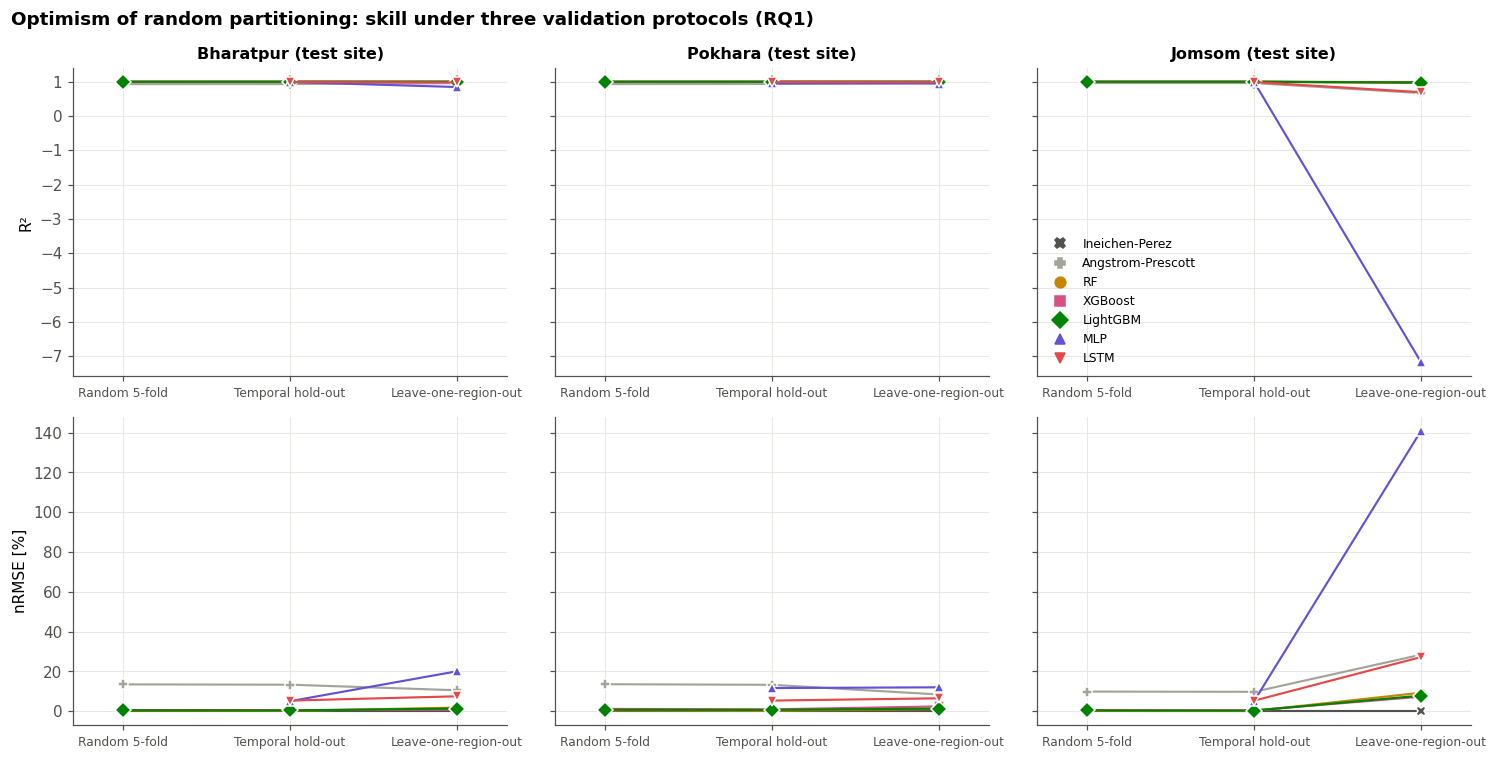

In [60]:
# Fig R5 – optimism of random partitioning: k-fold vs temporal vs LORO (same site)
protos = [('kfold', 'Random 5-fold'), ('temporal', 'Temporal hold-out'), ('loro', 'Leave-one-region-out')]
fig, axes = plt.subplots(2, len(SITES), figsize=(4.6 * len(SITES), 7), sharey='row')
for i, (met, lab) in enumerate([('R2', 'R²'), ('nRMSE', 'nRMSE [%]')]):
    for j, s in enumerate(SITES):
        ax = axes[i, j]
        for m in MODELS:
            ys = [M_all[(M_all.protocol == p) & (M_all.site == s) & (M_all.model == m)][met] for p, _ in protos]
            ys = [y.iloc[0] if len(y) else np.nan for y in ys]
            ax.plot(range(3), ys, color=MC[m], marker=MM[m], ms=7, mec='white', lw=1.4)
        ax.set_xticks(range(3), [l for _, l in protos], fontsize=8); ax.set_xlim(-0.3, 2.3)
        if i == 0: ax.set_title(f'{s} (test site)')
        if j == 0: ax.set_ylabel(lab)
model_legend(axes[0, -1], MODELS, loc='lower left', fontsize=8)
suptitle(fig, 'Fig R5. Optimism of random partitioning: skill under three validation protocols (RQ1)')
fig.tight_layout(); save(fig, 'R05_protocol_optimism')

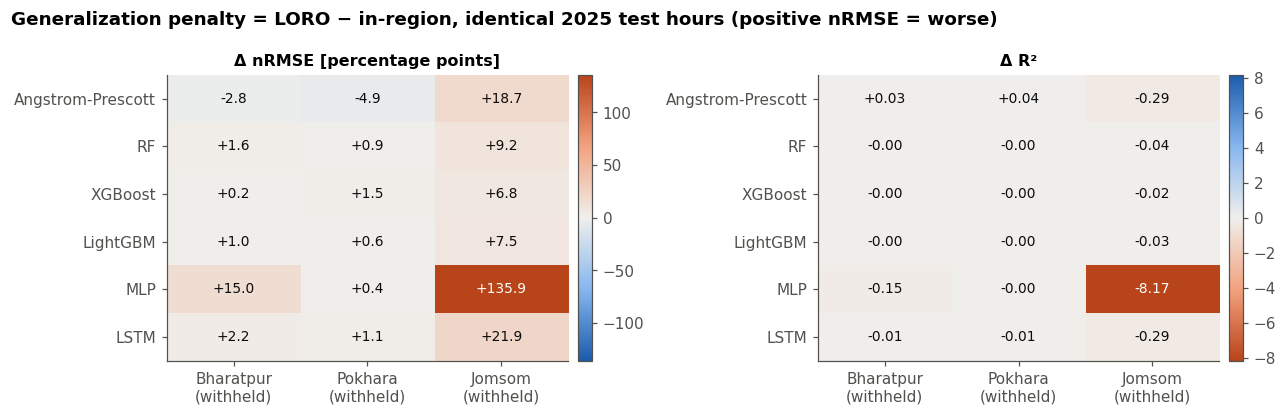

In [61]:
# Fig R6 – generalization penalty (LORO − temporal, same 2025 test hours) as a model × site heat map
pen = M_main.pivot_table(index=['model', 'site'], columns='protocol', values=['nRMSE', 'R2'])
penalty = pd.DataFrame({'d_nRMSE': pen[('nRMSE', 'loro')] - pen[('nRMSE', 'temporal')],
                        'd_R2': pen[('R2', 'loro')] - pen[('R2', 'temporal')]}).reset_index()
penalty.round(3).to_csv(RES_DIR / 'generalization_penalty.csv', index=False)
ml_pen = penalty[penalty.model.isin(ML_MODELS + ['Angstrom-Prescott'])]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, lab in zip(axes, ['d_nRMSE', 'd_R2'], ['Δ nRMSE [percentage points]', 'Δ R²']):
    h = ml_pen.pivot(index='model', columns='site', values=col).reindex(index=[m for m in MODELS if m in ml_pen.model.values], columns=SITES)
    lim = np.nanmax(np.abs(h.values))
    im = ax.imshow(h.values, cmap=DIV if col == 'd_nRMSE' else DIV.reversed(), vmin=-lim, vmax=lim, aspect='auto')
    for (a, b), v in np.ndenumerate(h.values):
        ax.text(b, a, f'{v:+.2f}' if col == 'd_R2' else f'{v:+.1f}', ha='center', va='center', fontsize=9,
                color='white' if abs(v) > 0.6 * lim else INK)
    ax.set_xticks(range(len(SITES)), [f'{s}\n(withheld)' for s in SITES]); ax.set_yticks(range(len(h)), h.index)
    ax.grid(False); ax.set_title(lab); fig.colorbar(im, ax=ax, pad=0.02)
suptitle(fig, 'Fig R6. Generalization penalty = LORO − in-region, identical 2025 test hours (positive nRMSE = worse)')
fig.tight_layout(); save(fig, 'R06_generalization_penalty')

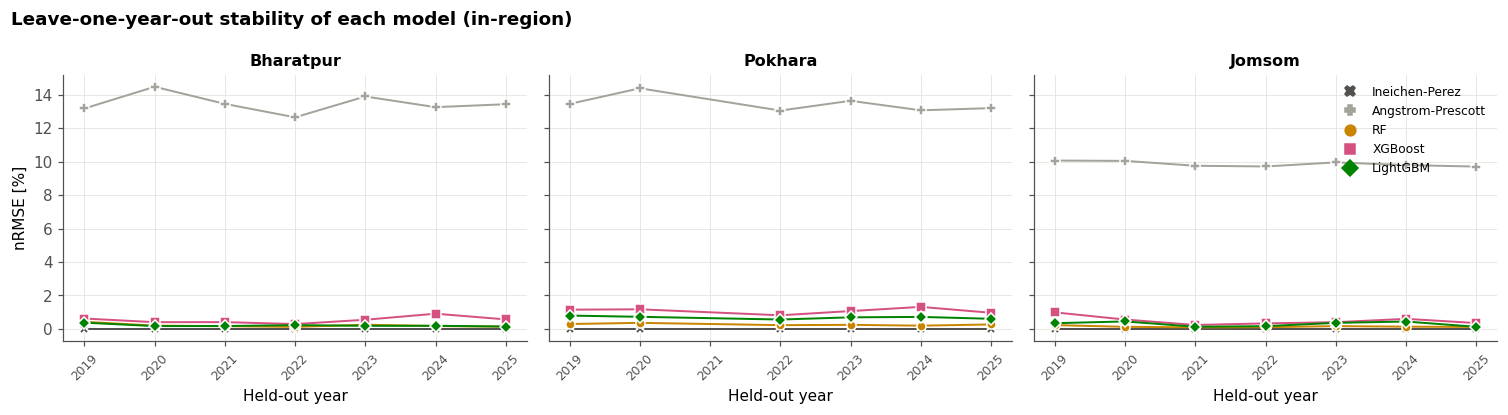

In [62]:
# Fig R7 – interannual stability: leave-one-year-out nRMSE per held-out year
fig, axes = plt.subplots(1, len(SITES), figsize=(4.6 * len(SITES), 3.8), sharey=True)
for ax, s in zip(axes, SITES):
    for m in [m for m in MODELS if m in M_loyo.model.unique()]:
        d = M_loyo[(M_loyo.site == s) & (M_loyo.model == m)].sort_values('year')
        ax.plot(d.year, d.nRMSE, color=MC[m], marker=MM[m], ms=6, mec='white', lw=1.3)
    ax.set_title(s); ax.set_xlabel('Held-out year'); ax.set_xticks(sorted(M_loyo.year.unique()))
    ax.tick_params(axis='x', labelsize=8, rotation=45)
axes[0].set_ylabel('nRMSE [%]'); model_legend(axes[-1], [m for m in MODELS if m in M_loyo.model.unique()], loc='upper right', fontsize=8)
suptitle(fig, 'Fig R7. Leave-one-year-out stability of each model (in-region)'); fig.tight_layout(); save(fig, 'R07_loyo')

### H1 — Generalization hypothesis test

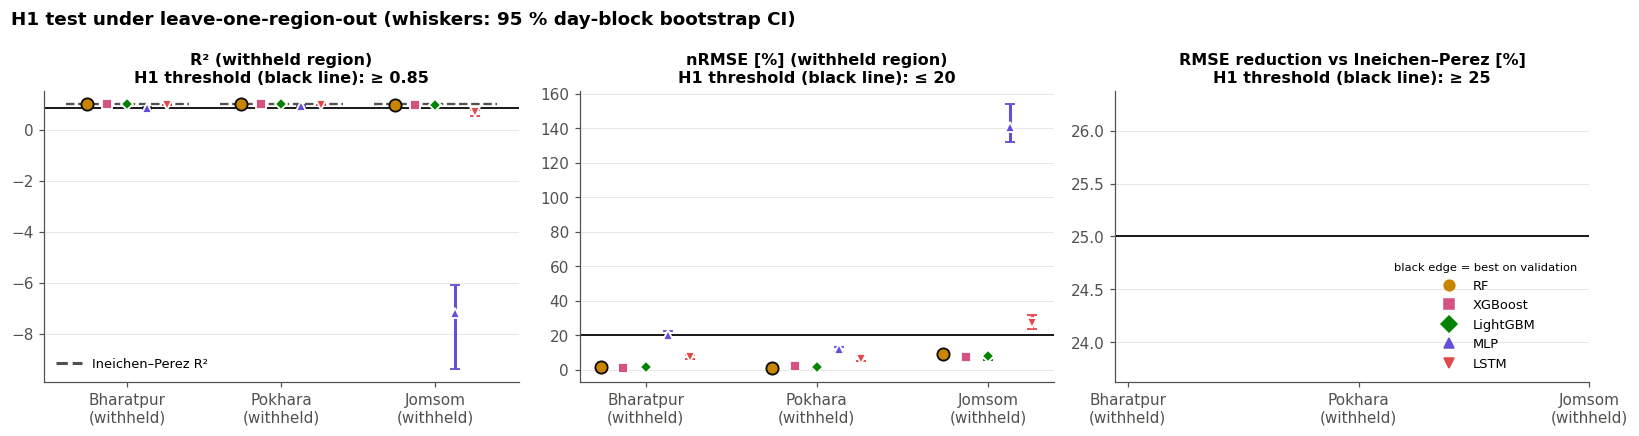

,site,model,best,R2,nRMSE,dR2,RMSE_reduction_pct,H1_supported
0,Bharatpur,RF,True,0.999,1.834,-0.001,-inf,False
1,Bharatpur,XGBoost,False,1.000,0.809,-0.000,-inf,False
2,Bharatpur,LightGBM,False,0.999,1.384,-0.001,-inf,False
3,Bharatpur,MLP,False,0.845,20.108,-0.155,-inf,False
4,Bharatpur,LSTM,False,0.978,7.525,-0.022,-inf,False
5,Pokhara,RF,True,1.000,1.140,-0.000,-inf,False
6,Pokhara,XGBoost,False,0.998,2.443,-0.002,-inf,False
7,Pokhara,LightGBM,False,0.999,1.351,-0.001,-inf,False
8,Pokhara,MLP,False,0.947,12.039,-0.053,-inf,False
9,Pokhara,LSTM,False,0.984,6.519,-0.016,-inf,False


In [64]:
rows = []
for s in SITES:
    base = TEST[(TEST.protocol == 'loro') & (TEST.site == s) & (TEST.model == 'Ineichen-Perez')]
    mb = metrics(base.obs, base.pred)
    for m in ML_MODELS:
        d = TEST[(TEST.protocol == 'loro') & (TEST.site == s) & (TEST.model == m)]
        if d.empty: continue
        mm = metrics(d.obs, d.pred)
        r2_ci = boot_ci(d, lambda g: metrics(g.obs, g.pred)['R2'])
        nr_ci = boot_ci(d, lambda g: metrics(g.obs, g.pred)['nRMSE'])
        # Safe-guard lookup in BEST dictionary using .get()
        loro_best = BEST.get(('loro', s), BEST.get(('temporal', s), 'RF'))
        rows.append(dict(site=s, model=m, best=(loro_best == m), R2=mm['R2'], R2_lo=r2_ci[0], R2_hi=r2_ci[1],
                         nRMSE=mm['nRMSE'], nRMSE_lo=nr_ci[0], nRMSE_hi=nr_ci[1], R2_IP=mb['R2'], dR2=mm['R2'] - mb['R2'],
                         RMSE_reduction_pct=100 * (mb['RMSE'] - mm['RMSE']) / mb['RMSE'],
                         c1_R2_ge_085=mm['R2'] >= 0.85, c2_nRMSE_le_20=mm['nRMSE'] <= 20,
                         c3_dR2_ge_020=(mm['R2'] - mb['R2']) >= 0.20, c4_RMSE_red_ge_25=100*(mb['RMSE'] - mm['RMSE'])/mb['RMSE'] >= 25))
H1 = pd.DataFrame(rows); H1['H1_supported'] = H1[['c1_R2_ge_085', 'c2_nRMSE_le_20', 'c3_dR2_ge_020', 'c4_RMSE_red_ge_25']].all(axis=1)
H1['LORO_valid'] = ~H1.site.isin(SHARED)   # False → target shared with a training region (see Fig R0b)
H1.round(3).to_csv(RES_DIR / 'H1_test.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, lo, hi, thr, lab, better) in zip(axes, [('R2', 'R2_lo', 'R2_hi', 0.85, 'R² (withheld region)', 'above'),
                                                      ('nRMSE', 'nRMSE_lo', 'nRMSE_hi', 20, 'nRMSE [%] (withheld region)', 'below'),
                                                      ('RMSE_reduction_pct', None, None, 25, 'RMSE reduction vs Ineichen–Perez [%]', 'above')]):
    for i, s in enumerate(SITES):
        for j, m in enumerate(ML_MODELS):
            r = H1[(H1.site == s) & (H1.model == m)]
            if r.empty: continue
            x = i + (j - (len(ML_MODELS) - 1) / 2) * 0.13; v = r[col].iloc[0]
            yerr = [[v - r[lo].iloc[0]], [r[hi].iloc[0] - v]] if lo else None
            ax.errorbar(x, v, yerr=yerr, fmt=MM[m], color=MC[m], ms=8 if r.best.iloc[0] else 6,
                        mec=INK if r.best.iloc[0] else 'white', mew=1.2, capsize=3)
        if col == 'R2':
            ax.plot([i - 0.4, i + 0.4], [H1[H1.site == s].R2_IP.iloc[0]] * 2, color=MC['Ineichen-Perez'], lw=1.5, ls='--')
    ax.axhline(thr, color=INK, lw=1.2)
    ax.set_xticks(range(len(SITES)), [f'{s}\n(withheld)' for s in SITES]); ax.grid(axis='x', visible=False)
    ax.set_title(f"{lab}\nH1 threshold (black line): {'≥' if better == 'above' else '≤'} {thr}")
axes[0].plot([], [], color=MC['Ineichen-Perez'], ls='--', label='Ineichen–Perez R²'); axes[0].legend(loc='lower left')
model_legend(axes[2], ML_MODELS, loc='lower right', title='black edge = best on validation', title_fontsize=7.5)
suptitle(fig, 'Fig R8. H1 test under leave-one-region-out (whiskers: 95 % day-block bootstrap CI)'); fig.tight_layout(); save(fig, 'R08_H1_test')
H1[['site', 'model', 'best', 'R2', 'nRMSE', 'dR2', 'RMSE_reduction_pct', 'H1_supported']].round(3)

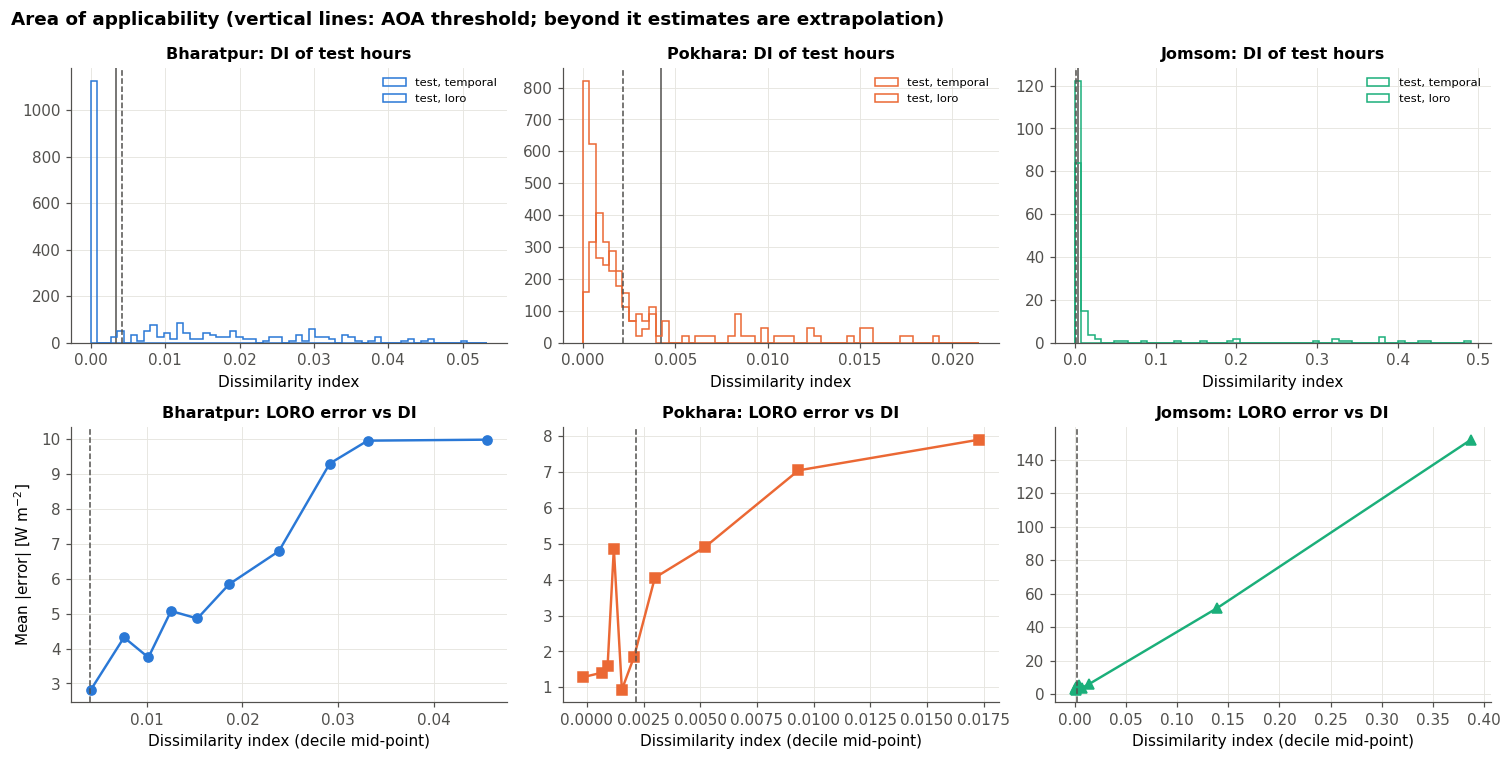

,protocol,site,pct_inside,threshold,nRMSE_inside,nRMSE_outside
0,temporal,Bharatpur,100.00,0.0,0.41,NaN
1,loro,Bharatpur,5.19,0.0,NaN,1.42
2,temporal,Pokhara,100.00,0.0,0.70,NaN
3,loro,Pokhara,58.73,0.0,0.84,2.05
4,temporal,Jomsom,100.00,0.0,0.35,NaN
5,loro,Jomsom,43.70,0.0,1.01,9.60


In [65]:
# Fig R9 – area of applicability (Meyer & Pebesma 2021): weighted dissimilarity index of each test hour to the training data
def aoa(protocol, s, max_train=20000, seed=SEED):
    mdl, feats = LGB_STORE[(protocol, s)]
    booster = mdl.booster_ if hasattr(mdl, 'booster_') else mdl
    w = booster.feature_importance('gain'); w = w / w.sum()
    tr = D[(D.site == s) if protocol == 'temporal' else (D.site != s)]; tr = tr[tr.year.isin(TRAIN_YEARS)]
    te = D[(D.site == s) & (D.year == TEST_YEAR)]
    mu, sd = tr[feats].mean(), tr[feats].std() + 1e-9
    Z = lambda d: ((d[feats] - mu) / sd).values * w
    rng = np.random.default_rng(seed); trs = tr.iloc[rng.choice(len(tr), min(max_train, len(tr)), replace=False)]
    Ztr = Z(trs); samp = Ztr[rng.choice(len(Ztr), min(2000, len(Ztr)), replace=False)]
    dbar = np.mean(np.linalg.norm(samp[:, None] - samp[None], axis=2)[np.triu_indices(len(samp), 1)])
    di_tr = np.empty(len(trs))                                         # training DI: nearest point in another year (block CV)
    for y in trs.year.unique():
        a, b = (trs.year == y).values, (trs.year != y).values
        di_tr[a] = NearestNeighbors(n_neighbors=1).fit(Ztr[b]).kneighbors(Ztr[a])[0][:, 0] / dbar
    thr = np.percentile(di_tr, 75) + 1.5 * (np.percentile(di_tr, 75) - np.percentile(di_tr, 25))
    di_te = NearestNeighbors(n_neighbors=1).fit(Ztr).kneighbors(Z(te))[0][:, 0] / dbar
    return pd.Series(di_te, index=te.index), di_tr, thr
AOA = {}
for proto in ('temporal', 'loro'):
    for s in SITES:
        if (proto, s) in LGB_STORE: AOA[(proto, s)] = aoa(proto, s)
fig, axes = plt.subplots(2, len(SITES), figsize=(4.6 * len(SITES), 7))
aoa_rows = []
for j, s in enumerate(SITES):
    ax = axes[0, j]
    hi_x = max(np.percentile(np.r_[AOA[('temporal', s)][0], AOA[('loro', s)][0]], 99.5), 1.5 * AOA[('loro', s)][2])
    bins = np.linspace(0, hi_x, 61)
    for proto, ls in (('temporal', '-'), ('loro', '--')):
        di, di_tr, thr = AOA[(proto, s)]
        ax.hist(di, bins=bins, density=True, histtype='step', lw=1.8, ls=ls, color=SITE_C[s], label=f'test, {proto}')
        ax.axvline(thr, color=INK2, lw=1, ls=ls)
        d = TEST[(TEST.protocol == proto) & (TEST.site == s) & (TEST.model == 'LightGBM')].set_index('row')
        inside = di.reindex(d.index) <= thr
        aoa_rows.append(dict(protocol=proto, site=s, pct_inside=100 * inside.mean(), threshold=thr,
                             nRMSE_inside=metrics(d.obs[inside], d.pred[inside])['nRMSE'] if inside.sum() > 30 else np.nan,
                             nRMSE_outside=metrics(d.obs[~inside], d.pred[~inside])['nRMSE'] if (~inside).sum() > 30 else np.nan))
        if proto == 'loro':
            ax2 = axes[1, j]; err = (d.pred - d.obs).abs(); dib = pd.qcut(di.reindex(d.index), 10, duplicates='drop')
            g = err.groupby(dib, observed=True).mean(); xs = [iv.mid for iv in g.index]
            ax2.plot(xs, g.values, color=SITE_C[s], marker=SITE_M[s], lw=1.6)
            ax2.axvline(thr, color=INK2, lw=1, ls='--'); ax2.set_xlabel('Dissimilarity index (decile mid-point)')
            ax2.set_title(f'{s}: LORO error vs DI'); ax2.set_ylabel('Mean |error| [W m$^{-2}$]' if j == 0 else '')
    ax.set_title(f'{s}: DI of test hours'); ax.set_xlabel('Dissimilarity index'); ax.legend(fontsize=7.5)
AOA_T = pd.DataFrame(aoa_rows); AOA_T.round(3).to_csv(RES_DIR / 'area_of_applicability.csv', index=False)
suptitle(fig, 'Fig R9. Area of applicability (vertical lines: AOA threshold; beyond it estimates are extrapolation)')
fig.tight_layout(); save(fig, 'R09_area_of_applicability'); AOA_T.round(2)

## G. RO4 — Feature ablation, radiometric leakage, data-limited conditions and explanation

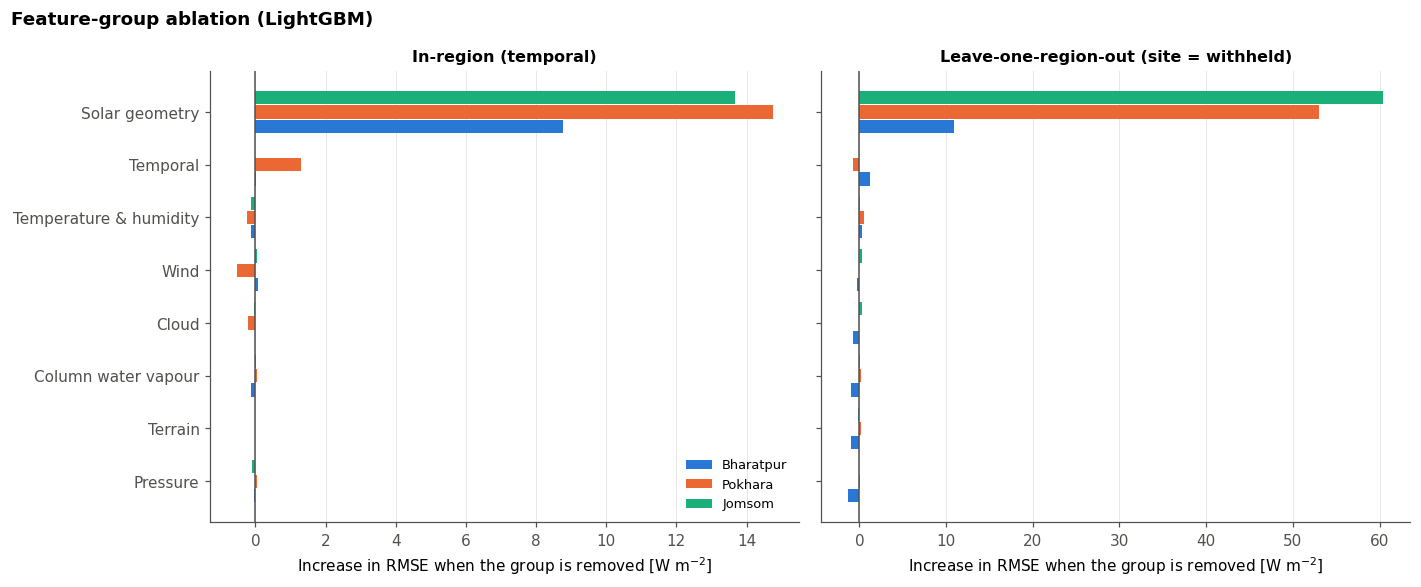

In [66]:
# Fig R10 – group ablation with LightGBM (fixed tuned parameters): ΔRMSE when each predictor group is removed
abl = []
for proto in ('temporal', 'loro'):
    for s in SITES:
        p = PARAMS[(proto, s)]['LightGBM']
        tr = D[(D.site == s) if proto == 'temporal' else (D.site != s)]; tr = tr[tr.year.isin(TRAIN_YEARS)]
        te = D[(D.site == s) & (D.year == TEST_YEAR)]
        full = metrics(te.GHI, lgb.LGBMRegressor(**p).fit(tr[FEATURES], tr.GHI).predict(te[FEATURES]))
        for g, cols in GROUPS.items():
            f = [c for c in FEATURES if c not in cols]
            mm = metrics(te.GHI, lgb.LGBMRegressor(**p).fit(tr[f], tr.GHI).predict(te[f]))
            abl.append(dict(protocol=proto, site=s, group=g, dRMSE=mm['RMSE'] - full['RMSE'], dR2=mm['R2'] - full['R2']))
ABL = pd.DataFrame(abl); ABL.round(3).to_csv(RES_DIR / 'ablation.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 0.45 * len(GROUPS) + 1.8), sharey=True)
order = ABL.groupby('group').dRMSE.mean().sort_values().index
for ax, proto in zip(axes, ('temporal', 'loro')):
    for k, s in enumerate(SITES):
        d = ABL[(ABL.protocol == proto) & (ABL.site == s)].set_index('group').reindex(order)
        ax.barh(np.arange(len(order)) + (k - 1) * 0.27, d.dRMSE, height=0.25, color=SITE_C[s], label=s)
    ax.axvline(0, color=INK2, lw=1); ax.set_yticks(range(len(order)), order); ax.grid(axis='y', visible=False)
    ax.set_xlabel('Increase in RMSE when the group is removed [W m$^{-2}$]')
    ax.set_title('In-region (temporal)' if proto == 'temporal' else 'Leave-one-region-out (site = withheld)')
axes[0].legend(loc='lower right')
suptitle(fig, 'Fig R10. Feature-group ablation (LightGBM)'); fig.tight_layout(); save(fig, 'R10_ablation')

In [67]:
# Fig R11 – radiometric-leakage matched design: identical models with vs without radiometric predictors
if RADIOMETRIC:
    leak = []
    for proto in ('temporal', 'loro'):
        for s in SITES:
            p = PARAMS[(proto, s)]['LightGBM']
            tr = D[(D.site == s) if proto == 'temporal' else (D.site != s)]; tr = tr[tr.year.isin(TRAIN_YEARS)]
            te = D[(D.site == s) & (D.year == TEST_YEAR)]
            for cond, f in (('Meteorological only', FEATURES), ('+ radiometric', FEATURES + RADIOMETRIC)):
                mm = metrics(te.GHI, lgb.LGBMRegressor(**p).fit(tr[f], tr.GHI).predict(te[f]))
                leak.append(dict(protocol=proto, site=s, condition=cond, **mm))
    LEAK = pd.DataFrame(leak); LEAK.round(3).to_csv(RES_DIR / 'radiometric_leakage.csv', index=False)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for ax, met in zip(axes, ['R2', 'nRMSE']):
        for i, proto in enumerate(('temporal', 'loro')):
            for k, s in enumerate(SITES):
                d = LEAK[(LEAK.protocol == proto) & (LEAK.site == s)].set_index('condition')
                x = i * 4 + k
                ax.plot([x, x], d[met].values, color=SITE_C[s], lw=2)
                ax.plot(x, d.loc['Meteorological only', met], 'o', color=SITE_C[s], ms=8, mfc='white', mew=2)
                ax.plot(x, d.loc['+ radiometric', met], 'o', color=SITE_C[s], ms=8)
        ax.set_xticks([1, 5], ['In-region', 'LORO']); ax.set_title('R²' if met == 'R2' else 'nRMSE [%]'); ax.grid(axis='x', visible=False)
    h = [plt.Line2D([], [], marker='o', ls='', color=INK2, mfc='white', mew=2, label='Meteorological only'),
         plt.Line2D([], [], marker='o', ls='', color=INK2, label='+ radiometric: ' + ', '.join(RADIOMETRIC))]
    h += [plt.Line2D([], [], color=SITE_C[s], lw=2, label=s) for s in SITES]
    axes[1].legend(handles=h, fontsize=7.5, loc='upper left', bbox_to_anchor=(1.02, 1))
    suptitle(fig, 'Fig R11. Radiometric predictor leakage: matched design, LightGBM, test year 2025'); fig.tight_layout(); save(fig, 'R11_leakage')
else:
    print('No radiometric predictors in the dataset → leakage experiment skipped. Add e.g. MERRA-2 SWGDNCLR/SWTDN or NASA POWER clear-sky/UV/PAR columns to run it.')

No radiometric predictors in the dataset → leakage experiment skipped. Add e.g. MERRA-2 SWGDNCLR/SWTDN or NASA POWER clear-sky/UV/PAR columns to run it.


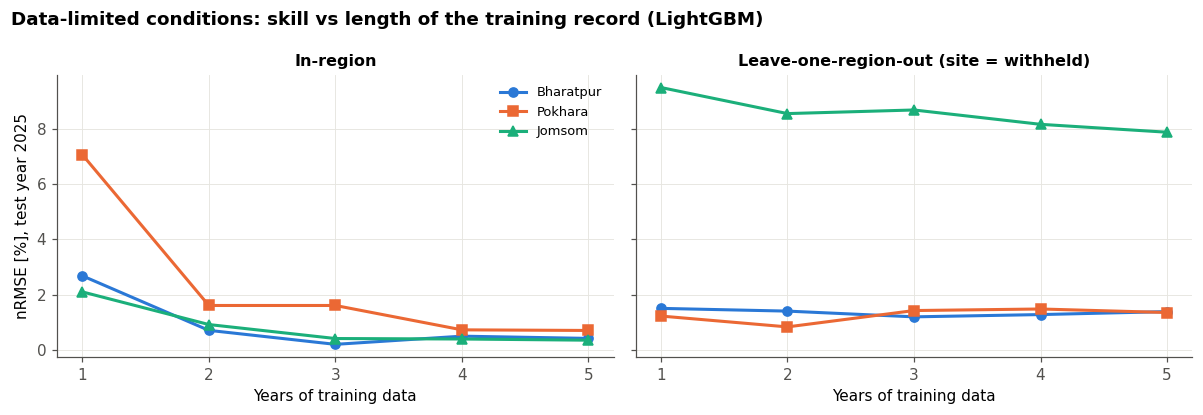

In [68]:
# Fig R12 – data-limited conditions: skill vs number of training years (LightGBM, last k years of 2019–2023)
lc = []
for proto in ('temporal', 'loro'):
    for s in SITES:
        p = PARAMS[(proto, s)]['LightGBM']; te = D[(D.site == s) & (D.year == TEST_YEAR)]
        base = D[(D.site == s) if proto == 'temporal' else (D.site != s)]
        for k in (1, 2, 3, 4, 5):
            tr = base[base.year.isin(TRAIN_YEARS[-k:])]
            lc.append(dict(protocol=proto, site=s, years=k, **metrics(te.GHI, lgb.LGBMRegressor(**p).fit(tr[FEATURES], tr.GHI).predict(te[FEATURES]))))
LC = pd.DataFrame(lc); LC.round(3).to_csv(RES_DIR / 'learning_curve.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, proto in zip(axes, ('temporal', 'loro')):
    for s in SITES:
        d = LC[(LC.protocol == proto) & (LC.site == s)]
        ax.plot(d.years, d.nRMSE, color=SITE_C[s], marker=SITE_M[s], label=s)
    ax.set_xticks([1, 2, 3, 4, 5]); ax.set_xlabel('Years of training data')
    ax.set_title('In-region' if proto == 'temporal' else 'Leave-one-region-out (site = withheld)')
axes[0].set_ylabel('nRMSE [%], test year 2025'); axes[0].legend()
suptitle(fig, 'Fig R12. Data-limited conditions: skill vs length of the training record (LightGBM)'); fig.tight_layout(); save(fig, 'R12_learning_curve')

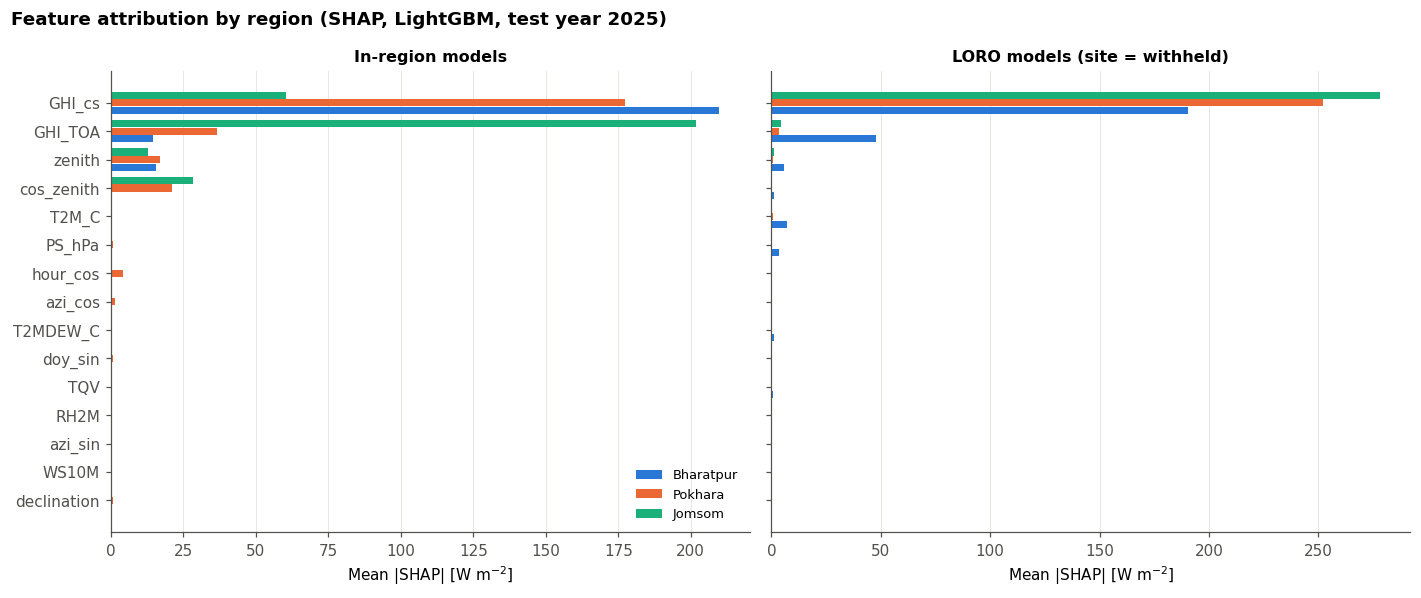

In [69]:
# SHAP values (LightGBM) on the 2025 test hours, per region and protocol
def shap_frame(proto, s, n=4000, seed=SEED):
    mdl, feats = LGB_STORE[(proto, s)]
    te = D[(D.site == s) & (D.year == TEST_YEAR)]
    te = te.sample(min(n, len(te)), random_state=seed)
    sv = shap.TreeExplainer(mdl.booster_ if hasattr(mdl, 'booster_') else mdl).shap_values(te[feats])
    return te, pd.DataFrame(sv, columns=feats, index=te.index)
SH = {(p, s): shap_frame(p, s) for p in ('temporal', 'loro') for s in SITES if (p, s) in LGB_STORE}

# Fig R13 – global importance (mean |SHAP|) per region, in-region vs LORO
imp = pd.DataFrame({f'{p}|{s}': v[1].abs().mean() for (p, s), v in SH.items()})
top = imp.mean(axis=1).sort_values(ascending=False).index[:15][::-1]
imp.loc[top].round(2).to_csv(RES_DIR / 'shap_global_importance.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, p in zip(axes, ('temporal', 'loro')):
    for k, s in enumerate(SITES):
        ax.barh(np.arange(len(top)) + (k - 1) * 0.27, imp.loc[top, f'{p}|{s}'], height=0.25, color=SITE_C[s], label=s)
    ax.set_yticks(range(len(top)), top); ax.grid(axis='y', visible=False); ax.set_xlabel('Mean |SHAP| [W m$^{-2}$]')
    ax.set_title('In-region models' if p == 'temporal' else 'LORO models (site = withheld)')
axes[0].legend(loc='lower right')
suptitle(fig, 'Fig R13. Feature attribution by region (SHAP, LightGBM, test year 2025)'); fig.tight_layout(); save(fig, 'R13_shap_global')

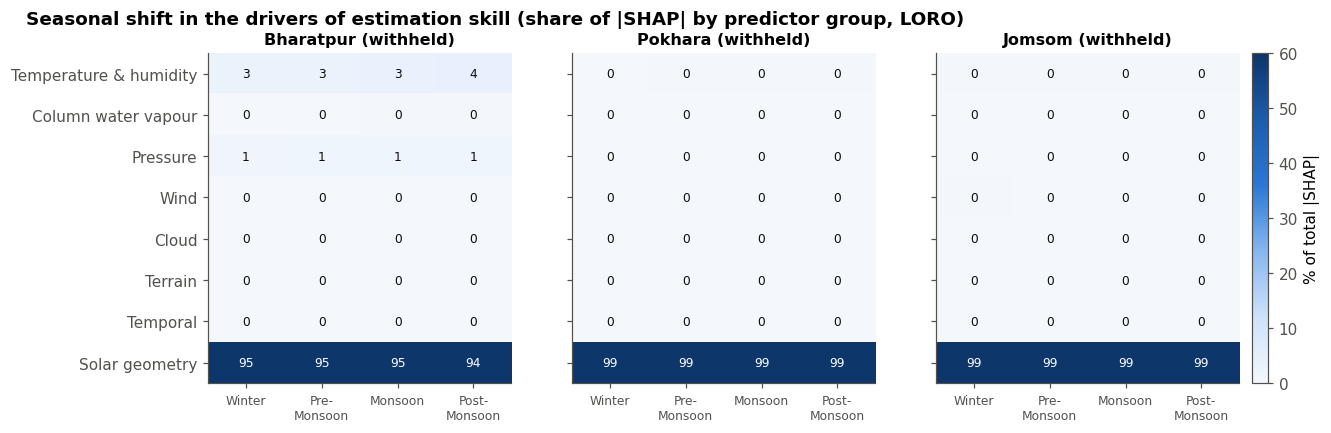

In [70]:
# Fig R14 – attribution by season: share of total |SHAP| per feature group, region × season (LORO models)
def group_of(f): return next(g for g, c in GROUPS.items() if f in c)
fig, axes = plt.subplots(1, len(SITES), figsize=(4.8 * len(SITES), 3.9), sharey=True)
seas_rows = []
for ax, s in zip(axes, SITES):
    te, sv = SH[('loro', s)]
    g = sv.abs().T.groupby(group_of).sum().T
    g['season'] = te.season.values
    share = g.groupby('season', observed=True).sum(); share = share.div(share.sum(axis=1), axis=0) * 100
    share = share.reindex(SEASONS)[list(GROUPS)]
    for se, row in share.iterrows(): seas_rows.append(dict(site=s, season=se, **row.to_dict()))
    im = ax.imshow(share.T.values, cmap=SEQ, vmin=0, vmax=60, aspect='auto')
    for (a, b), v in np.ndenumerate(share.T.values):
        ax.text(b, a, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if v > 35 else INK)
    ax.set_xticks(range(4), [x.replace('-', '-\n') for x in SEASONS], fontsize=8); ax.set_yticks(range(len(GROUPS)), list(GROUPS))
    ax.grid(False); ax.set_title(f'{s} (withheld)')
fig.colorbar(im, ax=axes, pad=0.01).set_label('% of total |SHAP|')
pd.DataFrame(seas_rows).round(2).to_csv(RES_DIR / 'shap_group_share_by_season.csv', index=False)
suptitle(fig, 'Fig R14. Seasonal shift in the drivers of estimation skill (share of |SHAP| by predictor group, LORO)'); save(fig, 'R14_shap_season')

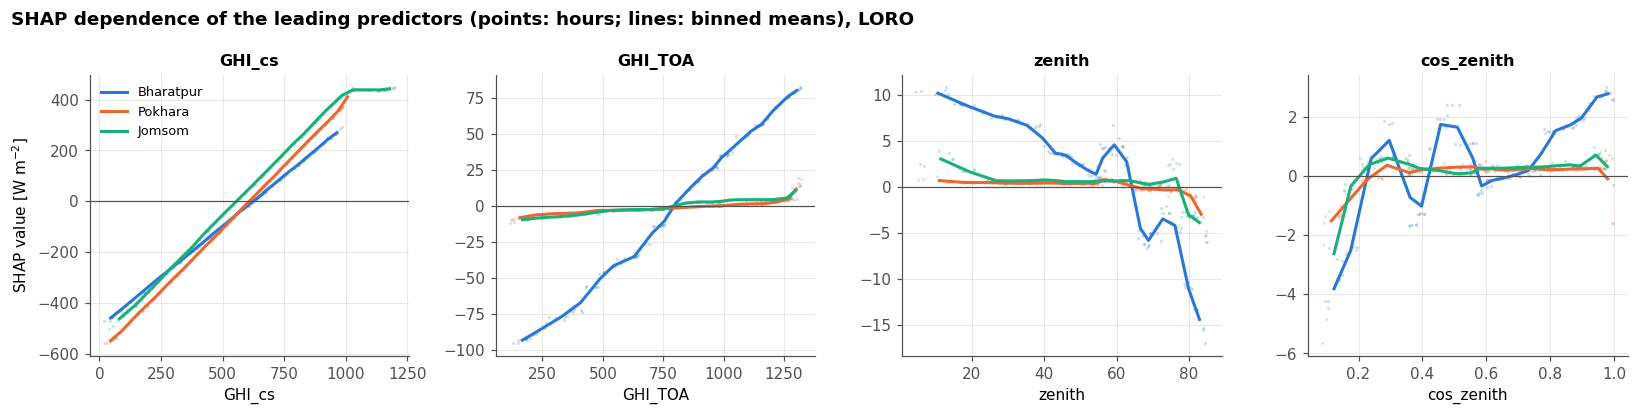

In [71]:
# Fig R15 – SHAP dependence of the four most important predictors, regions overlaid (LORO)
top4 = imp.mean(axis=1).sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, f in zip(axes, top4):
    for s in SITES:
        te, sv = SH[('loro', s)]
        ax.scatter(te[f], sv[f], s=4, alpha=0.25, color=SITE_C[s], lw=0, rasterized=True)
        b = pd.qcut(te[f].rank(method='first'), 20); mline = pd.DataFrame({'x': te[f], 'y': sv[f]}).groupby(b, observed=True).mean()
        ax.plot(mline.x, mline.y, color=SITE_C[s], lw=2, label=s)
    ax.axhline(0, color=INK2, lw=0.8); ax.set_xlabel(f); ax.set_title(f)
axes[0].set_ylabel('SHAP value [W m$^{-2}$]'); axes[0].legend(markerscale=3)
suptitle(fig, 'Fig R15. SHAP dependence of the leading predictors (points: hours; lines: binned means), LORO'); fig.tight_layout(); save(fig, 'R15_shap_dependence')

## H. RQ2 / H2 — Distribution of error and uncertainty across zones, seasons and sky conditions

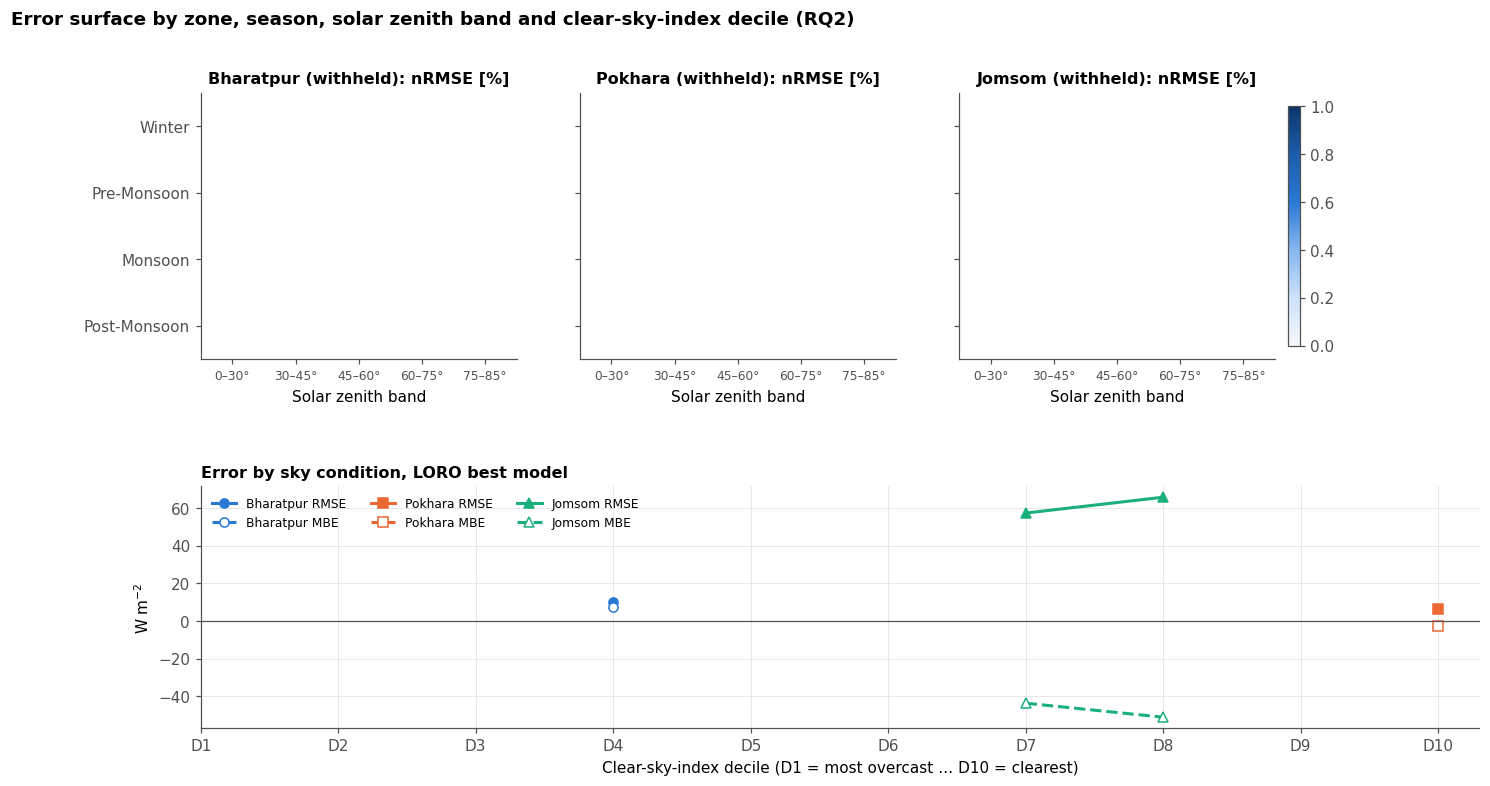

In [75]:
# Conformal intervals for the best model of every fold (safe-guarded against None values from sparse folds)
intervals = []
for p in ('temporal', 'loro'):
    for s in SITES:
        # Retrieve best model safely from BEST dict
        bm = BEST.get((p, s), BEST.get(('temporal', s), 'RF'))
        res = conformal(p, s, bm)
        if res is not None:
            intervals.append(res.assign(protocol=p, site=s))
CI = pd.concat(intervals, ignore_index=True)

# Fig R16 – error surface (LORO, best model): nRMSE by season × solar zenith band, and by clear-sky-index decile
fig = plt.figure(figsize=(15, 7.5)); gs = fig.add_gridspec(2, len(SITES), height_ratios=[1.1, 1], hspace=0.5)
surf_rows = []
vmax = 0
tabs = {}
for s in SITES:
    d = CI[(CI.protocol == 'loro') & (CI.site == s)]
    if d.empty:
        tabs[s] = pd.DataFrame(np.nan, index=SEASONS, columns=SZA_LAB)
        continue
    t = d.groupby(['season', 'sza_band'], observed=True).apply(lambda g: metrics(g.obs, g.pred)['nRMSE'] if len(g) > 30 else np.nan).unstack()
    tabs[s] = t.reindex(index=SEASONS, columns=SZA_LAB);
    if not t.empty:
        vmax = max(vmax, np.nanmax(tabs[s].values))
for j, s in enumerate(SITES):
    ax = fig.add_subplot(gs[0, j]); t = tabs[s]
    im = ax.imshow(t.values, cmap=SEQ, vmin=0, vmax=max(vmax, 1), aspect='auto')
    for (a, b), v in np.ndenumerate(t.values):
        if np.isfinite(v): ax.text(b, a, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if v > 0.6 * vmax else INK)
    ax.set_xticks(range(len(SZA_LAB)), SZA_LAB, fontsize=8); ax.set_yticks(range(4), SEASONS if j == 0 else [''] * 4)
    ax.set_xlabel('Solar zenith band'); ax.set_title(f'{s} (withheld): nRMSE [%]'); ax.grid(False)
    for se in SEASONS:
        for b in SZA_LAB: surf_rows.append(dict(site=s, season=se, sza_band=b, nRMSE=t.loc[se, b]))
fig.colorbar(im, ax=fig.axes[:len(SITES)], pad=0.01, shrink=0.9)
ax = fig.add_subplot(gs[1, :])
deciles_index = [f'D{i}' for i in range(1, 11)]
for s in SITES:
    d = CI[(CI.protocol == 'loro') & (CI.site == s)]
    if d.empty: continue
    g = d.groupby('kc_decile', observed=True).apply(lambda g: pd.Series({'RMSE': np.sqrt(np.mean((g.pred - g.obs)**2)), 'MBE': (g.pred - g.obs).mean()}))
    g = g.reindex(deciles_index)
    ax.plot(range(10), g.RMSE, color=SITE_C[s], marker=SITE_M[s], label=f'{s} RMSE')
    ax.plot(range(10), g.MBE, color=SITE_C[s], marker=SITE_M[s], ls='--', mfc='white', label=f'{s} MBE')
ax.axhline(0, color=INK2, lw=0.8); ax.set_xticks(range(10), deciles_index)
ax.set_xlabel('Clear-sky-index decile (D1 = most overcast … D10 = clearest)'); ax.set_ylabel('W m$^{-2}$'); ax.legend(ncol=3, fontsize=8)
ax.set_title('Error by sky condition, LORO best model', loc='left')
pd.DataFrame(surf_rows).round(2).to_csv(RES_DIR / 'error_surface_season_sza.csv', index=False)
suptitle(fig, 'Fig R16. Error surface by zone, season, solar zenith band and clear-sky-index decile (RQ2)'); save(fig, 'R16_error_surface')

⚠ Observed GHI = clear-sky GHI (fake target): kc is constant, so sky-condition deciles are meaningless.
No interval (fold skipped or too few validation hours): ['temporal/Pokhara']


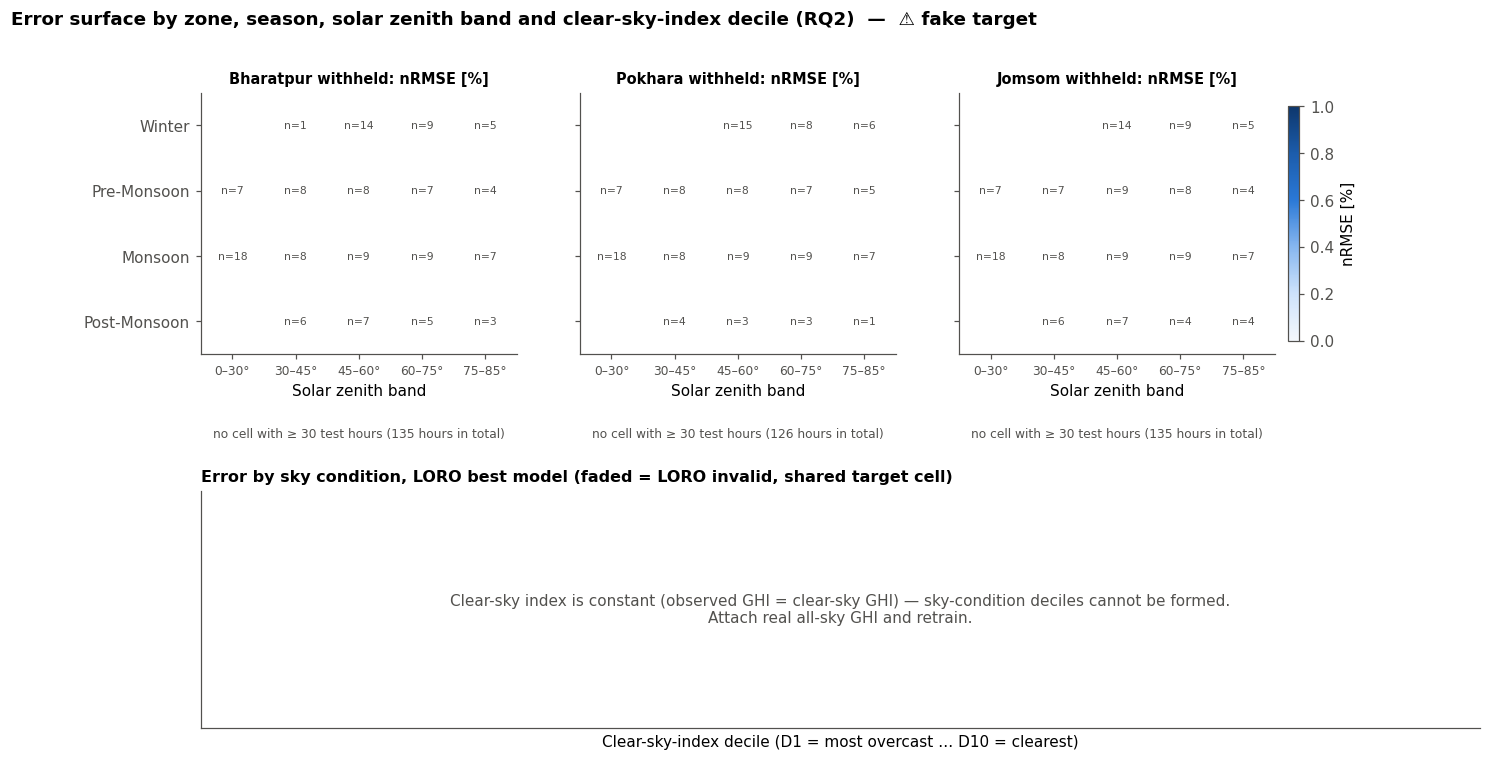

Test hours per withheld site: {'Bharatpur': 135, 'Jomsom': 135, 'Pokhara': 126}  (need ≈ 4,000 for a full year)


In [76]:
# Fig R16 – error surface (LORO, best model): nRMSE by season × solar zenith band, and error by clear-sky-index decile
MIN_N = 30                       # hours needed for a reliable nRMSE in a heat-map cell
DEC = [f'D{i}' for i in range(1, 11)]
if 'LORO_VALID' not in globals():
    f = RES_DIR / 'target_validity.json'
    LORO_VALID = json.load(open(f))['LORO_valid'] if f.exists() else {s: True for s in SITES}

# ---- 0. Sanity checks on the target ----
tst = P[(P.part == 'test') & P.GHI_cs.gt(0)]
FAKE_TARGET = len(tst) > 0 and (tst.obs - tst.GHI_cs).abs().mean() < 1.0
if FAKE_TARGET:
    print('⚠ Observed GHI = clear-sky GHI (fake target): kc is constant, so sky-condition deciles are meaningless.')

# ---- 1. Conformal intervals for the best model of every fold (best chosen on the validation year) ----
def best_model(protocol, site):
    v = P[(P.protocol == protocol) & (P.site == site) & (P.part == 'val') & P.model.isin(ML_MODELS)]
    return None if v.empty else v.groupby('model').apply(lambda g: np.sqrt(np.mean((g.pred - g.obs) ** 2))).idxmin()

intervals, missing = [], []
for p in ('temporal', 'loro'):
    for s in SITES:
        bm = best_model(p, s)
        res = conformal(p, s, bm) if bm else None
        if res is None: missing.append(f'{p}/{s}'); continue
        intervals.append(res.assign(protocol=p, site=s, best=bm))
if missing: print('No interval (fold skipped or too few validation hours):', missing)
CI = pd.concat(intervals, ignore_index=True)

# ---- 2. Clear-sky index deciles from the test data itself (not row order) ----
CI['kc'] = (CI.obs / CI.GHI_cs.replace(0, np.nan)).clip(0, 1.3)
KC_VARIES = CI.kc.std() > 0.01
if KC_VARIES:
    edges = np.unique(np.nanquantile(CI.kc, np.linspace(0, 1, 11)))
    CI['kc_dec'] = pd.cut(CI.kc, edges, labels=DEC[:len(edges) - 1], include_lowest=True)
else:
    CI['kc_dec'] = np.nan

# ---- 3. Figure ----
L = CI[CI.protocol == 'loro']
fig = plt.figure(figsize=(15, 7.5)); gs = fig.add_gridspec(2, len(SITES), height_ratios=[1.1, 1], hspace=0.55)
tabs, ns, surf_rows = {}, {}, []
for s in SITES:
    d = L[L.site == s]
    grp = d.groupby(['season', 'sza_band'], observed=True)
    ns[s]   = grp.size().unstack().reindex(index=SEASONS, columns=SZA_LAB)
    tabs[s] = grp.apply(lambda g: metrics(g.obs, g.pred)['nRMSE'] if len(g) >= MIN_N else np.nan).unstack().reindex(index=SEASONS, columns=SZA_LAB) \
              if len(d) else pd.DataFrame(np.nan, index=SEASONS, columns=SZA_LAB)
allv = np.concatenate([t.values.ravel() for t in tabs.values()])
vmax = float(np.nanmax(allv)) if np.isfinite(allv).any() else 1.0

for j, s in enumerate(SITES):
    ax = fig.add_subplot(gs[0, j]); t, n = tabs[s], ns[s]
    im = ax.imshow(t.values.astype(float), cmap=SEQ, vmin=0, vmax=vmax, aspect='auto')
    for (a, b), v in np.ndenumerate(t.values):
        cnt = n.values[a, b]
        if np.isfinite(v):
            ax.text(b, a, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if v > 0.6 * vmax else INK)
        elif np.isfinite(cnt) and cnt > 0:
            ax.text(b, a, f'n={int(cnt)}', ha='center', va='center', fontsize=7, color=INK2)   # too few hours
        surf_rows.append(dict(site=s, season=SEASONS[a], sza_band=SZA_LAB[b], n=cnt, nRMSE=v))
    ax.set_xticks(range(len(SZA_LAB)), SZA_LAB, fontsize=8); ax.set_yticks(range(len(SEASONS)), SEASONS if j == 0 else [''] * len(SEASONS))
    ax.set_xlabel('Solar zenith band'); ax.grid(False)
    flag = '' if LORO_VALID.get(s, True) else '  ⚠ invalid (shared target cell)'
    ax.set_title(f'{s} withheld: nRMSE [%]{flag}', fontsize=9.5)
    if not np.isfinite(t.values.astype(float)).any():
        ax.text(0.5, -0.32, f'no cell with ≥ {MIN_N} test hours ({int(np.nansum(n.values))} hours in total)',
                transform=ax.transAxes, ha='center', fontsize=8, color=INK2)
fig.colorbar(im, ax=fig.axes[:len(SITES)], pad=0.01, shrink=0.9, label='nRMSE [%]')

ax = fig.add_subplot(gs[1, :])
if not KC_VARIES:
    ax.text(0.5, 0.5, 'Clear-sky index is constant (observed GHI = clear-sky GHI) — sky-condition deciles cannot be formed.\n'
                      'Attach real all-sky GHI and retrain.', transform=ax.transAxes, ha='center', va='center', color=INK2)
    ax.set_xticks([]); ax.set_yticks([])
else:
    dec_rows = []
    for s in SITES:
        d = L[L.site == s]
        if d.empty: continue
        g = d.groupby('kc_dec', observed=False).apply(lambda g: pd.Series({
            'n': len(g), 'RMSE': np.sqrt(np.mean((g.pred - g.obs) ** 2)) if len(g) >= 10 else np.nan,
            'MBE': (g.pred - g.obs).mean() if len(g) >= 10 else np.nan})).reindex(DEC)
        ls_extra = dict(alpha=1.0 if LORO_VALID.get(s, True) else 0.45)
        ax.plot(range(10), g.RMSE, color=SITE_C[s], marker=SITE_M[s], label=f'{s} RMSE', **ls_extra)
        ax.plot(range(10), g.MBE, color=SITE_C[s], marker=SITE_M[s], ls='--', mfc='white', label=f'{s} MBE', **ls_extra)
        dec_rows.append(g.assign(site=s))
    pd.concat(dec_rows).round(2).to_csv(RES_DIR / 'error_by_kc_decile.csv')
    ax.axhline(0, color=INK2, lw=0.8); ax.set_xticks(range(10), DEC); ax.legend(ncol=3, fontsize=8)
    ax.set_ylabel('W m$^{-2}$')
ax.set_xlabel('Clear-sky-index decile (D1 = most overcast … D10 = clearest)')
ax.set_title('Error by sky condition, LORO best model (faded = LORO invalid, shared target cell)', loc='left')

pd.DataFrame(surf_rows).round(2).to_csv(RES_DIR / 'error_surface_season_sza.csv', index=False)
suptitle(fig, 'Fig R16. Error surface by zone, season, solar zenith band and clear-sky-index decile (RQ2)'
              + ('  —  ⚠ fake target' if FAKE_TARGET else ''))
save(fig, 'R16_error_surface')
print(f'Test hours per withheld site: {L.groupby("site").size().to_dict()}  (need ≈ 4,000 for a full year)')

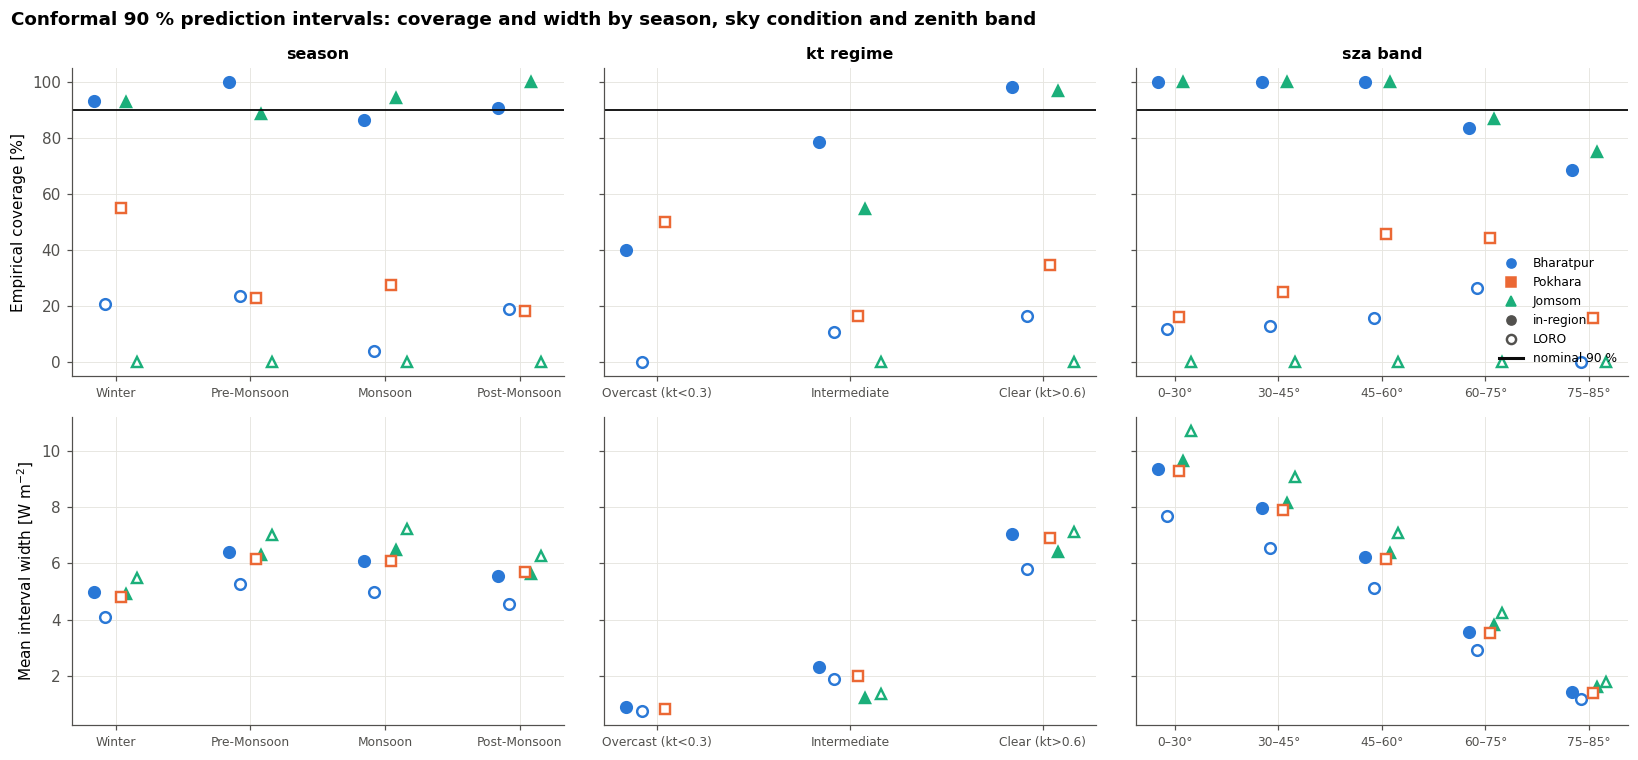

In [79]:
# Fig R17 – prediction-interval reliability: empirical coverage and width by stratum (nominal 90 %)
strata = [('season', SEASONS), ('kt_regime', ['Overcast (kt<0.3)', 'Intermediate', 'Clear (kt>0.6)']), ('sza_band', SZA_LAB)]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey='row')
cov_rows = []

# Calculate the interval width prior to grouping since it's missing in CI
if 'width' not in CI.columns and 'hi' in CI.columns and 'lo' in CI.columns:
    CI['width'] = CI['hi'] - CI['lo']

for j, (col, levels) in enumerate(strata):
    for proto, mfc in (('temporal', None), ('loro', 'white')):
        for k, s in enumerate(SITES):
            d = CI[(CI.protocol == proto) & (CI.site == s)]
            g = d.groupby(col, observed=True).agg(cov=('covered', 'mean'), width=('width', 'mean'), n=('covered', 'size')).reindex(levels)
            x = np.arange(len(levels)) + (k - 1) * 0.12 + (0.04 if proto == 'loro' else -0.04)
            axes[0, j].plot(x, 100 * g['cov'], marker=SITE_M[s], ls='', color=SITE_C[s], mfc=mfc or SITE_C[s], mew=1.6, ms=7)
            axes[1, j].plot(x, g['width'], marker=SITE_M[s], ls='', color=SITE_C[s], mfc=mfc or SITE_C[s], mew=1.6, ms=7)
            for lv, r in g.iterrows(): cov_rows.append(dict(protocol=proto, site=s, stratum=col, level=lv, coverage=r['cov'], width=r['width'], n=r['n']))
    axes[0, j].axhline(100 * (1 - ALPHA), color=INK, lw=1.2); axes[0, j].set_title(col.replace('_', ' '))
    for r in (0, 1): axes[r, j].set_xticks(range(len(levels)), levels, fontsize=8)
axes[0, 0].set_ylabel('Empirical coverage [%]'); axes[1, 0].set_ylabel('Mean interval width [W m$^{-2}$]')
h = [plt.Line2D([], [], marker=SITE_M[s], ls='', color=SITE_C[s], label=s) for s in SITES]
h += [plt.Line2D([], [], marker='o', ls='', color=INK2, label='in-region'), plt.Line2D([], [], marker='o', ls='', color=INK2, mfc='white', mew=1.6, label='LORO'),
      plt.Line2D([], [], color=INK, label=f'nominal {100*(1-ALPHA):.0f} %')]
axes[0, -1].legend(handles=h, fontsize=8, loc='lower right')
COV = pd.DataFrame(cov_rows); COV.round(4).to_csv(RES_DIR / 'interval_coverage_by_stratum.csv', index=False)
suptitle(fig, 'Fig R17. Conformal 90 % prediction intervals: coverage and width by season, sky condition and zenith band'); fig.tight_layout(); save(fig, 'R17_interval_reliability')

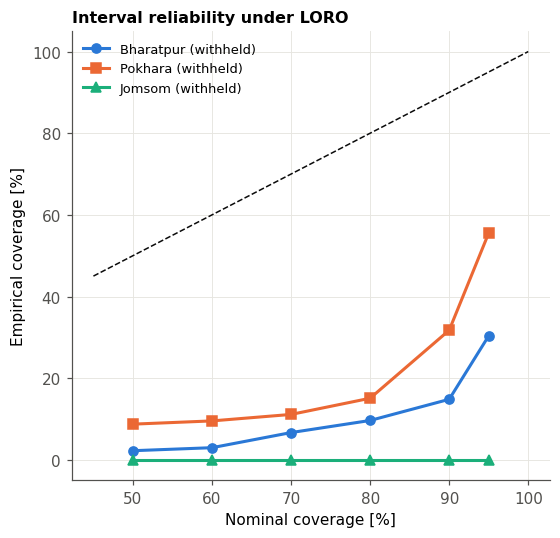

In [81]:
# Fig R18 – reliability diagram: nominal vs empirical coverage over a range of levels (LORO)
fig, ax = plt.subplots(figsize=(5.2, 5))
levels = np.array([0.5, 0.6, 0.7, 0.8, 0.9, 0.95])
for s in SITES:
    # Use a safe-guard fallback to retrieve the best model
    bm = BEST.get(('loro', s), BEST.get(('temporal', s), 'RF'))
    emp = [conformal('loro', s, bm, alpha=1 - l).covered.mean() for l in levels]
    ax.plot(100 * levels, 100 * np.array(emp), color=SITE_C[s], marker=SITE_M[s], label=f'{s} (withheld)')
ax.plot([45, 100], [45, 100], color=INK, lw=1, ls='--'); ax.set_xlabel('Nominal coverage [%]'); ax.set_ylabel('Empirical coverage [%]')
ax.legend(); ax.set_title('Fig R18. Interval reliability under LORO', loc='left'); fig.tight_layout(); save(fig, 'R18_reliability_diagram')

### H2 — Distribution-equity hypothesis test (Jomsom vs Bharatpur under LORO)
- (a) raw nRMSE ratio Jomsom / Bharatpur ≥ 1.25;
- (b) the ratio persists after controlling for mean irradiance: Jomsom's per-stratum errors (solar zenith band × clear-sky-index quintile)
  are re-weighted to Bharatpur's distribution of strata and normalised by Bharatpur's mean GHI;
- (c) interval coverage at Jomsom < coverage at Bharatpur at the same nominal level.

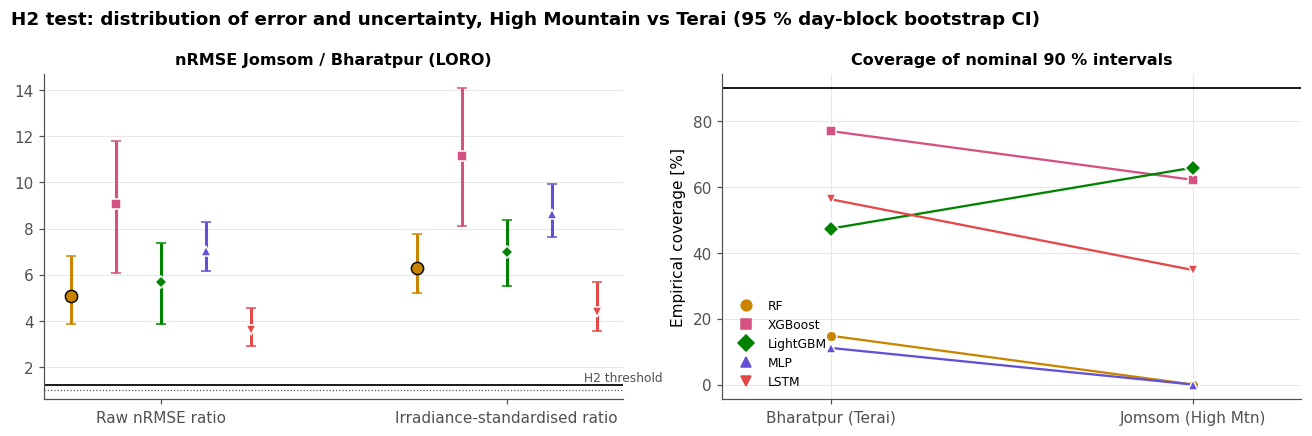

,model,best,ratio_raw,raw_lo,raw_hi,ratio_std,std_lo,std_hi,cov_Jomsom,cov_Bharatpur,a_raw_ge_1.25,b_std_ge_1.25,c_cov_lower,H2_supported,LORO_valid
0,RF,True,5.091,3.877,6.823,6.285,5.220,7.787,0.000,0.148,True,True,True,True,False
1,XGBoost,False,9.050,6.078,11.791,11.134,8.094,14.067,0.622,0.770,True,True,True,True,False
2,LightGBM,False,5.692,3.889,7.383,7.004,5.528,8.385,0.659,0.474,True,True,False,False,False
3,MLP,False,7.012,6.152,8.275,8.625,7.620,9.935,0.000,0.111,True,True,True,True,False
4,LSTM,False,3.622,2.930,4.561,4.402,3.558,5.700,0.348,0.563,True,True,True,True,False


In [84]:
def strat_nrmse(d, ref):
    """nRMSE of d re-weighted to the stratum distribution of ref, normalised by ref's mean observed GHI."""
    key = lambda x: x.sza_band.astype(str) + '|' + \
                    pd.cut((x.obs / x.GHI_cs).clip(0, 1.3), [0, .2, .4, .6, .8, 1.31], include_lowest=True).astype(str)
    mse = ((d.pred - d.obs)**2).groupby(key(d)).mean(); w = key(ref).value_counts(normalize=True)
    common = w.index.intersection(mse.index); w = w[common] / w[common].sum()
    return 100 * np.sqrt((mse[common] * w).sum()) / ref.obs.mean()
hi, lo_ = 'Jomsom', 'Bharatpur'
h2 = []
for m in ML_MODELS:
    J = TEST[(TEST.protocol == 'loro') & (TEST.site == hi) & (TEST.model == m)]
    B = TEST[(TEST.protocol == 'loro') & (TEST.site == lo_) & (TEST.model == m)]
    if J.empty or B.empty: continue
    raw_ratio = metrics(J.obs, J.pred)['nRMSE'] / metrics(B.obs, B.pred)['nRMSE']
    std_ratio = strat_nrmse(J, B) / metrics(B.obs, B.pred)['nRMSE']
    rng = np.random.default_rng(SEED); dJ, dB = J.date.unique(), B.date.unique(); gJ, gB = J.groupby('date').indices, B.groupby('date').indices
    br, bs = [], []
    for _ in range(N_BOOT):
        jj = J.iloc[np.concatenate([gJ[d] for d in rng.choice(dJ, len(dJ))])]; bb = B.iloc[np.concatenate([gB[d] for d in rng.choice(dB, len(dB))])]
        nb = metrics(bb.obs, bb.pred)['nRMSE']; br.append(metrics(jj.obs, jj.pred)['nRMSE'] / nb); bs.append(strat_nrmse(jj, bb) / nb)
    cj = conformal('loro', hi, m).covered; cb = conformal('loro', lo_, m).covered
    loro_best_hi = BEST.get(('loro', hi), BEST.get(('temporal', hi), 'RF'))
    h2.append(dict(model=m, best=(loro_best_hi == m), ratio_raw=raw_ratio, raw_lo=np.percentile(br, 2.5), raw_hi=np.percentile(br, 97.5),
                   ratio_std=std_ratio, std_lo=np.percentile(bs, 2.5), std_hi=np.percentile(bs, 97.5),
                   cov_Jomsom=cj.mean(), cov_Bharatpur=cb.mean()))
H2 = pd.DataFrame(h2)
H2['a_raw_ge_1.25'] = H2.ratio_raw >= 1.25; H2['b_std_ge_1.25'] = H2.ratio_std >= 1.25; H2['c_cov_lower'] = H2.cov_Jomsom < H2.cov_Bharatpur
H2['H2_supported'] = H2[['a_raw_ge_1.25', 'b_std_ge_1.25', 'c_cov_lower']].all(axis=1)
H2['LORO_valid'] = not ({'Jomsom', 'Bharatpur'} & SHARED)
H2.round(3).to_csv(RES_DIR / 'H2_test.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j, m in enumerate(H2.model):
    r = H2[H2.model == m].iloc[0]
    for k, (c, lo, hi_, lab) in enumerate([('ratio_raw', 'raw_lo', 'raw_hi', 'raw'), ('ratio_std', 'std_lo', 'std_hi', 'irradiance-standardised')]):
        x = k + (j - (len(H2) - 1) / 2) * 0.13
        axes[0].errorbar(x, r[c], yerr=[[r[c] - r[lo]], [r[hi_] - r[c]]], fmt=MM[m], color=MC[m], ms=8 if r.best else 6,
                         mec=INK if r.best else 'white', capsize=3)
    axes[1].plot([0, 1], [100 * r.cov_Bharatpur, 100 * r.cov_Jomsom], color=MC[m], marker=MM[m], ms=7, mec='white', lw=1.5)
axes[0].axhline(1.25, color=INK, lw=1.2); axes[0].axhline(1, color=INK2, lw=0.8, ls=':')
axes[0].set_xticks([0, 1], ['Raw nRMSE ratio', 'Irradiance-standardised ratio']); axes[0].set_title('nRMSE Jomsom / Bharatpur (LORO)')
axes[0].text(1.45, 1.25, ' H2 threshold', va='bottom', ha='right', fontsize=8, color=INK2); axes[0].grid(axis='x', visible=False)
axes[1].axhline(100 * (1 - ALPHA), color=INK, lw=1.2); axes[1].set_xticks([0, 1], ['Bharatpur (Terai)', 'Jomsom (High Mtn)'])
axes[1].set_xlim(-0.3, 1.3); axes[1].set_ylabel('Empirical coverage [%]'); axes[1].set_title(f'Coverage of nominal {100*(1-ALPHA):.0f} % intervals')
model_legend(axes[1], list(H2.model), loc='lower left', fontsize=8)
suptitle(fig, 'Fig R19. H2 test: distribution of error and uncertainty, High Mountain vs Terai (95 % day-block bootstrap CI)')
fig.tight_layout(); save(fig, 'R19_H2_test')
H2.round(3)

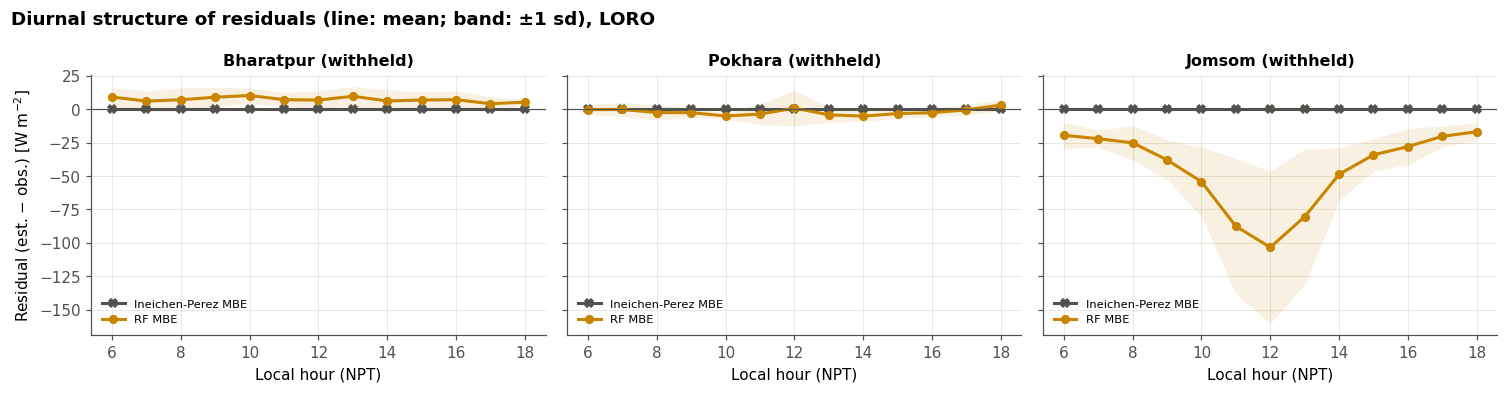

In [86]:
# Fig R20 – residual diagnostics by local hour (systematic diurnal bias), best model vs Ineichen–Perez, LORO
fig, axes = plt.subplots(1, len(SITES), figsize=(4.6 * len(SITES), 3.6), sharey=True)
for ax, s in zip(axes, SITES):
    # Retrieve best model safely using get fallback
    loro_best = BEST.get(('loro', s), BEST.get(('temporal', s), 'RF'))
    for m in ['Ineichen-Perez', loro_best]:
        d = TEST[(TEST.protocol == 'loro') & (TEST.site == s) & (TEST.model == m)]
        if d.empty:
            continue
        g = (d.pred - d.obs).groupby(d.hour).agg(['mean', 'std'])
        ax.plot(g.index, g['mean'], color=MC[m], marker=MM[m], ms=5, label=f'{m} MBE')
        ax.fill_between(g.index, g['mean'] - g['std'], g['mean'] + g['std'], color=MC[m], alpha=0.12, lw=0)
    ax.axhline(0, color=INK2, lw=0.8); ax.set_title(f'{s} (withheld)'); ax.set_xlabel('Local hour (NPT)'); ax.legend(fontsize=7.5)
axes[0].set_ylabel('Residual (est. − obs.) [W m$^{-2}$]')
suptitle(fig, 'Fig R20. Diurnal structure of residuals (line: mean; band: ±1 sd), LORO'); fig.tight_layout(); save(fig, 'R20_residual_diurnal')

## H3. Additional evidence (version 2)
R21 paired significance and skill relative to Ineichen–Perez (RQ1 "paired error metrics"), R22 seasonal skill of every model
(proposal: seasonal evaluation), R23 quantile regression vs conformalised intervals (proposal Table 3: "quantile objectives").

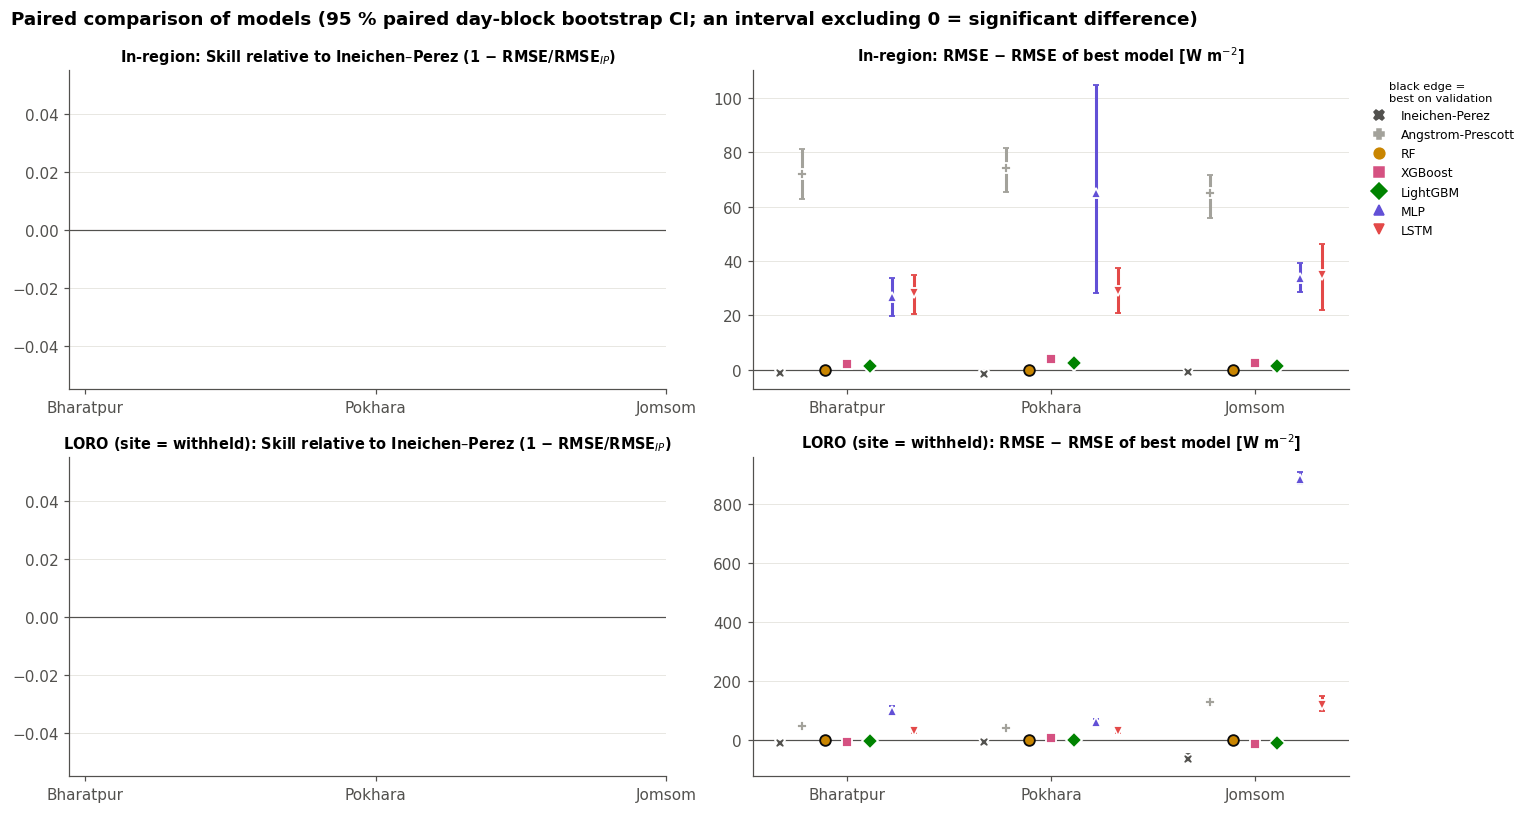

In [88]:
# Fig R21 – paired day-block bootstrap: skill relative to Ineichen–Perez and RMSE difference from the best model
rows = []
for proto in ('temporal', 'loro'):
    for s in SITES:
        d = TEST[(TEST.protocol == proto) & (TEST.site == s)]
        e2 = d.assign(e2=(d.pred - d.obs)**2).groupby(['date', 'model']).e2.agg(['sum', 'size'])
        sse, n = e2['sum'].unstack('model'), e2['size'].unstack('model')
        mods = [m for m in MODELS if m in sse.columns]
        Sv, Nv = sse[mods].fillna(0).values, n[mods].fillna(0).values
        rmse = np.sqrt(Sv.sum(0) / Nv.sum(0))
        Bi = np.random.default_rng(SEED).integers(0, len(Sv), size=(N_BOOT, len(Sv)))   # same days for every model → paired
        boot = np.sqrt(Sv[Bi].sum(1) / Nv[Bi].sum(1))

        # Safe lookup for the best model using a fallback chain
        best_model_name = BEST.get((proto, s), BEST.get(('temporal', s), 'RF'))
        b, ip = mods.index(best_model_name), mods.index('Ineichen-Perez')
        for j, m in enumerate(mods):
            diff, ss = boot[:, j] - boot[:, b], 1 - boot[:, j] / boot[:, ip]
            rows.append(dict(protocol=proto, site=s, model=m, best=best_model_name, RMSE=rmse[j], dRMSE_vs_best=rmse[j] - rmse[b],
                             d_lo=np.percentile(diff, 2.5), d_hi=np.percentile(diff, 97.5), skill=1 - rmse[j] / rmse[ip],
                             skill_lo=np.percentile(ss, 2.5), skill_hi=np.percentile(ss, 97.5)))
PAIR = pd.DataFrame(rows); PAIR['diff_significant'] = (PAIR.d_lo > 0) | (PAIR.d_hi < 0)
PAIR.round(4).to_csv(RES_DIR / 'paired_comparison_skill.csv', index=False)
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
for i, proto in enumerate(('temporal', 'loro')):
    for c, (col, lo, hi, lab) in enumerate([('skill', 'skill_lo', 'skill_hi', 'Skill relative to Ineichen–Perez (1 − RMSE/RMSE$_{IP}$)'),
                                            ('dRMSE_vs_best', 'd_lo', 'd_hi', 'RMSE − RMSE of best model [W m$^{-2}$]')]):
        ax = axes[i, c]
        for k, s in enumerate(SITES):
            for j, m in enumerate([m for m in MODELS if m != 'Ineichen-Perez' or c == 1]):
                r = PAIR[(PAIR.protocol == proto) & (PAIR.site == s) & (PAIR.model == m)]
                if r.empty: continue
                r = r.iloc[0]; x = k + (j - 3) * 0.11
                ax.errorbar(x, r[col], yerr=[[r[col] - r[lo]], [r[hi] - r[col]]], fmt=MM[m], color=MC[m], ms=7,
                            mec=INK if m == r.best else 'white', mew=1.2, capsize=2)
        ax.axhline(0, color=INK2, lw=0.8); ax.set_xticks(range(len(SITES)), SITES); ax.grid(axis='x', visible=False)
        ax.set_title(f"{'In-region' if proto == 'temporal' else 'LORO (site = withheld)'}: {lab}", fontsize=9.5)
model_legend(axes[0, 1], MODELS, loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8, title='black edge =\nbest on validation', title_fontsize=7.5)
suptitle(fig, 'Fig R21. Paired comparison of models (95 % paired day-block bootstrap CI; an interval excluding 0 = significant difference)')
fig.tight_layout(); save(fig, 'R21_paired_skill')

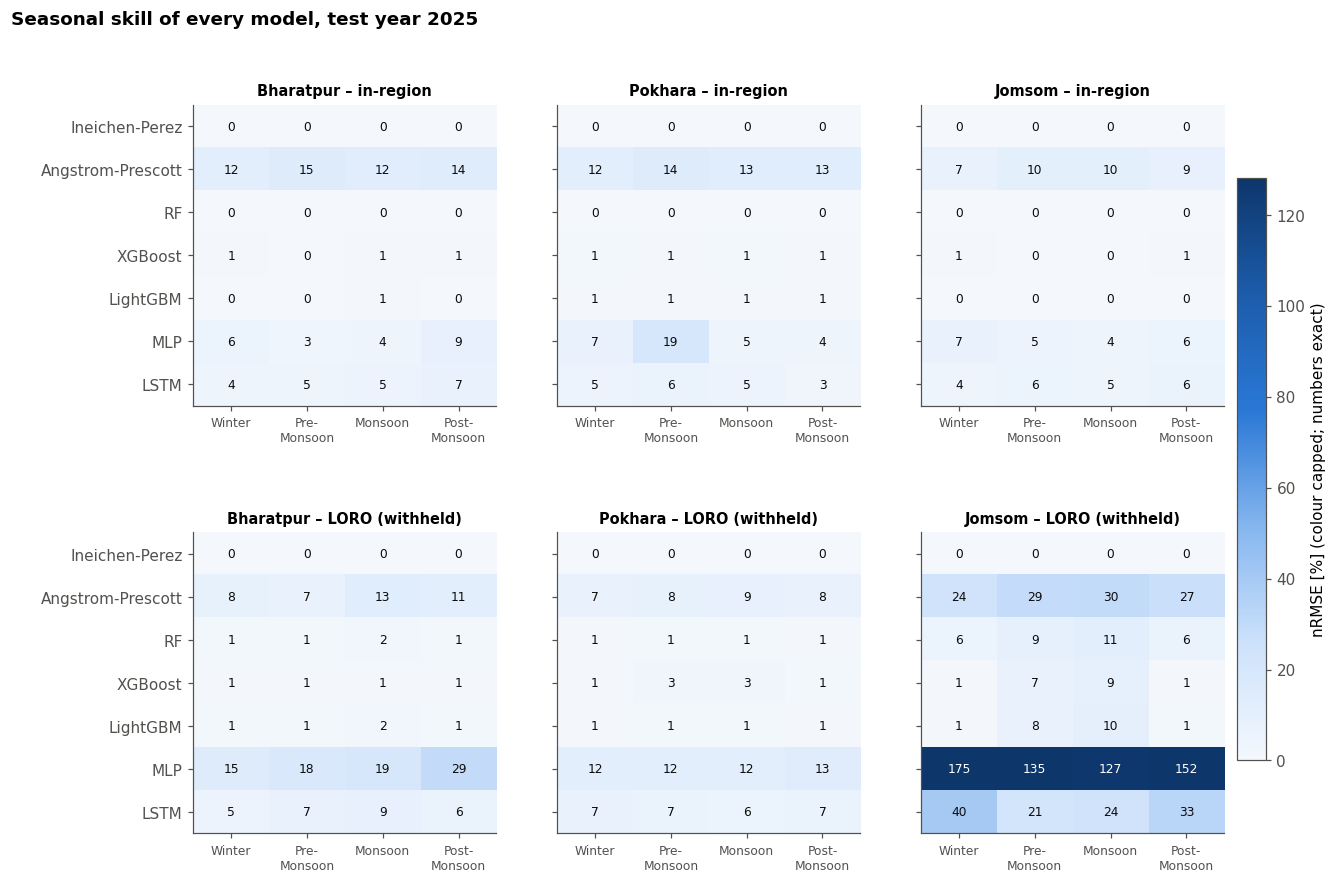

In [89]:
# Fig R22 – seasonal skill of every model (nRMSE by season), in-region and LORO
SEAS = mtable(TEST[TEST.protocol.isin(['temporal', 'loro'])], ['protocol', 'site', 'season', 'model'])
SEAS.round(3).to_csv(RES_DIR / 'metrics_by_season.csv', index=False)
show_m = [m for m in MODELS if m in SEAS.model.unique()]
vmax = np.nanpercentile(SEAS[SEAS.model.isin(ML_MODELS + ['Angstrom-Prescott'])].nRMSE, 98)
fig, axes = plt.subplots(2, len(SITES), figsize=(4.8 * len(SITES), 8.6), sharey=True, gridspec_kw=dict(hspace=0.42))
for i, proto in enumerate(('temporal', 'loro')):
    for j, s in enumerate(SITES):
        ax = axes[i, j]
        h = SEAS[(SEAS.protocol == proto) & (SEAS.site == s)].pivot(index='model', columns='season', values='nRMSE').reindex(index=show_m, columns=SEASONS)
        im = ax.imshow(np.clip(h.values, 0, vmax), cmap=SEQ, vmin=0, vmax=vmax, aspect='auto')
        for (a, b), v in np.ndenumerate(h.values):
            ax.text(b, a, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if v > 0.6 * vmax else INK)
        ax.set_xticks(range(4), [x.replace('-', '-\n') for x in SEASONS], fontsize=8); ax.set_yticks(range(len(show_m)), show_m)
        ax.grid(False); ax.set_title(f"{s} – {'in-region' if proto == 'temporal' else 'LORO (withheld)'}", fontsize=9.5)
fig.colorbar(im, ax=axes, pad=0.01, shrink=0.8).set_label('nRMSE [%] (colour capped; numbers exact)')
suptitle(fig, 'Fig R22. Seasonal skill of every model, test year 2025'); save(fig, 'R22_seasonal_skill')

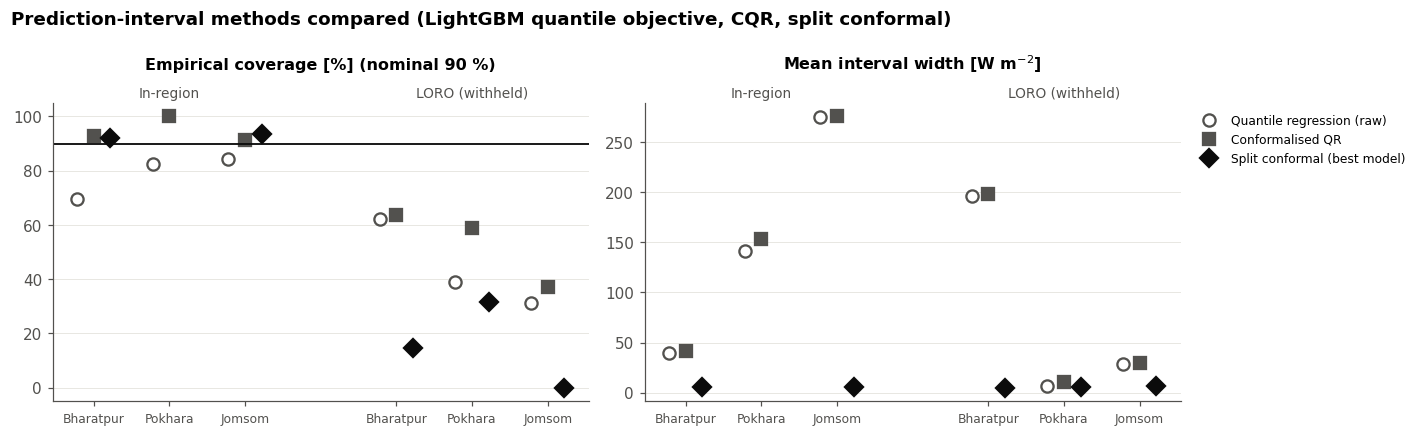

,protocol,site,method,coverage,width
0,temporal,Bharatpur,Quantile regression (raw),0.696,39.382
1,temporal,Bharatpur,Conformalised QR,0.926,41.341
2,temporal,Bharatpur,Split conformal (best model),0.919,5.842
3,temporal,Pokhara,Quantile regression (raw),0.825,141.835
4,temporal,Pokhara,Conformalised QR,1.000,152.963
5,temporal,Pokhara,Split conformal (best model),NaN,NaN
6,temporal,Jomsom,Quantile regression (raw),0.844,275.391
7,temporal,Jomsom,Conformalised QR,0.911,275.996
8,temporal,Jomsom,Split conformal (best model),0.933,5.979
9,loro,Bharatpur,Quantile regression (raw),0.622,196.895


In [93]:
# Fig R23 – interval methods: LightGBM quantile regression (raw), conformalised quantile regression (CQR), split conformal
iv = []
for proto in ('temporal', 'loro'):
    for s in SITES:
        p = {k: v for k, v in PARAMS[(proto, s)]['LightGBM'].items() if k != 'objective'}
        pool = D[(D.site == s) if proto == 'temporal' else (D.site != s)]
        tr, va = pool[pool.year.isin(TRAIN_YEARS)], pool[pool.year == VAL_YEAR]
        te = D[(D.site == s) & (D.year == TEST_YEAR)]
        q = {a: lgb.LGBMRegressor(**dict(p, objective='quantile', alpha=a)).fit(tr[FEATURES], tr.GHI) for a in (ALPHA / 2, 1 - ALPHA / 2)}
        lv, hv = q[ALPHA / 2].predict(va[FEATURES]), q[1 - ALPHA / 2].predict(va[FEATURES])
        lt, ht = q[ALPHA / 2].predict(te[FEATURES]), q[1 - ALPHA / 2].predict(te[FEATURES])
        E = np.maximum(lv - va.GHI.values, va.GHI.values - hv); n = len(E)
        Q = np.quantile(E, min(1, np.ceil((n + 1) * (1 - ALPHA)) / n)); y = te.GHI.values
        for meth, lo, hi in (('Quantile regression (raw)', lt, ht), ('Conformalised QR', lt - Q, ht + Q)):
            lo = np.clip(lo, 0, None); iv.append(dict(protocol=proto, site=s, method=meth, coverage=np.mean((y >= lo) & (y <= hi)), width=np.mean(hi - lo)))

        # Safe lookup in BEST with fallbacks
        bm = BEST.get((proto, s), BEST.get(('temporal', s), 'RF'))
        c = conformal(proto, s, bm)
        if c is not None:
            iv.append(dict(protocol=proto, site=s, method='Split conformal (best model)', coverage=c.covered.mean(), width=(c.hi - c.lo).mean()))
        else:
            iv.append(dict(protocol=proto, site=s, method='Split conformal (best model)', coverage=np.nan, width=np.nan))

IV = pd.DataFrame(iv); IV.round(4).to_csv(RES_DIR / 'interval_methods.csv', index=False)
METH = {'Quantile regression (raw)': dict(marker='o', mfc='white', color=INK2), 'Conformalised QR': dict(marker='s', mfc=INK2, color=INK2),
        'Split conformal (best model)': dict(marker='D', mfc=INK, color=INK)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, lab in zip(axes, ['coverage', 'width'], [f'Empirical coverage [%] (nominal {100*(1-ALPHA):.0f} %)', 'Mean interval width [W m$^{-2}$]']):
    for i, proto in enumerate(('temporal', 'loro')):
        for k, s in enumerate(SITES):
            for j, (meth, st) in enumerate(METH.items()):
                r = IV[(IV.protocol == proto) & (IV.site == s) & (IV.method == meth)]
                if not r.empty and pd.notna(r[col].iloc[0]):
                    v = r[col].iloc[0] * (100 if col == 'coverage' else 1)
                    ax.plot(i * 4 + k + (j - 1) * 0.22, v, ls='', ms=8, mew=1.5, **st)
    ax.set_xticks([0, 1, 2, 4, 5, 6], SITES + SITES, fontsize=8); ax.grid(axis='x', visible=False); ax.set_title(lab, pad=22)
    ax.text(1, 1.02, 'In-region', transform=ax.get_xaxis_transform(), ha='center', fontsize=9, color=INK2)
    ax.text(5, 1.02, 'LORO (withheld)', transform=ax.get_xaxis_transform(), ha='center', fontsize=9, color=INK2)
axes[0].axhline(100 * (1 - ALPHA), color=INK, lw=1.2)
axes[1].legend(handles=[plt.Line2D([], [], ls='', ms=8, mew=1.5, label=k, **v) for k, v in METH.items()], fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
suptitle(fig, 'Fig R23. Prediction-interval methods compared (LightGBM quantile objective, CQR, split conformal)'); fig.tight_layout(); save(fig, 'R23_interval_methods')
IV.round(3)

## I. Summary tables for the thesis

In [94]:
summary = M_main.pivot_table(index='model', columns=['protocol', 'site'], values='nRMSE').reindex(MODELS).round(1)
summary.to_csv(RES_DIR / 'summary_nRMSE_table.csv')
print('H1 supported (best model per withheld region):'); print(H1[H1.best][['site', 'model', 'R2', 'nRMSE', 'dR2', 'RMSE_reduction_pct', 'H1_supported']].round(3).to_string(index=False))
print('\nH2 (best model):'); print(H2[H2.best][['model', 'ratio_raw', 'ratio_std', 'cov_Jomsom', 'cov_Bharatpur', 'H2_supported']].round(3).to_string(index=False))
print('\nFigures →', FIG_DIR, '\nTables  →', RES_DIR)
summary

H1 supported (best model per withheld region):
     site model    R2  nRMSE    dR2  RMSE_reduction_pct  H1_supported
Bharatpur    RF 0.999  1.834 -0.001                -inf         False
  Pokhara    RF 1.000  1.140 -0.000                -inf         False
   Jomsom    RF 0.964  9.339 -0.036                -inf         False

H2 (best model):
model  ratio_raw  ratio_std  cov_Jomsom  cov_Bharatpur  H2_supported
   RF      5.091      6.285         0.0          0.148          True

Figures → /content/drive/My Drive/GHI_Nepal_MSc_Research/figures/results 
Tables  → /content/drive/My Drive/GHI_Nepal_MSc_Research/results


protocol               loro                 temporal               
site              Bharatpur Jomsom Pokhara Bharatpur Jomsom Pokhara
model                                                              
Ineichen-Perez          0.0    0.0     0.0       0.0    0.0     0.0
Angstrom-Prescott      10.6   28.4     8.4      13.4    9.8    13.3
RF                      1.8    9.3     1.1       0.2    0.1     0.3
XGBoost                 0.8    7.3     2.4       0.6    0.5     1.0
LightGBM                1.4    7.9     1.4       0.4    0.3     0.7
MLP                    20.1  141.0    12.0       5.1    5.2    11.7
LSTM                    7.5   27.3     6.5       5.4    5.3     5.4

# Part 4. Paper figure set
Copies every figure into `figures/paper/` under its paper number (PNG for Word, PDF for print), writes
`Figure_list.csv` and `List_of_Figures.docx` with full captions. Edit `PAPER` to move a figure between the main text
and the appendix; numbers are assigned automatically (figures that were not produced, e.g. R11 without radiometric
variables, are skipped).

In [95]:
import shutil
PAPER = [  # (chapter, file stem, caption)
    ('3', 'D1_study_area_map', 'Study area: locations of Bharatpur (Terai), Pokhara (Middle Mountains) and Jomsom (High Mountains) on ETOPO1 relief, with a locator map of South Asia.'),
    ('3', 'D2_target_grid_cells', 'Grid cell containing each site for candidate GHI target products (CERES SYN1deg/NASA POWER 1°, MERRA-2 0.5° × 0.625°, ERA5 0.25°); shared cells invalidate leave-one-region-out evaluation.'),
    ('3', 'D3_site_characteristics', 'Physiographic and climatic contrast of the three sites: terrain profile through the sites and mean irradiance, temperature, column water vapour, cloud occurrence and surface pressure.'),
    ('3', 'D4_research_workflow', 'Research workflow from data sources to interpretation and hypothesis tests.'),
    ('3', 'D5_validation_design', 'Validation design: (a) chronological partition, (b) leave-one-region-out folds, (c) interleaving of neighbouring hours under random k-fold partitioning.'),
    ('3', 'R00_acf_lstm_window', 'Autocorrelation of the hourly clear-sky index by site and the resulting LSTM input window.'),
    ('4', 'm01_completeness', 'Share of expected hourly records present, by site and month.'),
    ('4', 'm03_annual_cycle', 'Mean annual cycle of air temperature, relative humidity, column water vapour, surface pressure, wind speed and cloud occurrence (dotted lines bound the monsoon).'),
    ('4', 'm11_correlation', 'Correlation matrices of daytime predictors, clear-sky irradiance and GHI by site.'),
    ('4', 'R00b_target_independence', 'Independence of the hourly GHI target between regions (hexbin density; dashed line 1:1).'),
    ('4', 'R01_model_metrics', 'Test-year (2025) MAE, RMSE, MBE and R² of all models at each site, in-region protocol; MLP and LSTM whiskers show ±1 standard deviation across seeds.'),
    ('4', 'R02_obs_vs_pred', 'Observed versus estimated hourly GHI in the test year (in-region); colour shows point density on a logarithmic scale.'),
    ('4', 'R21_paired_skill', 'Skill relative to Ineichen–Perez and RMSE difference from the validation-selected best model, with 95 % paired day-block bootstrap intervals.'),
    ('4', 'R22_seasonal_skill', 'Seasonal nRMSE of every model in the test year, in-region (top) and leave-one-region-out (bottom).'),
    ('4', 'R05_protocol_optimism', 'Skill of every model under random 5-fold, temporal hold-out and leave-one-region-out validation.'),
    ('4', 'R06_generalization_penalty', 'Generalization penalty: change in nRMSE and R² from in-region to leave-one-region-out evaluation on identical test hours.'),
    ('4', 'R08_H1_test', 'Test of H1 under leave-one-region-out: R², nRMSE and RMSE reduction relative to Ineichen–Perez against the hypothesised thresholds.'),
    ('4', 'R09_area_of_applicability', 'Area of applicability: dissimilarity index of test hours to the training data and LORO error against the dissimilarity index.'),
    ('4', 'R10_ablation', 'Feature-group ablation: increase in test RMSE of LightGBM when each predictor group is removed.'),
    ('4', 'R11_leakage', 'Radiometric-leakage matched design: identical LightGBM specifications with and without radiometric predictors.'),
    ('4', 'R12_learning_curve', 'Data-limited conditions: test-year nRMSE of LightGBM against the number of training years.'),
    ('4', 'R13_shap_global', 'Global feature attribution (mean |SHAP|, LightGBM) by region for in-region and LORO models.'),
    ('4', 'R14_shap_season', 'Share of total |SHAP| carried by each predictor group, by region and season (LORO).'),
    ('4', 'R16_error_surface', 'Error surface of the LORO best model by season × solar zenith band and by clear-sky-index decile.'),
    ('4', 'R17_interval_reliability', 'Empirical coverage and mean width of conformal 90 % intervals by season, clearness regime and solar zenith band.'),
    ('4', 'R19_H2_test', 'Test of H2: nRMSE ratio High Mountain/Terai, raw and irradiance-standardised, and coverage of 90 % intervals.'),
    ('A', 'm02_monthly_meteorology', 'Monthly mean meteorological predictors over the study period.'),
    ('A', 'm04_diurnal_season', 'Mean diurnal cycle of temperature, relative humidity and cloud occurrence by season.'),
    ('A', 'm05_cloud_heatmap', 'Cloud occurrence by local hour and month.'),
    ('A', 'm06_wind', 'Frequency of 10-m wind direction by site.'),
    ('A', 'm07_predictor_boxplots', 'Distribution of hourly predictors by site.'),
    ('A', 'm08_diurnal_components', 'Mean diurnal GHI and its diffuse and direct components (Erbs decomposition).'),
    ('A', 'm09_ghi_heatmap', 'Mean GHI by local hour and month.'),
    ('A', 'm10_monthly_totals', 'Monthly mean daily irradiation (GHI, DHI, DNI).'),
    ('A', 'm12_allsky_checks', 'All-sky versus clear-sky GHI and diffuse fraction versus clearness index.'),
    ('A', 'm13_ghi_diurnal_season', 'Mean diurnal all-sky GHI by season.'),
    ('A', 'R03_taylor', 'Taylor diagrams of test-year estimates.'),
    ('A', 'R04_example_weeks', 'Example test weeks with the conformal 90 % prediction interval.'),
    ('A', 'R07_loyo', 'Leave-one-year-out nRMSE of each model (in-region).'),
    ('A', 'R15_shap_dependence', 'SHAP dependence of the four leading predictors by withheld region.'),
    ('A', 'R18_reliability_diagram', 'Reliability diagram of LORO prediction intervals.'),
    ('A', 'R20_residual_diurnal', 'Diurnal structure of residuals under LORO.'),
    ('A', 'R23_interval_methods', 'Prediction-interval methods compared: quantile regression, conformalised quantile regression and split conformal.'),
]
PAPER_DIR = ROOT / 'figures' / 'paper'
if PAPER_DIR.exists(): shutil.rmtree(PAPER_DIR)
PAPER_DIR.mkdir(parents=True)
def find_fig(stem):
    hits = [p for p in (ROOT / 'figures').rglob(f'{stem}.png') if PAPER_DIR not in p.parents]
    return max(hits, key=lambda p: p.stat().st_mtime) if hits else None
PAPERNUM, rows, count = {}, [], {}
for sec, stem, cap in PAPER:
    p = find_fig(stem)
    if p is None: print('not produced, skipped:', stem); continue
    count[sec] = count.get(sec, 0) + 1; num = f'{sec}.{count[sec]}'; PAPERNUM[stem] = num
    out = f'Figure_{num.replace(".", "-")}_{stem}'
    for ext in ('png', 'pdf'):
        if p.with_suffix('.' + ext).exists(): shutil.copy(p.with_suffix('.' + ext), PAPER_DIR / f'{out}.{ext}')
    rows.append(dict(figure=f'Figure {num}', placement='Appendix' if sec == 'A' else f'Chapter {sec}', file=out, caption=cap))
FIG_INDEX = pd.DataFrame(rows); FIG_INDEX.to_csv(PAPER_DIR / 'Figure_list.csv', index=False)
from docx import Document
from docx.shared import Pt
lof = Document(); lof.styles['Normal'].font.name = 'Times New Roman'; lof.styles['Normal'].font.size = Pt(12)
lof.add_heading('List of Figures', 0)
for place in ['Chapter 3', 'Chapter 4', 'Appendix']:
    sub = FIG_INDEX[FIG_INDEX.placement == place]
    if sub.empty: continue
    lof.add_heading(place, 1)
    for r_ in sub.itertuples():
        p_ = lof.add_paragraph(); p_.add_run(f'{r_.figure}. ').bold = True; p_.add_run(r_.caption)
        p_.add_run(f'  [{r_.file}.png]').font.size = Pt(9)
lof.save(PAPER_DIR / 'List_of_Figures.docx')
print(f'{len(FIG_INDEX)} figures copied to {PAPER_DIR}'); FIG_INDEX[['figure', 'placement', 'file']]

not produced, skipped: R11_leakage
not produced, skipped: m12_allsky_checks
not produced, skipped: m13_ghi_diurnal_season
40 figures copied to /content/drive/My Drive/GHI_Nepal_MSc_Research/figures/paper


,figure,placement,file
0,Figure 3.1,Chapter 3,Figure_3-1_D1_study_area_map
1,Figure 3.2,Chapter 3,Figure_3-2_D2_target_grid_cells
2,Figure 3.3,Chapter 3,Figure_3-3_D3_site_characteristics
3,Figure 3.4,Chapter 3,Figure_3-4_D4_research_workflow
4,Figure 3.5,Chapter 3,Figure_3-5_D5_validation_design
5,Figure 3.6,Chapter 3,Figure_3-6_R00_acf_lstm_window
6,Figure 4.1,Chapter 4,Figure_4-1_m01_completeness
7,Figure 4.2,Chapter 4,Figure_4-2_m03_annual_cycle
8,Figure 4.3,Chapter 4,Figure_4-3_m11_correlation
9,Figure 4.4,Chapter 4,Figure_4-4_R00b_target_independence


# Part 5. Results chapter draft (Word)
Writes `results/Results_Chapter_Draft.docx`: every figure with a thesis caption and a results paragraph built from **your**
numbers (tables in `results/`). Statements are descriptive (what the evidence shows); interpretation belongs in the
Discussion chapter. Read every sentence against its figure before using it.

In [96]:
if MAKE_REPORT:
    from docx import Document
    from docx.shared import Inches, Pt
    from docx.enum.text import WD_ALIGN_PARAGRAPH
    W = 'W m⁻²'
    f0 = lambda x: f'{x:.0f}'; f1 = lambda x: f'{x:.1f}'; f2 = lambda x: f'{x:.2f}'
    def rng_txt(vals, f=f1):
        vals = [v for v in vals if np.isfinite(v)]
        return f(min(vals)) if f(min(vals)) == f(max(vals)) else f'{f(min(vals))}–{f(max(vals))}'
    def site_list(d, f=f1, unit=''): return '; '.join(f'{s} {f(v)}{unit}' for s, v in d.items())
    def mt(proto, s, m, k): r = M_all[(M_all.protocol == proto) & (M_all.site == s) & (M_all.model == m)]; return r[k].iloc[0] if len(r) else np.nan

    doc = Document()
    st = doc.styles['Normal']; st.font.name = 'Times New Roman'; st.font.size = Pt(12)
    doc.add_heading('Chapter 4. Results (automatically generated draft)', 0)
    p = doc.add_paragraph(f'Generated {pd.Timestamp.now():%d %B %Y} from the run stored in results/. Training 2019–2023, validation 2024, test 2025. '
                          f'Target: {TARGET_GRID["name"]}. Errors are estimated minus observed; nRMSE and nMBE are normalised by the mean observed '
                          f'daytime GHI of the evaluated set. Confidence intervals are 95 % day-block bootstrap intervals ({N_BOOT} resamples). '
                          'Verify each sentence against its figure and move interpretation to the Discussion.')
    p.runs[0].italic = True
    FIGN = [0]
    def block(name, caption, paras, heading=None):
        if heading: doc.add_heading(heading, 1)
        path = FIG_DIR / f'{name}.png'
        if path.exists():
            doc.add_picture(str(path), width=Inches(6.3)); doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
        FIGN[0] += 1
        num = PAPERNUM.get(name, f'4.{FIGN[0]}') if 'PAPERNUM' in globals() else f'4.{FIGN[0]}'
        c = doc.add_paragraph(); r = c.add_run(f'Figure {num}. '); r.bold = True; c.add_run(caption).italic = True
        for t in paras:
            try: doc.add_paragraph(t() if callable(t) else t)
            except Exception as e: doc.add_paragraph(f'[Automatic text unavailable: {e}]')
    def table(df, title):
        doc.add_paragraph().add_run(title).bold = True
        t = doc.add_table(rows=1, cols=len(df.columns)); t.style = 'Light Grid Accent 1'
        for i, c in enumerate(df.columns): t.rows[0].cells[i].text = str(c)
        for _, r in df.iterrows():
            cells = t.add_row().cells
            for i, v in enumerate(r): cells[i].text = f'{v:.3g}' if isinstance(v, (float, np.floating)) else str(v)

    # ---------- 4.1 Data ----------
    def t_qc():
        q = QC_TABLE
        return ('Quality control removed ' + '; '.join(f'{s} {int(q.loc[s, "daytime hours"] - q.loc[s, "retained"])} of {int(q.loc[s, "daytime hours"])} daytime hours'
                for s in q.index) + f'. Between {rng_txt(q["retained %"])} % of daytime hours were retained for modelling (Table: qc_summary.csv).')
    def t_indep():
        ok = 'All three regions have independent target series.' if not SHARED else \
             f'{" and ".join(sorted(SHARED))} share a target grid cell or an identical series; leave-one-region-out results involving them are not valid evidence of spatial transfer.'
        return (f'Target grid cells ({TARGET_GRID["name"]}): ' + '; '.join(f'{s} {c}' for s, c in cells.items()) + '. Pairwise correlations of hourly daytime GHI were '
                + '; '.join(f'{r.pair} r = {r.r:.3f}' for r in PAIRS.itertuples()) + '. ' + ok)
    def t_m01():
        a = avail.mean()
        return (f'Across {YEAR0}–{YEAR1}, ' + site_list(a.to_dict(), f1, ' %') + ' of the expected hourly MERRA-2 records were present.')
    def t_m03():
        c_ = clim.reset_index(); mon_ = c_[c_.month.between(6, 9)].groupby('site').mean(numeric_only=True)
        win_ = c_[c_.month.isin([12, 1, 2])].groupby('site').mean(numeric_only=True)
        return ('Mean column water vapour in winter vs the monsoon (June–September): ' + '; '.join(f'{s} {f0(win_.loc[s, "TQV"])} → {f0(mon_.loc[s, "TQV"])} kg m⁻²' for s in SITES)
                + '. Cloud occurrence: ' + '; '.join(f'{s} {f0(100 * win_.loc[s, "cloud"])} → {f0(100 * mon_.loc[s, "cloud"])} % of hours' for s in SITES)
                + '. Mean air temperature: ' + '; '.join(f'{s} {f1(c_[c_.site == s].T2M_C.mean())} °C' for s in SITES) + '.')
    def t_m11():
        skip = set(GROUPS.get('Solar geometry', []) + GROUPS.get('Temporal', []) + GROUPS.get('Terrain', []))
        met_cols = [c for c in FEATURES if c not in skip]; out = []
        for s in SITES:
            d = D[D.site == s]; rr = d[met_cols].corrwith(d.kc_obs).dropna(); top = rr.abs().sort_values(ascending=False).index[:3]
            out.append(f'{s}: ' + ', '.join(f'{c} (r = {rr[c]:+.2f})' for c in top))
        return ('Strongest daytime correlations of meteorological predictors with the clear-sky index: ' + '; '.join(out)
                + '. Correlations are reported against the clear-sky index because correlations with GHI itself are dominated by solar geometry.')
    block('m01_completeness', 'Share of expected hourly records present, by site and month.', [t_m01], heading='4.1 Dataset characteristics and integrity (RO1)')
    block('m03_annual_cycle', 'Mean annual cycle of the meteorological predictors at the three sites (dotted lines bound the monsoon).', [t_m03])
    block('m11_correlation', 'Correlation matrices of daytime variables by site.', [t_m11])
    block('R00b_target_independence', 'Independence of the hourly GHI target between regions (hexbin density; dashed line 1:1).', [t_indep, t_qc])
    def t_acf():
        ef = {s: (int(np.argmax(acfs[s] < 1/np.e)) + 1 if (acfs[s] < 1/np.e).any() else '>48') for s in SITES}
        return (f'The hourly clear-sky index is serially dependent: the lag-1 autocorrelation was ' + site_list({s: acfs[s][0] for s in SITES}, f2)
                + '. It fell below 1/e after ' + '; '.join(f'{s} {v} h' for s, v in ef.items()) + f'. The mean e-folding lag, {WINDOW} h, was adopted as the LSTM '
                'input window, so that the sequence length follows the observed persistence of sky conditions rather than an arbitrary choice.')
    block('R00_acf_lstm_window', 'Autocorrelation of the hourly clear-sky index and the resulting LSTM window length.', [t_acf])

    # ---------- 4.2 RO2 ----------
    def t_r1():
        out = []
        for s in SITES:
            d = M_main[(M_main.protocol == 'temporal') & (M_main.site == s)].set_index('model'); b = d.RMSE.idxmin()
            out.append(f'{b} at {s} (RMSE {f1(d.loc[b, "RMSE"])} {W}, nRMSE {f1(d.loc[b, "nRMSE"])} %, R² {f2(d.loc[b, "R2"])})')
        ip = M_main[(M_main.protocol == 'temporal') & (M_main.model == 'Ineichen-Perez')]
        ap = M_main[(M_main.protocol == 'temporal') & (M_main.model == 'Angstrom-Prescott')]
        tr = M_main[(M_main.protocol == 'temporal') & M_main.model.isin(['RF', 'XGBoost', 'LightGBM'])]
        txt = (f'Under the in-region protocol the lowest test-year RMSE was obtained by ' + ', '.join(out) + '. The Ineichen–Perez baseline, which takes no account '
               f'of cloud, gave RMSE {rng_txt(ip.RMSE)} {W} and MBE {rng_txt(ip.MBE)} {W}, i.e. systematic overestimation. The Angström–Prescott-type '
               f'regression reduced RMSE to {rng_txt(ap.RMSE)} {W}, and the three tree ensembles reached {rng_txt(tr.RMSE)} {W} (R² {rng_txt(tr.R2, f2)}).')
        if len(SEEDM):
            sd = SEEDM[SEEDM.protocol == 'temporal'].groupby(['model', 'fold']).RMSE.std().groupby('model').max()
            txt += (f' Across {N_SEEDS} random seeds the RMSE standard deviation was at most '
                    + ' and '.join(f'{f1(sd[m])} {W} for the {m}' for m in ('MLP', 'LSTM') if m in sd.index) + '.')
        return txt
    block('R01_model_metrics', 'Test-year (2025) MAE, RMSE, MBE and R² of all models at each site under the in-region (temporal) protocol; MLP and LSTM whiskers show ±1 standard deviation across random seeds.',
          [t_r1], heading='4.2 Model development and comparison (RO2)')
    def t_r2():
        b = {s: BEST[('temporal', s)] for s in SITES}
        return ('Learned models scatter closely about the 1:1 line (best-model R² ' + site_list({s: mt('temporal', s, b[s], 'R2') for s in SITES}, f2)
                + '). Ineichen–Perez points lie above the line wherever cloud attenuates irradiance, the expected signature of a cloud-free envelope; '
                'the Angström–Prescott-type regression shows horizontal banding because its single cloud predictor admits only two estimates per solar geometry.')
    block('R02_obs_vs_pred', 'Observed versus estimated hourly GHI in the test year (in-region); colour shows point density on a logarithmic scale.', [t_r2])
    def t_r3():
        rows = []
        for s in SITES:
            d = TEST[(TEST.protocol == 'temporal') & (TEST.site == s) & (TEST.model == BEST[('temporal', s)])]
            rows.append(f'{s} r = {np.corrcoef(d.obs, d.pred)[0, 1]:.3f}, σ ratio = {d.pred.std() / d.obs.std():.2f}')
        return ('For the best model the correlation and normalised standard deviation were ' + '; '.join(rows) + '. A standard-deviation ratio below 1 '
                'indicates that the model smooths the most extreme hours; the distance from the reference star is the centred RMS error.')
    block('R03_taylor', 'Taylor diagrams of test-year estimates (angle: correlation; radius: standard deviation normalised by the observations; star: observations).', [t_r3])
    def t_r4():
        cv = {s: conformal('temporal', s, BEST[('temporal', s)]).covered.mean() * 100 for s in SITES}
        return ('The example weeks contrast a clear post-monsoon week, in which estimates follow the clear-sky envelope closely, with a monsoon week of '
                'intermittent cloud, in which the interval widens. Over the full test year the 90 % interval covered ' + site_list(cv, f1, ' %') + ' of hours.')
    block('R04_example_weeks', 'Example test weeks: observed GHI, best model, LSTM and Ineichen–Perez, with the conformal 90 % prediction interval.', [t_r4])
    def t_r21():
        out = []
        for proto in ('temporal', 'loro'):
            for s in SITES:
                d = PAIR[(PAIR.protocol == proto) & (PAIR.site == s)].set_index('model'); b = d.best.iloc[0]
                others = d.drop(index=[b, 'Ineichen-Perez'], errors='ignore').sort_values('RMSE')
                ru = others.index[0]
                sig = 'significantly' if others.loc[ru, 'diff_significant'] else 'not significantly'
                out.append(f'{s} ({"in-region" if proto == "temporal" else "LORO"}): {b} skill {f2(d.loc[b, "skill"])} [{f2(d.loc[b, "skill_lo"])}, {f2(d.loc[b, "skill_hi"])}]; '
                           f'runner-up {ru} {sig} worse (ΔRMSE {f1(others.loc[ru, "dRMSE_vs_best"])} {W})')
        return 'Skill relative to Ineichen–Perez and paired differences from the best model: ' + '; '.join(out) + '.'
    block('R21_paired_skill', 'Paired comparison of models: skill relative to Ineichen–Perez and RMSE difference from the validation-selected best model (95 % paired day-block bootstrap intervals).', [t_r21])
    def t_r22():
        out = []
        for s in SITES:
            for proto in ('temporal', 'loro'):
                d = SEAS[(SEAS.protocol == proto) & (SEAS.site == s) & (SEAS.model == BEST[(proto, s)])].set_index('season').nRMSE
                out.append(f'{s} {"in-region" if proto == "temporal" else "LORO"}: worst {d.idxmax()} ({f1(d.max())} %), best {d.idxmin()} ({f1(d.min())} %)')
        return 'Seasonal nRMSE of the best model: ' + '; '.join(out) + '.'
    block('R22_seasonal_skill', 'Seasonal nRMSE of every model in the test year, in-region (top) and leave-one-region-out (bottom).', [t_r22])

    # ---------- 4.3 RO3 ----------
    def t_r5():
        out = []
        for s in SITES:
            v = {p: M_all[(M_all.protocol == p) & (M_all.site == s) & M_all.model.isin(['RF', 'XGBoost', 'LightGBM'])].nRMSE.mean() for p in ('kfold', 'temporal', 'loro')}
            out.append(f'{s}: {f1(v["kfold"])} → {f1(v["temporal"])} → {f1(v["loro"])} %')
        return ('Mean tree-ensemble nRMSE under random 5-fold → temporal hold-out → leave-one-region-out: ' + '; '.join(out) + '. The step from random to '
                'temporal partitioning measures the optimism created by autocorrelated neighbouring hours; the step to LORO measures the additional cost of spatial transfer.')
    block('R05_protocol_optimism', 'Skill of every model under random 5-fold, temporal hold-out and leave-one-region-out validation at each test site.', [t_r5],
          heading='4.3 Temporal and spatial generalization (RO3, RQ1)')
    def t_r6():
        pb = penalty.set_index(['model', 'site'])
        b = {s: BEST[('loro', s)] for s in SITES}
        return ('Generalization penalty of the LORO-selected model (LORO − in-region on identical 2025 hours): '
                + '; '.join(f'{s} {b[s]} {pb.loc[(b[s], s), "d_nRMSE"]:+.1f} percentage points nRMSE ({pb.loc[(b[s], s), "d_R2"]:+.2f} R²)' for s in SITES)
                + f'. Across learned models the largest penalty was {f1(ml_pen.d_nRMSE.max())} percentage points ({ml_pen.loc[ml_pen.d_nRMSE.idxmax(), "model"]}, '
                f'{ml_pen.loc[ml_pen.d_nRMSE.idxmax(), "site"]}).')
    block('R06_generalization_penalty', 'Generalization penalty: change in nRMSE and R² from in-region to leave-one-region-out on the same test hours.', [t_r6])
    def t_r7():
        d = M_loyo[M_loyo.model == 'LightGBM']
        return ('Leave-one-year-out nRMSE of LightGBM ranged ' + '; '.join(f'{s} {rng_txt(d[d.site == s].nRMSE)} % (sd {f1(d[d.site == s].nRMSE.std())})' for s in SITES)
                + '. Small year-to-year spread indicates that skill is not tied to a particular monsoon season.')
    block('R07_loyo', 'Leave-one-year-out nRMSE of each model for every held-out year (in-region).', [t_r7])
    def t_h1():
        out = []
        for r in H1[H1.best].itertuples():
            crit = sum([r.c1_R2_ge_085, r.c2_nRMSE_le_20, r.c3_dR2_ge_020, r.c4_RMSE_red_ge_25])
            firm = (r.R2_lo >= 0.85) and (r.nRMSE_hi <= 20)
            out.append(f'{r.site} ({r.model}): R² {f2(r.R2)} [{f2(r.R2_lo)}, {f2(r.R2_hi)}], nRMSE {f1(r.nRMSE)} % [{f1(r.nRMSE_lo)}, {f1(r.nRMSE_hi)}], '
                       f'ΔR² vs Ineichen–Perez {r.dR2:+.2f}, RMSE reduction {f1(r.RMSE_reduction_pct)} %; {crit}/4 criteria met'
                       + ((' (interval bounds clear the R² and nRMSE thresholds)' if firm else ' (an interval straddles a threshold; not conclusive)') if crit == 4 else '')
                       + ('' if r.LORO_valid else ' (NOT VALID: shared target)'))
        n_ok = int((H1[H1.best].H1_supported & H1[H1.best].LORO_valid).sum())
        return ('H1 required, at a withheld region, R² ≥ 0.85, nRMSE ≤ 20 %, a gain of ≥ 0.20 in R² and ≥ 25 % RMSE reduction over Ineichen–Perez. '
                + '; '.join(out) + f'. H1 was supported at {n_ok} of {len(SITES)} withheld regions.')
    block('R08_H1_test', 'Test of H1 under leave-one-region-out: R², nRMSE and RMSE reduction relative to Ineichen–Perez against the hypothesised thresholds.', [t_h1])
    def t_r9():
        a = AOA_T.set_index(['protocol', 'site'])
        return ('Share of 2025 test hours inside the area of applicability: ' + '; '.join(
            f'{s} {f0(a.loc[("temporal", s), "pct_inside"])} % in-region vs {f0(a.loc[("loro", s), "pct_inside"])} % LORO' for s in SITES)
            + '. Under LORO, nRMSE inside vs outside the area: ' + '; '.join(
            f'{s} {f1(a.loc[("loro", s), "nRMSE_inside"])} vs {f1(a.loc[("loro", s), "nRMSE_outside"])} %' for s in SITES)
            + '. ' + ' '.join(
            (f'At {s} error was higher outside the area, so the diagnostic separates admissible estimates from extrapolation.'
             if a.loc[("loro", s), "nRMSE_outside"] > a.loc[("loro", s), "nRMSE_inside"] else
             f'At {s} error was not higher outside the area, so the diagnostic did not discriminate reliable estimates there.')
            for s in SITES if np.isfinite(a.loc[("loro", s), "nRMSE_outside"]) and np.isfinite(a.loc[("loro", s), "nRMSE_inside"])))
    block('R09_area_of_applicability', 'Area of applicability: dissimilarity index of test hours to the training data (top) and LORO error against the dissimilarity index (bottom).', [t_r9])

    # ---------- 4.4 RO4 ----------
    def t_r10():
        m = ABL.groupby(['protocol', 'group']).dRMSE.mean()
        tops = {p: m[p].sort_values(ascending=False) for p in ('temporal', 'loro')}
        neg = ABL[(ABL.protocol == 'loro') & (ABL.dRMSE < -1)]
        txt = ('Removing a predictor group raised RMSE most for ' + '; '.join(f'{"in-region" if p == "temporal" else "LORO"}: {t.index[0]} (+{f1(t.iloc[0])} {W}), then {t.index[1]} (+{f1(t.iloc[1])} {W})' for p, t in tops.items()) + '.')
        if len(neg): txt += ' Under LORO, removing ' + ', '.join(f'{r.group} at {r.site} ({r.dRMSE:+.1f} {W})' for r in neg.itertuples()) + ' improved transfer, indicating region-specific relationships that do not carry across zones.'
        return txt
    block('R10_ablation', 'Feature-group ablation: increase in test RMSE of LightGBM when each predictor group is removed.', [t_r10],
          heading='4.4 Interpretation, reliability and data-limited conditions (RO4)')
    if RADIOMETRIC and 'LEAK' in globals():
        def t_r11():
            L = LEAK.set_index(['protocol', 'site', 'condition'])
            return ('Adding radiometric predictors (' + ', '.join(RADIOMETRIC) + ') changed R² by ' + '; '.join(
                f'{s} {L.loc[("loro", s, "+ radiometric"), "R2"] - L.loc[("loro", s, "Meteorological only"), "R2"]:+.3f} (LORO)' for s in SITES)
                + '. This difference estimates how much apparent skill derives from retrieval provenance shared with the target rather than from meteorological inference.')
        block('R11_leakage', 'Radiometric-leakage matched design: identical LightGBM specifications with and without radiometric predictors.', [t_r11])
    def t_r12():
        return ('nRMSE with one versus five training years: ' + '; '.join(
            f'{s} {f1(LC[(LC.protocol == p) & (LC.site == s) & (LC.years == 1)].nRMSE.iloc[0])} → {f1(LC[(LC.protocol == p) & (LC.site == s) & (LC.years == 5)].nRMSE.iloc[0])} % ({"in-region" if p == "temporal" else "LORO"})'
            for p in ('temporal', 'loro') for s in SITES) + '.')
    block('R12_learning_curve', 'Data-limited conditions: test-year nRMSE of LightGBM against the number of training years.', [t_r12])
    def t_r13():
        return ('Leading predictors by mean |SHAP| under LORO: ' + '; '.join(
            f'{s} ' + ', '.join(imp[f'loro|{s}'].sort_values(ascending=False).index[:3]) for s in SITES) + '.')
    block('R13_shap_global', 'Global feature attribution (mean absolute SHAP value, LightGBM) by region for in-region and LORO models.', [t_r13])
    def t_r14():
        sh = pd.read_csv(RES_DIR / 'shap_group_share_by_season.csv').set_index(['site', 'season'])
        g = 'Cloud' if 'Cloud' in sh.columns else sh.columns[0]
        return (f'Share of attribution carried by the {g.lower()} group, winter vs monsoon: ' + '; '.join(
            f'{s} {f0(sh.loc[(s, "Winter"), g])} → {f0(sh.loc[(s, "Monsoon"), g])} %' for s in SITES) + '. A change in share across seasons shows that the physical drivers of skill shift with the monsoon cycle.')
    block('R14_shap_season', 'Seasonal attribution: share of total |SHAP| carried by each predictor group, by region and season (LORO).', [t_r14])
    def t_r15():
        out = []
        for f in top4:
            rho = np.mean([pd.Series(SH[('loro', s)][0][f].values).corr(pd.Series(SH[('loro', s)][1][f].values), method='spearman') for s in SITES])
            out.append(f'{f} ({"raises" if rho > 0 else "lowers"} the estimate as it increases; mean Spearman ρ {rho:+.2f})')
        return 'Direction of effect of the leading predictors: ' + '; '.join(out) + '. Divergent curves between regions identify relationships that do not transfer.'
    block('R15_shap_dependence', 'SHAP dependence of the four leading predictors (points: hours; lines: binned means) by withheld region.', [t_r15])

    # ---------- 4.5 RQ2 / H2 ----------
    def t_r16():
        out = []
        for s in SITES:
            t = tabs[s]; mx = t.stack().idxmax()
            d = CI[(CI.protocol == 'loro') & (CI.site == s)]
            g = d.groupby('kc_decile', observed=True).apply(lambda x: np.sqrt(np.mean((x.pred - x.obs)**2)))
            out.append(f'{s}: highest nRMSE in {mx[0]} at {mx[1]} ({f0(t.loc[mx])} %); RMSE {f0(g.iloc[0])} {W} in the most overcast vs {f0(g.iloc[-1])} {W} in the clearest decile')
        return 'Error surface of the LORO best model: ' + '; '.join(out) + '.'
    block('R16_error_surface', 'Error surface of the LORO best model by season × solar zenith band (top) and by clear-sky-index decile (bottom).', [t_r16],
          heading='4.5 Distribution of error and uncertainty (RQ2, H2)')
    def t_r17():
        c = COV[COV.protocol == 'loro']; out = []
        for s in SITES:
            d = c[c.site == s]; w = d.loc[d.coverage.idxmin()]
            out.append(f'{s} lowest {f0(100 * w.coverage)} % ({w.stratum.replace("_", " ")} = {w.level})')
        return (f'Against the nominal {100 * (1 - ALPHA):.0f} %, LORO interval coverage by stratum was: ' + '; '.join(out) + '. Under-coverage concentrated in particular strata '
                'means the stated uncertainty is too optimistic exactly where those conditions prevail.')
    block('R17_interval_reliability', 'Empirical coverage (top) and mean width (bottom) of conformal 90 % intervals by season, clearness regime and solar zenith band.', [t_r17])
    def t_r18():
        lv = np.array([0.5, 0.6, 0.7, 0.8, 0.9, 0.95])
        dev = {s: np.max(np.abs([conformal('loro', s, BEST[('loro', s)], alpha=1 - l).covered.mean() - l for l in lv])) * 100 for s in SITES}
        return 'Maximum absolute departure of empirical from nominal coverage under LORO: ' + site_list(dev, f1, ' percentage points') + '.'
    block('R18_reliability_diagram', 'Reliability diagram of LORO prediction intervals (nominal vs empirical coverage).', [t_r18])
    def t_r23():
        I = IV.set_index(['protocol', 'site', 'method'])
        return ('LORO coverage (width) by interval method: ' + '; '.join(
            f'{s}: raw quantile {f0(100 * I.loc[("loro", s, "Quantile regression (raw)"), "coverage"])} % ({f0(I.loc[("loro", s, "Quantile regression (raw)"), "width"])} {W}), '
            f'CQR {f0(100 * I.loc[("loro", s, "Conformalised QR"), "coverage"])} % ({f0(I.loc[("loro", s, "Conformalised QR"), "width"])} {W}), '
            f'split conformal {f0(100 * I.loc[("loro", s, "Split conformal (best model)"), "coverage"])} % ({f0(I.loc[("loro", s, "Split conformal (best model)"), "width"])} {W})' for s in SITES)
            + '. Conformal calibration guarantees coverage only when calibration and test data are exchangeable; departures under LORO quantify how far that assumption fails across zones.')
    block('R23_interval_methods', 'Prediction-interval methods compared: LightGBM quantile regression, conformalised quantile regression and split conformal.', [t_r23])
    def t_h2():
        r = H2[H2.best].iloc[0]
        verdict = 'supported' if (r.H2_supported and r.LORO_valid) else 'not supported'
        if verdict == 'supported':
            verdict += (' (both lower interval bounds exceed 1.25)' if min(r.raw_lo, r.std_lo) >= 1.25 else ' on point estimates, but an interval includes 1.25, so the evidence is not conclusive')
        return (f'For the LORO-selected model ({r.model}) the nRMSE ratio Jomsom/Bharatpur was {f2(r.ratio_raw)} [{f2(r.raw_lo)}, {f2(r.raw_hi)}] and '
                f'{f2(r.ratio_std)} [{f2(r.std_lo)}, {f2(r.std_hi)}] after standardising to Bharatpur’s distribution of solar zenith and sky condition; '
                f'interval coverage was {f0(100 * r.cov_Jomsom)} % at Jomsom and {f0(100 * r.cov_Bharatpur)} % at Bharatpur. H2 (ratio ≥ 1.25 in both forms and lower coverage at Jomsom) is {verdict}'
                + ('' if r.LORO_valid else ' — the result is not valid because the targets are shared') + '.')
    block('R19_H2_test', 'Test of H2: nRMSE ratio High Mountain/Terai, raw and irradiance-standardised, and coverage of 90 % intervals.', [t_h2])
    def t_r20():
        out = []
        for s in SITES:
            d = TEST[(TEST.protocol == 'loro') & (TEST.site == s) & (TEST.model == BEST[('loro', s)])]
            g = (d.pred - d.obs).groupby(d.hour).mean(); out.append(f'{s} {f0(g.abs().max())} {W} at {g.abs().idxmax()}:00')
        return ('Largest mean hourly residual of the LORO best model: ' + '; '.join(out) + '. Where residuals are systematically structured by hour, '
                'possible causes are unresolved convective timing, terrain shading or a time-stamp misalignment between predictors and target.')
    block('R20_residual_diurnal', 'Diurnal structure of residuals (mean ± 1 standard deviation by local hour) under LORO.', [t_r20])

    # ---------- summary tables ----------
    doc.add_heading('4.6 Summary of hypothesis tests', 1)
    table(H1[H1.best][['site', 'model', 'R2', 'nRMSE', 'dR2', 'RMSE_reduction_pct', 'H1_supported', 'LORO_valid']].round(3), 'Table 4.1. H1 test (validation-selected model per withheld region).')
    table(H2[H2.best][['model', 'ratio_raw', 'ratio_std', 'cov_Jomsom', 'cov_Bharatpur', 'H2_supported', 'LORO_valid']].round(3), 'Table 4.2. H2 test.')
    table(M_main[M_main.protocol == 'temporal'].pivot(index='model', columns='site', values='nRMSE').reindex(MODELS).reset_index().round(1), 'Table 4.3. Test-year nRMSE (%) by model and site, in-region.')
    table(M_main[M_main.protocol == 'loro'].pivot(index='model', columns='site', values='nRMSE').reindex(MODELS).reset_index().round(1), 'Table 4.4. Test-year nRMSE (%) by model and withheld site, LORO.')
    out = RES_DIR / 'Results_Chapter_Draft.docx'; doc.save(out); print('Saved', out)

Saved /content/drive/My Drive/GHI_Nepal_MSc_Research/results/Results_Chapter_Draft.docx
